<a href="https://colab.research.google.com/github/VasilisPapageorgiou/Bayesian-Embeddings/blob/main/Sim1_bayesian_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# SIMULATION 1 — ONE SELF-CONTAINED GOOGLE COLAB CELL
# V7 anchor-fit correction: robust full reference training; retains exact V6 posterior and MCMC transitions.
# Fixed-rank hierarchical spectral shrinkage; no RJMCMC or discrete rank sampling.
# Hierarchical Beta spectral ratios and predictor-separable risk-sensitive allocation.
# Four independent likelihood-tempered ladders; joint regression, Beta-ratio and tail-direction blocks; strict Rhat/ESS checks.
# Checkpoints saved to Google Drive every 20 minutes and at phase boundaries.
# Only MAIN RESULTS and RECOVERY checkpoints go to disk; ALL MCMC DIAGNOSTICS PRINT TO CONSOLE.
# ===========================================================================
# SIMULATION 1: INDEPENDENT CODE AND CHECKPOINTS; no other notebook cells required.
# EDIT THESE BEFORE RUNNING A NEW EXPERIMENT:
SIMULATIONS = ('1',)      # Fixed for Simulation 1; independently runnable
RUN_FULL = False         # False: 1 replication per regime (diagnostic); True: paper-scale repetitions
REFERENCE_PREFLIGHT_ONLY = False  # inspect well-fitted reference spectra BEFORE expensive MCMC; then set False and resume option 2
RISK_XI = (0.0, 0.5, 1.0)  # fixed, predeclared uncertainty penalties
REQUIRE_CONVERGENCE = True   # do not interpret/refit failed Bayesian chains
STOP_ON_FIRST_FAILURE = True # stop expensive replications so diagnostics can be inspected
# MCMC settings apply PER independent chain. Extensions are automatic until pass or limit.
# V5 in-progress states can be imported read-only; completed/failed V5 runs cannot be continued without retained chains.
N_CHAINS = 4
MCMC_BASE = 6000 if not RUN_FULL else 6500
MCMC_EXTEND = 3000
MCMC_MAX = 30000 if not RUN_FULL else 33000
MCMC_BURN = 1800 if not RUN_FULL else 2500
MCMC_THIN = 2 if not RUN_FULL else 4
RHAT_LIMIT = 1.01          # strict gate for all core quantities
ESS_BULK_MIN = 400
ESS_TAIL_MIN = 400
CHECKPOINT_SECONDS = 20 * 60
# Parallel tempering of the *integrated-variance* posterior: 4 INDEPENDENT ladders.
# Hot states only help cold states through legitimate full-state replica exchange.
PT_TEMPS = 12 if not RUN_FULL else 14
PT_MIN_BETA = 0.20
PT_SWAP_EVERY = 2
PT_ADAPT_EVERY = 100            # temperature-ladder adaptation ONLY during burn-in
PT_TARGET_SWAP = 0.25
PT_MIN_SWAP_WARN = 0.08
PT_GLOBAL_MOVE_EVERY = 5        # occasional joint auxiliary / regression move
PT_HOT_SWEEP_EVERY = 2   # fewer expensive hot updates; hot invariant kernels remain exact
PT_SPECTRAL_BLOCK_EVERY = 3  # exact all-ratio Gaussian-transport block
PT_COUPLED_TAIL_EVERY = 4  # exact joint orientation+tail-ratio Gaussian-transport block
PT_LEADING_PAIR_EVERY = 2  # new joint first/second singular-energy transport for all predictors
PT_FOCUS_PAIR_EXTRA = 1   # additional leading-pair move for predictor 3 each cold sweep
PT_REGRESSION_EXTRA_EVERY = 3  # extra independent joint (Gamma,mu) ESS update
# The original 250-epoch/3-restart anchor stopped at MSE~0.020 vs oracle noise MSE~0.010.
# New schedules are fixed *before looking at ground truth spectra*: same rules for all regimes.
REFERENCE_EPOCHS = 1800 if not RUN_FULL else 2300
REFERENCE_RESTARTS = 5 if not RUN_FULL else 6
REFERENCE_ADAM_LR = 0.005
# No spectrum-truth-driven scaling, no oracle-guided fitting, and no relaxed posterior diagnostics.
# Neither the ESS criterion nor the Rhat threshold has been relaxed.
# Extra kernels preserve the exact conditional posterior; their ESS gains must be checked.

# ===========================================================================
import os, time, json, pickle, random, hashlib, gc, math, warnings, shutil, traceback
from datetime import datetime
import numpy as np
import pandas as pd
from scipy.special import expit, log_expit, gammaln, betaln, ndtr, ndtri, betainc, betaincinv, gammainc, gammaincinv
try:
    from threadpoolctl import threadpool_limits
    _BLAS_THREAD_LIMIT = threadpool_limits(limits=1, user_api='blas')
    print('MCMC small-matrix BLAS threads: 1',flush=True)
except ImportError:
    _BLAS_THREAD_LIMIT = None
try:
    from numba import njit
    HAVE_NUMBA=True
except ImportError:
    HAVE_NUMBA=False

import torch
from torch import nn
from torch.nn import functional as F
try:
    import arviz as az
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'arviz'])
    import arviz as az
warnings.filterwarnings('ignore', category=FutureWarning)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
print('Torch',torch.__version__,'| device:',DEVICE,'| sampler: auto-selected NumPy/Numba CPU likelihood; neural nets: torch GPU if available',flush=True)
try:
    from google.colab import drive
    try:
        drive.mount('/content/drive')
    except Exception as exc:
        raise RuntimeError('Google Drive did not mount; authorize Drive and retry. No local fallback in Colab.') from exc
    ROOT = '/content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_SIM1_V7_BETTER_REFERENCE'
except ImportError:
    ROOT = os.path.abspath('./JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_SIM1_V7_BETTER_REFERENCE')
    print('NOTE: outside Colab; checkpoint directory is LOCAL, not Google Drive.',ROOT)
RUN_DIR = os.path.join(ROOT, 'Simulation1', 'full' if RUN_FULL else 'diagnostic')
os.makedirs(RUN_DIR,exist_ok=True)
CPATH = os.path.join(RUN_DIR, 'checkpoint.pkl')
config = dict(version='FixedRank_HierarchicalBeta_RiskSensitive_PT_sim1_v7_improved_reference_anchor', simulations=SIMULATIONS, full=RUN_FULL,
              risk_xi=RISK_XI, n_chains=N_CHAINS, iters=(MCMC_BASE,MCMC_EXTEND,MCMC_MAX),
              burn=MCMC_BURN, thin=MCMC_THIN, rhat_limit=RHAT_LIMIT, ess=(ESS_BULK_MIN,ESS_TAIL_MIN),
              hyperprior=dict(a0=2.,b0=2.,pool=4.,ak=2.,bk=1.), s1_prior=(2.,1.),
              gamma_sd=2.5,mu_sd=2.5, sigma_ig=(2.5,0.02), zeta=0.0015,
              training=dict(ref_lr=.005,red_lr=.005,red_weight_decay=.0005),
              checkpoint_seconds=CHECKPOINT_SECONDS, stop_on_first_failure=STOP_ON_FIRST_FAILURE,
              parallel_tempering=(PT_TEMPS,PT_MIN_BETA,PT_SWAP_EVERY,PT_ADAPT_EVERY,PT_GLOBAL_MOVE_EVERY,PT_SPECTRAL_BLOCK_EVERY,PT_HOT_SWEEP_EVERY,PT_COUPLED_TAIL_EVERY),
              leading_pair_every=PT_LEADING_PAIR_EVERY,focus_pair_extra=PT_FOCUS_PAIR_EXTRA,
              regression_extra_every=PT_REGRESSION_EXTRA_EVERY,
               reference_optimizer=dict(epochs=REFERENCE_EPOCHS,restarts=REFERENCE_RESTARTS,lr=REFERENCE_ADAM_LR))
SIGNATURE = hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
# V7 CHANGES THE ANCHOR and therefore the plug-in posterior target. V5/V6 MCMC draws,
# learned reference weights and completed results are NOT reused. Training-data RNG seeds
# are unchanged, allowing a fair matched-data comparison of the reference fitter.
print('\nRUN SELECTION |',RUN_DIR)
print('[1] START FRESH V7 (new well-trained anchor + fresh independent MCMC; matching V6 data seeds)')
print('[2] RESUME V7 CHECKPOINT (also resumes after reference-only preflight)')
while True:
    MODE=input('Enter 1 or 2: ').strip()
    if MODE=='1' or (MODE=='2' and os.path.exists(CPATH)):break
    print('Option 2 requires a matching V7 checkpoint; select 1 to start fresh.')
if MODE=='1':
    if os.path.exists(CPATH):
        archived=os.path.join(RUN_DIR,'archive_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
        os.makedirs(archived,exist_ok=True)
        shutil.move(CPATH,os.path.join(archived,'checkpoint.pkl'))
        print('Existing V7 checkpoint archived:',archived)
    STATE=dict(signature=SIGNATURE,completed={},work={},created=datetime.now().isoformat(),task_name=None)
else:
    with open(CPATH,'rb') as f: STATE=pickle.load(f)
    if STATE.get('signature') != SIGNATURE:
        raise ValueError('V7 checkpoint signature mismatch; restore the original settings or start fresh.')
    print('V7 RESUMED:',STATE.get('task_name'),'| phase:',STATE.get('work',{}).get('phase'),flush=True)
# Data generation, simulation truth, and reference initialization seeds remain exactly
# as in V6, but no previous V6 fitted map or posterior states are imported.
LAST_SAVE = time.monotonic()

def atomic_checkpoint(force=False):
    global LAST_SAVE
    if not force and (time.monotonic()-LAST_SAVE)<CHECKPOINT_SECONDS:return
    tmp=CPATH+'.tmp'
    with open(tmp,'wb') as f:
        pickle.dump(STATE,f,protocol=pickle.HIGHEST_PROTOCOL)
        f.flush(); os.fsync(f.fileno())
    os.replace(tmp,CPATH)
    LAST_SAVE=time.monotonic()
    print('  [DRIVE CHECKPOINT]',datetime.now().strftime('%H:%M:%S'), '| phase:',STATE.get('work',{}).get('phase'), flush=True)

def seed_all(seed):
    np.random.seed(seed);random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def orthogonal(k,rng):
    q,r=np.linalg.qr(rng.normal(size=(k,k)))
    return q * np.where(np.diag(r)>=0,1.,-1.)

def centered_orth(n,k,rng):
    a=rng.normal(size=(n,k));a-=a.mean(axis=0,keepdims=True)
    return np.linalg.qr(a)[0][:,:k]

def make_theta(n,pz,singular,rng):
    k=min(n-1,pz)
    t=centered_orth(n,k,rng) @ np.diag(np.asarray(singular[:k])) @ orthogonal(pz,rng)[:,:k].T
    return t-t.mean(axis=0,keepdims=True)

def setup(sim):
    if sim=='1':
        nlev=[8,10,12,9];pz=4;q=4;pu=2
        scen=[(f'{regime}_n{n}',regime,n) for regime in ('clear','weak') for n in (500,1000,2000)]
        if not RUN_FULL:scen=[x for x in scen if x[2]==1000]
        budgets=[sum(nlev),60,80,100,120,140,pz*sum(nlev)];num_reps=100 if RUN_FULL else 1
    else:
        nlev=[3,5,8,4,10,6,7,12,5,9,4,11];pz=5;q=5;pu=3
        scen=[(r,r,1200) for r in ('heterogeneous','near_homogeneous')]
        budgets=[sum(nlev),125,170,215,255,300,340,sum(x*min(x-1,pz) for x in nlev)]
        num_reps=50 if RUN_FULL else 1
    klist=[min(n-1,pz) for n in nlev]
    bases=[]
    for n in nlev:
        _,_,vt=np.linalg.svd(np.ones((1,n)),full_matrices=True)
        bases.append(vt[1:,:].T.copy())
    return dict(sim=sim,nlev=nlev,m=len(nlev),pz=pz,q=q,pu=pu,klist=klist,bases=bases,
                scenarios=scen,budgets=sorted(set(budgets)),num_reps=num_reps,
                n_val=500,n_test=(3000 if sim=='1' else 4000), noise_sd=.1,
                ref_epochs=REFERENCE_EPOCHS,red_epochs=300 if RUN_FULL else 220,
                ref_restarts=REFERENCE_RESTARTS,red_restarts=5 if RUN_FULL else 3)

CFG=None

def teacher(sim):
    rng=np.random.default_rng(8877 if sim=='1' else 90210)
    p=CFG['pz']
    if sim=='1':b1=np.array([.1,-.1,.05,-.05]);b2=np.array([.05,-.05,.05,-.05])
    else:b1=np.array([.1,-.05,.05,-.1,.05]);b2=np.array([.05,-.05,.05,0,-.05])
    return [(orthogonal(p,rng),b1),(orthogonal(p,rng),b2)]

def target(regime):
    c=CFG; sim=c['sim'];m=c['m'];nlev=c['nlev'];klist=c['klist']
    rng=np.random.default_rng(12345 if sim=='1' else 4567)
    if sim=='1':
        raw=([[1.8,.3,.1,.05],[1.6,.7,.2,.05],[2.,1.,.4,.1],[1.5,.5,.2,.05]] if regime=='clear'
             else [[1.8,1.2,.9,.6],[1.6,1.3,1.,.7],[2.,1.6,1.3,1.],[1.5,1.1,.85,.6]])
        spec=[np.array(raw[j][:klist[j]]) for j in range(m)]
        g=rng.normal(scale=.2,size=(c['pu'],c['pz']));mu=np.array([.1,-.1,.05,-.05]);dtrue=None
    else:
        dims={'heterogeneous':(1,4,2,1,4,2,3,1,2,4,1,3),
              'near_homogeneous':(2,)*12}[regime]
        strong=np.array([1.35,1.1,.85,.6,.45]);spec=[]
        for j in range(m):
            sc=np.sqrt(nlev[j]/np.median(nlev))*(1.+.015*(j-(m-1)/2))
            sj=np.zeros(klist[j]);sj[:dims[j]]=strong[:dims[j]]*sc;spec.append(sj)
        g=rng.normal(scale=.15,size=(c['pu'],c['pz']));mu=np.array([.1,-.05,.05,.05,-.05]);dtrue=dims
    t=[make_theta(nlev[j],c['pz'],spec[j],rng) for j in range(m)]
    return dict(theta=t,gamma=g,mu=mu,spec=spec,dtrue=dtrue)

def phi(z,weights):
    (w1,b1),(w2,b2)=weights
    return np.tanh(z @ w1.T + b1) @ w2.T + b2

# The Bayesian target is still the original collapsed Gaussian likelihood.
# Numba only fuses the MLP forward pass and squared-error accumulation;
# fastmath=False deliberately avoids algebraic reassociation optimizations.
if HAVE_NUMBA:
    @njit(cache=False,fastmath=False)
    def _fused_ll_kernel(z,Y,w1,b1,w2,b2,siga,sigb):
        n=z.shape[0]; nh=w1.shape[0]; q=Y.shape[1]
        yh=np.empty((n,q),dtype=np.float64)
        h=np.empty(nh,dtype=np.float64)
        rss=0.0
        for i in range(n):
            for a in range(nh):
                t=b1[a]
                for k in range(z.shape[1]):t+=z[i,k]*w1[a,k]
                h[a]=np.tanh(t)
            for b in range(q):
                y=b2[b]
                for a in range(nh):y+=h[a]*w2[b,a]
                yh[i,b]=y
                d=Y[i,b]-y
                rss+=d*d
        return yh,-(siga+0.5*(n*q))*np.log(sigb+0.5*rss)
else:
    _fused_ll_kernel=None

_FAST_COMPILED=False
_BACKEND_TUNED=False

def posterior_eval(z,Y,omega):
    global _FAST_COMPILED,_BACKEND_TUNED
    # Once per Colab run, benchmark BOTH mathematically identical evaluators at
    # the real sample size, then keep whichever is faster for posterior MCMC.
    # Compilation, if applicable, happens outside the timed loops.
    if not _BACKEND_TUNED:
        _BACKEND_TUNED=True
        if HAVE_NUMBA:
            try:
                (w1,b1),(w2,b2)=omega
                y_fast,l_fast=_fused_ll_kernel(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
                y_np=phi(z,omega);l_np=loglik(Y,y_np)
                if not (np.allclose(y_fast,y_np,atol=1e-11,rtol=1e-11)
                        and np.isclose(l_fast,l_np,atol=1e-8,rtol=1e-12)):
                    raise ArithmeticError('Compiled likelihood differs from NumPy reference')
                # Five batches of 20 calls reduce timing noise without adding
                # meaningful overhead relative to thousands of MCMC sweeps.
                numpy_times=[];numba_times=[]
                for _ in range(5):
                    start=time.perf_counter()
                    for __ in range(20):
                        y_np=phi(z,omega);l_np=loglik(Y,y_np)
                    numpy_times.append(time.perf_counter()-start)
                    start=time.perf_counter()
                    for __ in range(20):
                        y_fast,l_fast=_fused_ll_kernel(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
                    numba_times.append(time.perf_counter()-start)
                np_s=np.median(numpy_times);jit_s=np.median(numba_times)
                _FAST_COMPILED=bool(jit_s<np_s)
                print('Posterior likelihood auto-benchmark | NumPy %.4g s, Numba %.4g s / 20 calls; using %s'
                      %(np_s,jit_s,'Numba' if _FAST_COMPILED else 'NumPy'),flush=True)
            except Exception as e:
                _FAST_COMPILED=False
                print('JIT evaluator unavailable; reference NumPy evaluator retained:',repr(e),flush=True)
        else:
            print('Numba unavailable: using exact NumPy evaluator.',flush=True)
    if _FAST_COMPILED:
        (w1,b1),(w2,b2)=omega
        return _fused_ll_kernel(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
    yh=phi(z,omega)
    return yh,loglik(Y,yh)

def data(n,truth,weights,seed):
    c=CFG;rng=np.random.default_rng(seed)
    C=[rng.integers(0,c['nlev'][j],size=n) for j in range(c['m'])]
    U=rng.normal(size=(n,c['pu']))
    z=np.broadcast_to(truth['mu'],(n,c['pz'])).copy()+U@truth['gamma']
    for j in range(c['m']):z+=truth['theta'][j][C[j]]
    mean=phi(z,weights);Y=mean+c['noise_sd']*rng.normal(size=mean.shape)
    return C,U,Y

class Reference(nn.Module):
    def __init__(self):
        super().__init__();c=CFG
        self.emb=nn.ModuleList([nn.Embedding(n,c['pz']) for n in c['nlev']])
        for e in self.emb:nn.init.normal_(e.weight,std=.1 if c['sim']=='1' else .05)
        self.gamma=nn.Parameter(.08*torch.randn(c['pu'],c['pz']));self.mu=nn.Parameter(torch.zeros(c['pz']))
        self.l1=nn.Linear(c['pz'],c['pz']);self.l2=nn.Linear(c['pz'],c['q'])
        with torch.no_grad():
            for l in (self.l1,self.l2): l.weight.copy_(torch.linalg.qr(torch.randn(*l.weight.shape))[0]);l.bias.zero_()
    def forward(self,C,U):
        z=self.mu+U@self.gamma
        for j,e in enumerate(self.emb):z=z+e(C[j])
        return self.l2(torch.tanh(self.l1(z)))
    @torch.no_grad()
    def project(self):
        for e in self.emb:e.weight-=e.weight.mean(0,keepdim=True)
        for l in (self.l1,self.l2):
            a,_,v=torch.linalg.svd(l.weight,full_matrices=False);l.weight.copy_(a@v)

class Reduced(nn.Module):
    def __init__(self,d):
        super().__init__();c=CFG;self.d=d
        self.emb=nn.ModuleList([nn.Embedding(c['nlev'][j],d[j]) for j in range(c['m'])])
        for e in self.emb:nn.init.normal_(e.weight,std=.1)
        self.gamma=nn.Parameter(.08*torch.randn(c['pu'],c['pz']));self.mu=nn.Parameter(torch.zeros(c['pz']))
        self.l1=nn.Linear(sum(d)+c['pz'],c['pz']);self.l2=nn.Linear(c['pz'],c['q'])
    def forward(self,C,U):
        z=torch.cat([e(C[j]) for j,e in enumerate(self.emb)]+[self.mu+U@self.gamma],dim=1)
        return self.l2(torch.tanh(self.l1(z)))
    @torch.no_grad()
    def project(self):
        for e in self.emb:e.weight-=e.weight.mean(0,keepdim=True)

def tensors(t):
    C,U,Y=t
    return ([torch.as_tensor(z,dtype=torch.long,device=DEVICE) for z in C],
            torch.as_tensor(U,dtype=torch.float32,device=DEVICE),
            torch.as_tensor(Y,dtype=torch.float32,device=DEVICE))

def fit_model(train,kind,seed,d=None):
    c=CFG;C,U,Y=tensors(train)
    best=None;bestloss=np.inf
    restarts=c['ref_restarts'] if kind=='reference' else c['red_restarts']
    epochs=c['ref_epochs'] if kind=='reference' else c['red_epochs']
    for r in range(restarts):
        seed_all(seed+1000*r)
        net=(Reference() if kind=='reference' else Reduced(d)).to(DEVICE)
        opt=torch.optim.Adam(net.parameters(),lr=(REFERENCE_ADAM_LR if kind=='reference' else .005),weight_decay=5e-5 if kind=='reference' else 5e-4)
        for ep in range(epochs):
            opt.zero_grad();loss=F.mse_loss(net(C,U),Y);loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(),5.);opt.step();net.project()
            if ep%50==0:atomic_checkpoint()
        with torch.no_grad():result=float(F.mse_loss(net(C,U),Y).item())
        if result<bestloss:
            bestloss=result;best=net
        else:del net
    if kind=='reference':
        print(f'  REFERENCE FIT epochs={epochs} restarts={restarts} train MSE={bestloss:.6f}',flush=True)
    else:
        print(f'  {kind} d={d} training MSE={bestloss:.6f}',flush=True)
    return best,bestloss

def predict(net,dt):
    C,U,Y=tensors(dt)
    with torch.no_grad():return net(C,U).detach().cpu().numpy()

def reference_parameters(net):
    with torch.no_grad():
        th=[e.weight.detach().cpu().numpy().astype(float).copy() for e in net.emb]
        th=[v-v.mean(0,keepdims=True) for v in th]
        g=net.gamma.detach().cpu().numpy().astype(float).copy()
        mu=net.mu.detach().cpu().numpy().astype(float).copy()
        w=[(l.weight.detach().cpu().numpy().astype(float).copy(),l.bias.detach().cpu().numpy().astype(float).copy())
           for l in (net.l1,net.l2)]
    return dict(theta=th,gamma=g,mu=mu,omega=w)

def mse(y,yhat):return float(np.mean((y-yhat)**2))

def report_reference_anchor(net,train,validation,test,truth,teacher_weights):
    """Simulation-only reference/teacher comparison; results NEVER used to fit or select the anchor.

    Teacher is inaccessible in an empirical application. These diagnostics establish
    whether failures originate in reference optimization or in posterior inference.
    """
    c=CFG
    estimated=reference_parameters(net)
    print('REFERENCE ANCHOR QUALITY (diagnostic only; no oracle information enters training):',flush=True)
    for name,dt in [('TRAIN',train),('VALIDATION',validation),('TEST',test)]:
        C,U,Y=dt
        z=np.broadcast_to(truth['mu'],(len(Y),c['pz'])).copy()+U@truth['gamma']
        for j in range(c['m']):z+=truth['theta'][j][C[j]]
        fitted_loss=mse(Y,predict(net,dt))
        generating_loss=mse(Y,phi(z,teacher_weights))
        print(f'  {name}: fitted reference MSE={fitted_loss:.6f}, '
              f'generating mean MSE={generating_loss:.6f}, '
              f'known noise variance={c["noise_sd"]**2:.6f}',flush=True)
    print('  GENERATING-vs-FITTED-REFERENCE SQUARED SINGULAR VALUES:',flush=True)
    for j in range(c['m']):
        actual=np.asarray(truth['spec'][j],dtype=float)**2
        recovered=np.linalg.svd(estimated['theta'][j],compute_uv=False)**2
        print(f'    j={j+1}: generating={np.round(actual,5).tolist()} '
              f'fitted_anchor={np.round(recovered,5).tolist()} '
              f'signed_relative_total_error={(recovered.sum()-actual.sum())/max(actual.sum(),1e-12):+.2%}',flush=True)
    return estimated


# ---- Fixed-dimension posterior with integrated inverse-Gamma noise variance ----
S1A,S1B=2.,1.
A0,B0,POOL,AK,BK=2.,2.,4.,2.,1.
TAUG,TAUM=2.5,2.5
SIGMA_A,SIGMA_B=2.5,.02

def cliplogit(p):
    p=np.clip(p,1e-12,1-1e-12)
    return np.log(p)-np.log1p(-p)

def log_beta_logit(v,a,b):
    # Correct Jacobian: log Beta density on rho plus log |d rho / d v|.
    if a<=0 or b<=0:return -np.inf
    return float(a*log_expit(v)+b*log_expit(-v)-betaln(a,b))

def log_gamma_log(v,a,b):
    if abs(v)>50:return -np.inf
    return float(a*v-b*np.exp(v)+a*np.log(b)-gammaln(a))

def qr_haar(a):
    q,r=np.linalg.qr(a,mode='reduced')
    return q*np.where(np.diag(r)>=0.,1.,-1.)

def theta_from(s,j,refresh=None):
    # Deterministic QR cache: refresh precisely when its corresponding
    # Gaussian auxiliary changes, including inside rejected proposals.
    c=CFG;K=c['klist'][j]
    if refresh in ('A','AB') or '_U' not in s:
        s['_U']=qr_haar(s['A'])[:,:K]
    if refresh in ('B','AB') or '_V' not in s:
        s['_V']=qr_haar(s['B'])[:,:K]
    eig=np.empty(K);eig[0]=np.exp(s['x'])
    for h in range(1,K):eig[h]=eig[h-1]*expit(s['eta'][h-1])
    t=(c['bases'][j]@s['_U'])@np.diag(np.sqrt(eig))@s['_V'].T
    return t-t.mean(0,keepdims=True),eig

def start_spectrum(theta,j,rng,spread=1.0):
    c=CFG;K=c['klist'][j]
    u,sv,vt=np.linalg.svd(theta-theta.mean(0),full_matrices=False)
    s2=np.maximum(sv[:K]**2,1e-7)
    s2=np.minimum.accumulate(s2)
    A=c['bases'][j].T@u[:,:K];B=vt.T[:,:K]
    A=A+(0.05*spread)*rng.normal(size=A.shape);B=B+(0.05*spread)*rng.normal(size=B.shape)
    return dict(A=A,B=B,x=float(np.log(s2[0])+rng.normal(scale=.15*spread)),
                eta=cliplogit(np.clip(s2[1:]/s2[:-1],.001,.999))+rng.normal(scale=.3*spread,size=K-1))

def loglik(Y, yh):
    resid=Y-yh;return float(-(SIGMA_A+.5*Y.size)*np.log(SIGMA_B+.5*np.sum(resid*resid)))

def draw_sigma2(Y,yh,rng):
    a=SIGMA_A+.5*Y.size;b=SIGMA_B+.5*np.sum((Y-yh)**2)
    return float(1./rng.gamma(a,1./b))

def ess_block(current,log_L,rng,prior_sd=1.,max_evals=300):
    # Elliptical slice; valid for zero-mean isotropic Gaussian prior coordinates.
    nu=prior_sd*rng.normal(size=current.shape)
    level=log_L(current)+np.log(rng.random())
    angle=rng.uniform(0.,2*np.pi);low=angle-2*np.pi;high=angle
    for evaluations in range(1,max_evals+1):
        proposed=current*np.cos(angle)+nu*np.sin(angle)
        if log_L(proposed)>=level:return proposed,evaluations
        if angle<0:low=angle
        else:high=angle
        angle=rng.uniform(low,high)
    raise RuntimeError('Elliptical slice exceeded bracket budget; stop and inspect sampler.')

def slice1(x,ld,rng,w=.5,max_evals=400):
    current=ld(x)
    if not np.isfinite(current):raise FloatingPointError('Nonfinite current log density in slice sampler.')
    level=current+np.log(rng.random());offset=rng.random()
    L=x-w*offset;R=L+w
    J=int(rng.integers(20));K=19-J; ne=0
    while J>0 and ld(L)>level:L-=w;J-=1;ne+=1
    while K>0 and ld(R)>level:R+=w;K-=1;ne+=1
    for t in range(max_evals):
        xnew=rng.uniform(L,R);v=ld(xnew);ne+=1
        if v>=level:return float(xnew),ne
        if xnew<x:L=xnew
        else:R=xnew
    raise RuntimeError('Scalar slice exceeded shrinkage budget.')

def current_hyper(h):
    return expit(h['z0']),expit(h['zj']),np.exp(h['lk'])

def hierarchical_logprior(h,states):
    means0,means,kappa=current_hyper(h)
    if not np.isfinite(kappa) or kappa>1e5:return -np.inf
    lp=log_beta_logit(h['z0'],A0,B0)+log_gamma_log(h['lk'],AK,BK)
    for j in range(CFG['m']):
        lp+=log_beta_logit(h['zj'][j],POOL*means0,POOL*(1-means0))
        a=kappa*means[j];b=kappa*(1-means[j])
        for eta in states[j]['eta']:
            lp+=log_beta_logit(eta,a,b)
    return float(lp)

def start_chain(ref,train,seed,spread=1.0):
    C,U,Y=train;rng=np.random.default_rng(seed)
    s=[start_spectrum(ref['theta'][j],j,rng,spread=spread) for j in range(CFG['m'])]
    th=[theta_from(s[j],j)[0] for j in range(CFG['m'])]
    g=ref['gamma'].copy()+(0.025*spread)*rng.normal(size=ref['gamma'].shape)
    mu=ref['mu'].copy()+(0.025*spread)*rng.normal(size=ref['mu'].shape)
    z=mu+U@g
    for j in range(CFG['m']):z+=th[j][C[j]]
    yh,ll=posterior_eval(z,Y,ref['omega'])
    h=dict(z0=float(cliplogit(rng.beta(2,2))),
           zj=cliplogit(np.clip(rng.beta(4,4,size=CFG['m']),.001,.999)),
           lk=float(np.log(rng.gamma(2,1))))
    return dict(it=0,rng=rng,s=s,th=th,g=g,mu=mu,z=z,yh=yh,ll=ll,h=h,
                traces={'s2':[],'bar':[],'bar0':[],'kappa':[],'sigma2':[],'ll':[],
                        'gamma':[],'mu':[]},
                effort=np.zeros((CFG['m'],3),dtype=np.int64),
                updates=np.zeros((CFG['m'],3),dtype=np.int64),
                h_effort=np.zeros(3,dtype=np.int64),h_updates=np.zeros(3,dtype=np.int64),
                 joint_effort=0,joint_updates=0,global_effort=0,global_updates=0,
                 spectral_block_evals=np.zeros(CFG['m'],dtype=np.int64),
                 spectral_block_updates=np.zeros(CFG['m'],dtype=np.int64),
                 coupled_tail_evals=np.zeros(CFG['m'],dtype=np.int64),
                 coupled_tail_updates=np.zeros(CFG['m'],dtype=np.int64),
                 pair_evals=np.zeros(CFG['m'],dtype=np.int64),pair_updates=np.zeros(CFG['m'],dtype=np.int64),
                 regression_extra_evals=0,regression_extra_updates=0)

def sampler_step(p,train,omega,beta=1.0,record=True,global_move=False,
                 spectral_block=False,coupled_tail=False,leading_pair=False,
                 focus_pair_extra=0,regression_extra=False):
    C,U,Y=train;rng=p['rng']
    for j in range(CFG['m']):
        s=p['s'][j];Cj=C[j]
        base_z=p['z']-p['th'][j][Cj]  # other predictors, Gamma and mu, computed just once
        for bi,key in enumerate(('A','B')):
            old=s[key].copy();accepted={}
            def evaluate(a):
                s[key]=a
                t,_=theta_from(s,j,refresh=key)
                zz=base_z+t[Cj]
                yy,ll=posterior_eval(zz,Y,omega)
                accepted.update(theta=t,z=zz,yh=yy,ll=ll)
                return beta*ll
            new,ne=ess_block(old,evaluate,rng)
            s[key]=new
            p['z']=accepted['z'];p['th'][j]=accepted['theta']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['effort'][j,bi]+=ne;p['updates'][j,bi]+=1
        _,means,kappa=current_hyper(p['h'])
        for idx in range(CFG['klist'][j]):
            is_x=(idx==0);ii=idx-1
            old=float(s['x'] if is_x else s['eta'][ii]);accepted={}
            def score(value):
                if not np.isfinite(value) or abs(value)>60:return -np.inf
                if is_x:s['x']=value
                else:s['eta'][ii]=value
                t,_=theta_from(s,j)
                zz=base_z+t[Cj]
                yy,ll=posterior_eval(zz,Y,omega)
                accepted.update(theta=t,z=zz,yh=yy,ll=ll)
                prior=log_gamma_log(value,S1A,S1B) if is_x else log_beta_logit(value,kappa*means[j],kappa*(1-means[j]))
                return prior+beta*ll
            new,ne=slice1(old,score,rng,w=.25 if is_x else .7)
            if is_x:s['x']=new
            else:s['eta'][ii]=new
            p['z']=accepted['z'];p['th'][j]=accepted['theta']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['effort'][j,2]+=ne;p['updates'][j,2]+=1
    # Exact hierarchical-Beta all-ratio Gaussian transport (no extra MH correction).
    if spectral_block:
        _,means,kappa=current_hyper(p['h'])
        for j in range(CFG['m']):
            sj=p['s'][j];L=len(sj['eta'])
            if not L:continue
            a=max(1e-8,kappa*means[j]);b=max(1e-8,kappa*(1.-means[j]))
            eta_old=sj['eta'].copy()
            rho0=np.clip(expit(eta_old),1e-12,1.-1e-12)
            u0=np.clip(betainc(a,b,rho0),1e-12,1.-1e-12)
            gaussian_old=ndtri(u0)
            base_z=p['z']-p['th'][j][C[j]];accepted={}
            def eta_of(gauss):
                u=np.clip(ndtr(gauss),1e-12,1.-1e-12)
                rho=np.clip(betaincinv(a,b,u),1e-12,1.-1e-12)
                return cliplogit(rho)
            def spectral_ll(gauss):
                sj['eta']=eta_of(gauss)
                th,_=theta_from(sj,j)
                zz=base_z+th[C[j]]
                yy,ll=posterior_eval(zz,Y,omega)
                accepted.update(th=th,z=zz,yh=yy,ll=ll)
                return beta*ll
            newg,ne=ess_block(gaussian_old,spectral_ll,rng,prior_sd=1.,max_evals=500)
            sj['eta']=eta_of(newg)
            p['z']=accepted['z'];p['th'][j]=accepted['th']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['spectral_block_evals'][j]+=ne;p['spectral_block_updates'][j]+=1

    # Enabled! Previous version defined this move but forgot to call it.
    # Exact joint Gaussian-prior orientation and Beta-prior weak-tail update.
    if coupled_tail:
        _,means,kappa=current_hyper(p['h'])
        for j in range(CFG['m']):
            sj=p['s'][j];K=CFG['klist'][j]
            if K<2:continue
            k=int(K-1 if rng.random()<.55 else rng.integers(1,K))
            a=max(1e-8,kappa*means[j]);b=max(1e-8,kappa*(1.-means[j]))
            old_a=sj['A'][:,k].copy();old_b=sj['B'][:,k].copy()
            old_e=float(sj['eta'][k-1])
            old_u=float(np.clip(betainc(a,b,np.clip(expit(old_e),1e-12,1.-1e-12)),1e-12,1.-1e-12))
            old_normal=float(ndtri(old_u))
            na=old_a.size;nb=old_b.size
            original=np.r_[old_a,old_b,old_normal]
            base_z=p['z']-p['th'][j][C[j]];accepted={}
            def trial_norm(zeta):
                u0=float(np.clip(ndtr(zeta[-1]),1e-12,1.-1e-12))
                rho=float(np.clip(betaincinv(a,b,u0),1e-12,1.-1e-12))
                sj['A'][:,k]=zeta[:na];sj['B'][:,k]=zeta[na:na+nb]
                sj['eta'][k-1]=float(cliplogit(rho))
                new_t,_=theta_from(sj,j,refresh='AB')
                zz=base_z+new_t[C[j]]
                yy,ll=posterior_eval(zz,Y,omega)
                accepted.update(th=new_t,z=zz,yh=yy,ll=ll)
                return beta*ll
            proposal,ne=ess_block(original,trial_norm,rng,prior_sd=1.,max_evals=500)
            # trial_norm(proposal) was just evaluated and accepted by ess_block.
            p['z']=accepted['z'];p['th'][j]=accepted['th']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['coupled_tail_evals'][j]+=ne;p['coupled_tail_updates'][j]+=1

    # V6: joint first/second squared-singular-value update under an EXACT
    # Gamma(2,1) x Beta(kappa*rho_j,kappa*(1-rho_j)) prior transport.
    # In raw coordinates x=log(s1^2), eta1=logit(s2^2/s1^2); strong
    # posterior correlation makes independent scalar slices mix slowly.
    # Transform both to independent standard Gaussians by their prior CDFs,
    # then update them jointly by elliptical slice sampling. The likelihood
    # is unchanged and the prior Jacobians cancel in transport coordinates.
    if leading_pair or focus_pair_extra:
        _,means,kappa=current_hyper(p['h'])
        focus_j=2 # third predictor is the observed weak-scenario bottleneck
        indices=list(range(CFG['m'])) if leading_pair else []
        indices.extend([focus_j]*int(focus_pair_extra) if focus_j<CFG['m'] else [])
        p.setdefault('pair_evals',np.zeros(CFG['m'],dtype=np.int64))
        p.setdefault('pair_updates',np.zeros(CFG['m'],dtype=np.int64))
        for j in indices:
            sj=p['s'][j]
            if CFG['klist'][j]<2: continue
            a=max(1e-9,float(kappa*means[j]));b=max(1e-9,float(kappa*(1.-means[j])))
            original_x=float(sj['x']);original_eta=float(sj['eta'][0])
            # Numerical CDF guards only at floating-point extreme tails.
            eps=1e-13
            gamma_u=float(np.clip(gammainc(S1A,S1B*np.exp(original_x)),eps,1.-eps))
            beta_u=float(np.clip(betainc(a,b,expit(original_eta)),eps,1.-eps))
            pair0=np.array([ndtri(gamma_u),ndtri(beta_u)],dtype=float)
            base=p['z']-p['th'][j][C[j]]
            accepted={}
            def pair_loglike(v):
                ug=float(np.clip(ndtr(v[0]),eps,1.-eps))
                ub=float(np.clip(ndtr(v[1]),eps,1.-eps))
                gamma_value=max(float(gammaincinv(S1A,ug))/S1B,np.finfo(float).tiny)
                sj['x']=float(np.log(gamma_value))
                sj['eta'][0]=float(cliplogit(betaincinv(a,b,ub)))
                th,_=theta_from(sj,j)
                zz=base+th[C[j]]
                yy,ll=posterior_eval(zz,Y,omega)
                accepted.update(th=th,z=zz,yh=yy,ll=ll)
                return beta*ll
            new,ne=ess_block(pair0,pair_loglike,rng,prior_sd=1.,max_evals=500)
            # Explicit synchronization with accepted transport proposal.
            sj['x']=float(np.log(max(float(gammaincinv(S1A,float(np.clip(ndtr(new[0]),eps,1.-eps))))/S1B,np.finfo(float).tiny)))
            sj['eta'][0]=float(cliplogit(betaincinv(a,b,float(np.clip(ndtr(new[1]),eps,1.-eps)))))
            p['th'][j]=accepted['th'];p['z']=accepted['z']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['pair_evals'][j]+=ne;p['pair_updates'][j]+=1

    # Exact joint Gaussian block of (Gamma, mu); accepted evaluator reused.
    oldg=p['g'].copy();oldmu=p['mu'].copy();ng=oldg.size
    joint_old=np.concatenate([oldg.reshape(-1)/TAUG,oldmu/TAUM]);accepted={}
    def joint_ll(a):
        candg=(a[:ng]*TAUG).reshape(oldg.shape);candmu=a[ng:]*TAUM
        zz=p['z']+U@(candg-oldg)+(candmu-oldmu)
        yy,ll=posterior_eval(zz,Y,omega)
        accepted.update(z=zz,yh=yy,ll=ll)
        return beta*ll
    joint_new,joint_ne=ess_block(joint_old,joint_ll,rng,prior_sd=1.)
    p['g']=(joint_new[:ng]*TAUG).reshape(oldg.shape)
    p['mu']=joint_new[ng:]*TAUM
    p['z']=accepted['z'];p['yh']=accepted['yh'];p['ll']=accepted['ll']
    p['joint_effort']+=joint_ne;p['joint_updates']+=1

    # V6: independent second joint-Gaussian ESS step on (Gamma,mu).
    # This is a genuine posterior-invariant move rather than duplicating draws,
    # and addresses slightly elevated Rhat in regression coordinates.
    if regression_extra:
        oldg=p['g'].copy();oldmu=p['mu'].copy();ng=oldg.size
        original=np.r_[oldg.ravel()/TAUG,oldmu/TAUM]
        accepted={}
        def extra_reg_ll(a):
            newg=a[:ng].reshape(oldg.shape)*TAUG
            newmu=a[ng:]*TAUM
            zz=p['z']+U@(newg-oldg)+(newmu-oldmu)
            yy,ll=posterior_eval(zz,Y,omega)
            accepted.update(z=zz,yh=yy,ll=ll)
            return beta*ll
        nxt,ne=ess_block(original,extra_reg_ll,rng,prior_sd=1.)
        p['g']=nxt[:ng].reshape(oldg.shape)*TAUG
        p['mu']=nxt[ng:]*TAUM
        p['z']=accepted['z'];p['yh']=accepted['yh'];p['ll']=accepted['ll']
        p['regression_extra_evals']=p.get('regression_extra_evals',0)+ne
        p['regression_extra_updates']=p.get('regression_extra_updates',0)+1

    # Global joint Gaussian ESS update with correct prior under all beta values.
    if global_move:
        j=int(rng.integers(CFG['m']));s=p['s'][j]
        oldA=s['A'].copy();oldB=s['B'].copy()
        oldg=p['g'].copy();oldmu=p['mu'].copy()
        na=oldA.size;nb=oldB.size;ng=oldg.size
        block_old=np.concatenate([oldA.reshape(-1),oldB.reshape(-1),oldg.reshape(-1)/TAUG,oldmu/TAUM])
        accepted={}
        def block_ll(a):
            aa=a[:na].reshape(oldA.shape);bb=a[na:na+nb].reshape(oldB.shape)
            newg=(a[na+nb:na+nb+ng]*TAUG).reshape(oldg.shape)
            newmu=a[na+nb+ng:]*TAUM
            s['A']=aa;s['B']=bb
            newtheta,_=theta_from(s,j,refresh='AB')
            zz=p['z']+newtheta[C[j]]-p['th'][j][C[j]]+U@(newg-oldg)+(newmu-oldmu)
            yy,ll=posterior_eval(zz,Y,omega)
            accepted.update(theta=newtheta,z=zz,yh=yy,ll=ll)
            return beta*ll
        new,ne=ess_block(block_old,block_ll,rng,prior_sd=1.,max_evals=500)
        s['A']=new[:na].reshape(oldA.shape);s['B']=new[na:na+nb].reshape(oldB.shape)
        p['g']=(new[na+nb:na+nb+ng]*TAUG).reshape(oldg.shape)
        p['mu']=new[na+nb+ng:]*TAUM
        p['z']=accepted['z'];p['th'][j]=accepted['theta']
        p['yh']=accepted['yh'];p['ll']=accepted['ll']
        p['global_effort']+=ne;p['global_updates']+=1
    # Hyperparameter updates: no likelihood recomputations; all full conditional.
    h=p['h'];states=p['s']
    for typ in ('z0','zj','lk'):
        if typ=='zj':
            for j in range(CFG['m']):
                old=float(h['zj'][j])
                def ld(v):h['zj'][j]=v;return hierarchical_logprior(h,states)
                new,ne=slice1(old,ld,rng,w=.5)
                h['zj'][j]=new;p['h_effort'][1]+=ne;p['h_updates'][1]+=1
        else:
            old=float(h[typ])
            def ld(v):h[typ]=v;return hierarchical_logprior(h,states)
            new,ne=slice1(old,ld,rng,w=.3 if typ=='lk' else .5)
            h[typ]=new;i=0 if typ=='z0' else 2
            p['h_effort'][i]+=ne;p['h_updates'][i]+=1
    p['it']+=1
    it=p['it']
    if record and it>MCMC_BURN and (it-MCMC_BURN)%MCMC_THIN==0:
        sp=np.array([np.pad(theta_from(p['s'][j],j)[1],(0,max(CFG['klist'])-CFG['klist'][j]),constant_values=np.nan)
                     for j in range(CFG['m'])])
        h0,means,kappa=current_hyper(p['h'])
        t=p['traces']
        t['s2'].append(sp)
        t['bar'].append(means.copy());t['bar0'].append(float(h0));t['kappa'].append(float(kappa))
        t['sigma2'].append(draw_sigma2(Y,p['yh'],rng));t['ll'].append(p['ll'])
        t['gamma'].append(p['g'].copy());t['mu'].append(p['mu'].copy())


# ---- Independent parallel-tempering ladders; exact cold target at beta=1 ----
PT_STATE_FIELDS=('s','th','g','mu','z','yh','ll','h')
def make_ladder(ref,train,seed):
    betas=np.geomspace(1.,PT_MIN_BETA,PT_TEMPS)
    replicas=[start_chain(ref,train,seed+1009*k,spread=(1.+1.5*k/max(1,PT_TEMPS-1)))
              for k in range(PT_TEMPS)]
    return dict(it=0,betas=betas,log_gaps=-np.diff(np.log(betas)),replicas=replicas,
                tries=np.zeros(PT_TEMPS-1,dtype=np.int64),
                accepts=np.zeros(PT_TEMPS-1,dtype=np.int64),
                window_tries=np.zeros(PT_TEMPS-1,dtype=np.int64),
                window_accepts=np.zeros(PT_TEMPS-1,dtype=np.int64),
                labels=np.arange(PT_TEMPS,dtype=np.int64),
                seen_hot=np.zeros(PT_TEMPS,dtype=bool),roundtrips=0,
                cold_ll_initial=float(replicas[0]['ll']))

def pt_exchange(ladder,rng):
    # Alternating even/odd adjacent swaps. Uses whole posterior state, NOT RNG/traces.
    parity=(ladder['it']//PT_SWAP_EVERY)%2
    for k in range(parity,PT_TEMPS-1,2):
        r1=ladder['replicas'][k];r2=ladder['replicas'][k+1]
        b1=float(ladder['betas'][k]);b2=float(ladder['betas'][k+1])
        log_accept=(b1-b2)*(float(r2['ll'])-float(r1['ll']))
        ladder['tries'][k]+=1;ladder['window_tries'][k]+=1
        if np.log(rng.random())<min(0.,log_accept):
            for key in PT_STATE_FIELDS:
                r1[key],r2[key]=r2[key],r1[key]
            ladder['labels'][k],ladder['labels'][k+1]=ladder['labels'][k+1],ladder['labels'][k]
            ladder['accepts'][k]+=1;ladder['window_accepts'][k]+=1
    ladder['seen_hot'][ladder['labels'][-1]]=True
    cold_label=int(ladder['labels'][0])
    if ladder['seen_hot'][cold_label]:
        ladder['roundtrips']+=1
        ladder['seen_hot'][cold_label]=False

def pt_adapt(ladder):
    # Adapt only during burn in; cumulative beta endpoints fixed.
    trials=ladder['window_tries'];acc=ladder['window_accepts']
    frac=np.divide(acc,np.maximum(1,trials))
    eligible=trials>0
    logg=np.log(ladder['log_gaps'])
    if eligible.any():
        rate=0.5/np.sqrt(1.+ladder['it']/float(PT_ADAPT_EVERY))
        logg[eligible]+=rate*(frac[eligible]-PT_TARGET_SWAP)
        vals=np.exp(logg-np.max(logg));gaps=vals/vals.sum()*(-np.log(PT_MIN_BETA))
        ladder['log_gaps']=gaps
        ladder['betas']=np.r_[1.,np.exp(-np.cumsum(gaps))]
    ladder['window_tries'][:]=0;ladder['window_accepts'][:]=0

def pt_one_sweep(ladder,train,omega):
    i=ladder['it']+1
    for k,rep in enumerate(ladder['replicas']):
        if k>0 and i%PT_HOT_SWEEP_EVERY:continue
        sampler_step(rep,train,omega,beta=float(ladder['betas'][k]),record=(k==0),
                     global_move=(i%PT_GLOBAL_MOVE_EVERY==0),
                     spectral_block=(i%PT_SPECTRAL_BLOCK_EVERY==0),
                     coupled_tail=(i%PT_COUPLED_TAIL_EVERY==0),
                     leading_pair=(k==0 and i%PT_LEADING_PAIR_EVERY==0),
                     focus_pair_extra=(PT_FOCUS_PAIR_EXTRA if k==0 else 0),
                     regression_extra=(k==0 and i%PT_REGRESSION_EXTRA_EVERY==0))
    ladder['it']=i
    if i%500==0:
        # Detect stale cached state after global moves and exchanges.
        C,U,Y=train
        for kk in (0,PT_TEMPS-1):
            rep=ladder['replicas'][kk]
            z=rep['mu']+U@rep['g']
            for jj in range(CFG['m']):z+=rep['th'][jj][C[jj]]
            _,recomputed=posterior_eval(z,Y,omega)
            if not np.isclose(recomputed,rep['ll'],rtol=1e-9,atol=1e-7):
                raise RuntimeError(f'PT replica state inconsistency at temperature {kk}: cached={rep["ll"]}, true={recomputed}')
    if i%PT_SWAP_EVERY==0:
        pt_exchange(ladder,ladder['replicas'][0]['rng'])
    if i<=MCMC_BURN and i%PT_ADAPT_EVERY==0:
        pt_adapt(ladder)

def pt_report(ladders):
    print('PARALLEL TEMPERING (replica exchanges; cold posterior remains beta=1):',flush=True)
    rows=[]
    for ci,L in enumerate(ladders):
        for k in range(PT_TEMPS-1):
            tries=int(L['tries'][k]);ok=int(L['accepts'][k])
            rows.append(dict(chain=ci+1,pair=f'{k+1}-{k+2}',
                             beta1=float(L['betas'][k]),beta2=float(L['betas'][k+1]),
                             accepted=ok,attempts=tries,rate=(ok/tries if tries else np.nan)))
    table=pd.DataFrame(rows)
    print(table.round(4).to_string(index=False),flush=True)
    print('Roundtrips (hot->cold):',[int(L['roundtrips']) for L in ladders],flush=True)
    print('Minimum/median adjacent swap acceptance:',round(float(np.nanmin(table['rate'])),4),round(float(np.nanmedian(table['rate'])),4),flush=True)
    rate=table['rate'].to_numpy()
    bottleneck=~np.isfinite(rate)|(rate<PT_MIN_SWAP_WARN)
    if bottleneck.any():
        print(f'WARNING: parallel-tempering swap bottleneck (below {100*PT_MIN_SWAP_WARN:.0f}% or undefined).',flush=True)
    print('Cold-chain JOINT (Gamma,mu) ESS evals/update:',
          [round(L['replicas'][0]['joint_effort']/max(1,L['replicas'][0]['joint_updates']),2) for L in ladders],flush=True)
    print('Cold-chain GLOBAL Gaussian-block ESS evals/update:',
          [round(L['replicas'][0]['global_effort']/max(1,L['replicas'][0]['global_updates']),2) for L in ladders],flush=True)
    # Bottlenecks inform troubleshooting, but only target-posterior Rhat/ESS are mandatory convergence gates.
    return table

# ---- Honest convergence checks; invariants (spectral tails) are primary diagnostic targets ----
def diag_one(arr):
    ar=np.asarray(arr,dtype=float)
    if ar.ndim!=2 or ar.shape[0]<2 or ar.shape[1]<8:return (np.nan,np.nan,np.nan,np.nan)
    if not np.isfinite(ar).all():return (np.nan,np.nan,np.nan,np.nan)
    if any(np.ptp(ar[i])<1e-12 for i in range(ar.shape[0])):return (np.nan,np.nan,np.nan,np.nan)
    try:
        return (float(az.rhat(ar,method='rank')),
                float(az.ess(ar,method='bulk')),
                float(az.ess(ar,method='tail',prob=(.05,.95))),
                float(np.asarray(az.mcse(ar,method='mean')).item()))
    except Exception:
        return (np.nan,np.nan,np.nan,np.nan)

def diagnostics(chains, label, target_iters):
    c=CFG;K=c['klist'];m=c['m']
    s=np.stack([np.asarray(p['traces']['s2']) for p in chains])
    h=np.stack([np.asarray(p['traces']['bar']) for p in chains]);h0=np.stack([p['traces']['bar0'] for p in chains]);kap=np.stack([p['traces']['kappa'] for p in chains])
    ll=np.stack([p['traces']['ll'] for p in chains]);sig=np.stack([p['traces']['sigma2'] for p in chains])
    g=np.stack([np.asarray(p['traces']['gamma']) for p in chains]);mu=np.stack([np.asarray(p['traces']['mu']) for p in chains])
    rows=[]
    def add(name,v,core=True):
        rh,eb,et,mc=diag_one(v)
        rows.append(dict(quantity=name,rhat=rh,ess_bulk=eb,ess_tail=et,mcse=mc,mean=float(np.mean(v)),sd=float(np.std(v)),core=core))
    for j in range(m):
        add(f'j{j+1}:bar_rho',h[:,:,j])
        for k in range(K[j]):add(f'j{j+1}:s2_{k+1}',s[:,:,j,k])
        for d in range(1,K[j]):add(f'j{j+1}:tail_{d}',np.sum(s[:,:,j,d:K[j]],axis=-1))
        # This is NOT a posterior rank probability; derived effective-rank diagnostic only.
    add('hyper:bar0',h0);add('hyper:kappa',kap);add('sigma2',sig);add('log_collapsed_like',ll)
    for ii in range(c['pu']):
        for kk in range(c['pz']):add(f'gamma_{ii+1}_{kk+1}',g[:,:,ii,kk])
    for kk in range(c['pz']):add(f'mu_{kk+1}',mu[:,:,kk])
    df=pd.DataFrame(rows)
    okmask=df['core']
    fail=okmask & ((~np.isfinite(df.rhat)) | (df.rhat>RHAT_LIMIT) |
                   (~np.isfinite(df.ess_bulk)) | (df.ess_bulk<ESS_BULK_MIN) |
                   (~np.isfinite(df.ess_tail)) | (df.ess_tail<ESS_TAIL_MIN))
    print('\n'+'='*80,flush=True)
    print('MCMC DIAGNOSTICS:',label,'| per chain iters=',target_iters,'| retained=',s.shape[1], ' | chains=',len(chains),flush=True)
    print('Rhat and ESS are split-rank ArviZ estimates. Undefined values are not treated as successes.')
    with pd.option_context('display.max_rows',None,'display.width',170):
        print(df.round(4).to_string(index=False),flush=True)
    print(f"CORE GATE: {'PASS' if not fail.any() else 'FAIL/INCONCLUSIVE'} | failing {int(fail.sum())}/{int(okmask.sum())}",flush=True)
    print(f"Core max Rhat={df.loc[okmask,'rhat'].max():.4f}, min bulk ESS={df.loc[okmask,'ess_bulk'].min():.1f}, min tail ESS={df.loc[okmask,'ess_tail'].min():.1f}",flush=True)
    if (df.loc[okmask,'rhat']>RHAT_LIMIT).any():print('WARNING: target Rhat limit not met for all core quantities.',flush=True)
    print('CHAIN-LEVEL DRIFT CHECKS (early retained mean -> late retained mean):',flush=True)
    for ci in range(len(chains)):
        mid=s.shape[1]//2
        if mid:
            lo=float(ll[ci,:mid].mean());hi=float(ll[ci,mid:].mean())
            x=float(np.mean(s[ci,:mid,0,:K[0]].sum(axis=-1)))
            y=float(np.mean(s[ci,mid:,0,:K[0]].sum(axis=-1)))
            print(f' chain={ci+1} logLik_mean={lo:.3f}->{hi:.3f}; predictor_1_total_s2={x:.5f}->{y:.5f}; kappa={kap[ci].mean():.3f}',flush=True)
    print('SLICE EFFORT: likelihood evaluations per update (not MH acceptance rates):',flush=True)
    effort=sum((p['effort'] for p in chains));updates=sum((p['updates'] for p in chains))
    print(pd.DataFrame({'predictor':np.arange(1,m+1),
                        'orient_U_calls':np.round(effort[:,0]/np.maximum(1,updates[:,0]),2),
                        'orient_V_calls':np.round(effort[:,1]/np.maximum(1,updates[:,1]),2),
                        'spectrum_calls':np.round(effort[:,2]/np.maximum(1,updates[:,2]),2)}).to_string(index=False),flush=True)
    he=sum((p['h_effort'] for p in chains));hn=sum((p['h_updates'] for p in chains))
    print('Hyper slice evaluations per update [bar0, bar_j, kappa]:',np.round(he/np.maximum(hn,1),2).tolist(),flush=True)
    be=sum((p['spectral_block_evals'] for p in chains));bn=sum((p['spectral_block_updates'] for p in chains))
    print('Exact joint hierarchical-Beta spectral ESS calls/update:',np.round(be/np.maximum(bn,1),2).tolist(),flush=True)
    ce=sum((p['coupled_tail_evals'] for p in chains));cn=sum((p['coupled_tail_updates'] for p in chains))
    print('Coupled tail-direction spectral ESS calls/update:',np.round(ce/np.maximum(cn,1),2).tolist(),flush=True)
    pe=sum((p.get('pair_evals',np.zeros(m,int)) for p in chains));pu=sum((p.get('pair_updates',np.zeros(m,int)) for p in chains))
    print('NEW leading-pair ESS evals/update:',np.round(pe/np.maximum(pu,1),2).tolist(),flush=True)
    print('NEW extra regression ESS evals/update:',
          round(sum(p.get('regression_extra_evals',0) for p in chains)/max(1,sum(p.get('regression_extra_updates',0) for p in chains)),2),flush=True)
    failed_summary=df[fail].sort_values(['rhat','ess_bulk'],ascending=[False,True])
    if len(failed_summary):
        print('PRIORITY: failing quantities (sorted by Rhat; do not substitute median ESS):',flush=True)
        print(failed_summary[['quantity','rhat','ess_bulk','ess_tail','mcse','sd']].round(4).to_string(index=False),flush=True)
    print('RISK-SENSITIVE TAIL MCSE (posterior mean and posterior SD):',flush=True)
    riskrows=[]
    for j in range(m):
        for d in range(1,K[j]):
            vals=s[:,:,j,d:K[j]].sum(axis=-1)
            pooled_sd=float(vals.std(ddof=1));mean=float(vals.mean())
            mean_mcse=float(np.asarray(az.mcse(vals,method='mean')).item())
            sq=(vals-mean)**2
            sq_mcse=float(np.asarray(az.mcse(sq,method='mean')).item())
            sd_mcse=sq_mcse/(2.*pooled_sd) if pooled_sd>1e-14 else float('nan')
            riskrows.append(dict(j=j+1,d=d,post_mean=mean,post_sd=pooled_sd,
                                 mcse_mean=mean_mcse,approx_mcse_sd=sd_mcse,
                                 mcse_risk_xi1_upper=mean_mcse+sd_mcse,
                                 mcse_ratio_to_sd=(mean_mcse+sd_mcse)/pooled_sd if pooled_sd>1e-14 else float('nan')))
    with pd.option_context('display.max_rows',None,'display.width',160):
        print(pd.DataFrame(riskrows).round(5).to_string(index=False),flush=True)
    print('These SD MCSEs are first-order approximations; validate allocation stability across chains.',flush=True)
    print('IMPLIED EFFECTIVE DIMENSIONS (99% of spectral energy) — descriptive, NOT sampled exact ranks:',flush=True)
    for j in range(m):
        v=s[:,:,j,:K[j]].reshape(-1,K[j]);cumulative=np.cumsum(v,axis=-1)/np.maximum(1e-300,v.sum(-1,keepdims=True))
        ranks=1+np.argmax(cumulative>=.99,axis=1)
        print(f' j={j+1}: '+str({int(k):round(float(np.mean(ranks==k)),3) for k in range(1,K[j]+1)}),flush=True)
    print('ALLOCATION STABILITY ACROSS FOUR COLD CHAINS (xi=0 and xi=1):',flush=True)
    try:
        for xi in (0.,1.):
            pool_alloc=dp_allocate(posterior_scores(s,xi),c['budgets'])
            indiv=[dp_allocate(posterior_scores(s[cc:cc+1],xi),c['budgets']) for cc in range(s.shape[0])]
            for B in c['budgets']:
                reference=pool_alloc[B]['d']
                choices=[x[B]['d'] for x in indiv]
                print(f'  xi={xi:g} B={B}: pooled={reference}; chain_agreement={sum(x==reference for x in choices)}/{len(choices)}; chains={choices}',flush=True)
    except Exception as error:
        print('Allocation stability check unavailable:',repr(error),flush=True)
    print('='*80,flush=True)
    return (bool(not fail.any()),df,s)

# ---- Exact multiple-choice knapsack; predictor-specific posterior mean + xi*sd ----
def dp_allocate(scores,budgets):
    c=CFG;Bmax=max(budgets);m=c['m'];N=c['nlev'];K=c['klist']
    F=np.full((m+1,Bmax+1),np.inf);F[0,0]=0
    back=np.full((m+1,Bmax+1),-1,int)
    for j in range(m):
        for b in range(Bmax+1):
            if not np.isfinite(F[j,b]):continue
            for d in range(1,K[j]+1):
                b2=b+N[j]*d
                if b2<=Bmax and F[j,b]+scores[j][d-1]<F[j+1,b2]:
                    F[j+1,b2]=F[j,b]+scores[j][d-1];back[j+1,b2]=d
    out={}
    for B in budgets:
        b=int(np.argmin(F[m,:B+1]));ds=[0]*m;cost=b
        if not np.isfinite(F[m,b]):raise RuntimeError('No feasible allocation')
        for j in range(m,0,-1):
            d=int(back[j,b]);ds[j-1]=d;b-=N[j-1]*d
        out[B]=dict(d=tuple(ds),cost=cost,score=float(F[m,cost]))
    return out

def posterior_scores(s,xi):
    c=CFG;out=[]
    for j in range(c['m']):
        vals=s[:,:,j,:c['klist'][j]].reshape(-1,c['klist'][j])
        arr=[]
        for d in range(1,c['klist'][j]+1):
            tail=vals[:,d:].sum(1)
            arr.append(float(np.mean(tail)+xi*np.std(tail,ddof=1)))
        out.append(arr)
    return out

def score_discrepancy(mean_scores,oracle_scores):
    # Exact sup |sum_j (S_j(d_j)-L0_j(d_j))| over the Cartesian dimension set.
    # It does not require enumerating exponentially many allocations.
    deviations=[np.asarray(mean_scores[j])-np.asarray(oracle_scores[j]) for j in range(CFG['m'])]
    delta=max(abs(sum(float(x.max()) for x in deviations)),
              abs(sum(float(x.min()) for x in deviations)))
    base=sum(float(oracle_scores[j][0]) for j in range(CFG['m']))
    return (float(delta),float(delta/max(base,1e-12)))

def truth_scores(truth):
    return [[float(np.sum(np.asarray(truth['spec'][j][d:])**2)) for d in range(1,CFG['klist'][j]+1)] for j in range(CFG['m'])]

def true_loss_for_allocation(oracle_scores,dimensions):
    return float(sum(oracle_scores[j][int(d)-1] for j,d in enumerate(dimensions)))

def oracle_loss_regret(oracle_scores,allocation,oracle_result,atol=1e-10):
    """Tie-aware optimality diagnostic; never used to choose posterior allocations."""
    target_loss=float(oracle_result['score'])
    actual_loss=true_loss_for_allocation(oracle_scores,allocation)
    regret=actual_loss-target_loss
    # Floating-point roundoff is harmless, but negative substantive regret signals a bug.
    if regret < -atol*max(1.0,abs(target_loss)):
        raise RuntimeError(f'Negative oracle regret: {regret} for {allocation}')
    equal=abs(regret)<=atol*max(1.0,abs(target_loss))
    return bool(equal),float(max(0.0,regret))

def print_posterior_recovery(s,truth):
    c=CFG
    print('PER-PREDICTOR POSTERIOR SPECTRUM vs GENERATING SPECTRUM:',flush=True)
    for j in range(c['m']):
        vals=s[:,:,j,:c['klist'][j]].reshape(-1,c['klist'][j])
        actual=np.asarray(truth['spec'][j])**2
        mean=vals.mean(0);lo,hi=np.quantile(vals,[.025,.975],axis=0)
        for k in range(c['klist'][j]):
            print(f'  predictor={j+1:02d} eigen={k+1} TRUE={actual[k]:.5f} POST_MEAN={mean[k]:.5f} CI95=({lo[k]:.5f},{hi[k]:.5f})',flush=True)
        for d in range(1,c['klist'][j]):
            v=vals[:,d:].sum(1);t=float(actual[d:].sum())
            print(f'  predictor={j+1:02d} tail(d={d}) TRUE={t:.5f} MEAN={np.mean(v):.5f} SD={np.std(v,ddof=1):.5f} CI95=({np.quantile(v,.025):.5f},{np.quantile(v,.975):.5f})',flush=True)

# ---- Checkpoint-aware end-to-end replicate: no synthetic convergence claims ----
def run_one(task):
    global CFG
    sim,regime,ntrain,rep=task
    CFG=setup(sim)
    c=CFG
    name=f'Simulation{sim}_{regime}_n{ntrain}_rep{rep:03d}'
    key=str(task)
    STATE['task_name']=name
    w=STATE['work']
    if w.get('task')!=task:
        seed=(271828 if sim=='1' else 314159)+100003*rep+1009*c['scenarios'].index((regime if sim=='2' else f'{regime}_n{ntrain}',regime,ntrain))
        # In Simulation 1, the scenario's regime is clear/weak; in Simulation 2 the same as name.
        truth=target(regime)
        t=teacher(sim)
        w=dict(task=task,name=name,phase='reference',seed=seed,truth=truth,teacher=t,
               training=data(ntrain,truth,t,seed+1),validation=data(c['n_val'],truth,t,seed+2),
               test=data(c['n_test'],truth,t,seed+3))
        STATE['work']=w
        atomic_checkpoint(force=True)
    print(f'\n>>> {name} | phase={w["phase"]}',flush=True)
    if w['phase']=='reference':
        net,loss=fit_model(w['training'],'reference',w['seed']+10)
        w['ref_params']=report_reference_anchor(net,w['training'],w['validation'],w['test'],
                                               w['truth'],w['teacher'])
        w['reference_train_mse']=loss
        w['reference_test_mse']=mse(w['test'][2],predict(net,w['test']))
        del net;gc.collect()
        w['phase']='mcmc';atomic_checkpoint(force=True)
    if REFERENCE_PREFLIGHT_ONLY and w['phase']=='mcmc' and 'ladders' not in w:
        print('REFERENCE PREFLIGHT COMPLETED. No MCMC has run. Set REFERENCE_PREFLIGHT_ONLY=False '
              'and choose option 2 to resume the SAME fitted anchor.',flush=True)
        return dict(status='REFERENCE_READY',task=name,reference_train_mse=w['reference_train_mse'],
                    reference_test_mse=w['reference_test_mse'])
    if w['phase']=='mcmc':
        if 'ladders' not in w:
            w['ladders']=[make_ladder(w['ref_params'],w['training'],w['seed']+10000+21111*i)
                          for i in range(N_CHAINS)]
            w['target_iter']=MCMC_BASE
            atomic_checkpoint(force=True)
        ladders=w['ladders']
        while True:
            for i,L in enumerate(ladders):
                if L['it']<w['target_iter']:
                    print(f'  independent PT ladder {i+1}/{N_CHAINS}: {L["it"]} -> {w["target_iter"]}',flush=True)
                while L['it']<w['target_iter']:
                    pt_one_sweep(L,w['training'],w['ref_params']['omega'])
                    if L['it']%100==0:
                        if L['it']%500==0:
                            print(f'   ladder {i+1} iter={L["it"]} cold_logLik={L["replicas"][0]["ll"]:.2f} | '
                                  f'roundtrips={L["roundtrips"]}',flush=True)
                        atomic_checkpoint()
                atomic_checkpoint(force=True)
            chains=[L['replicas'][0] for L in ladders]
            pt_report(ladders)
            passed,diagnostics_df,s=diagnostics(chains,name,w['target_iter'])
            if passed:
                w['passed']=True;break
            if w['target_iter']>=MCMC_MAX:
                w['passed']=False;break
            w['target_iter']=min(MCMC_MAX,w['target_iter']+MCMC_EXTEND)
            print('EXTENDING independent PT ladders to',w['target_iter'],flush=True)
            atomic_checkpoint(force=True)
        w['posterior_s2']=s
        w['posterior_summary']=diagnostics_df.to_dict('records')
        if not w['passed']:
            print('BAYESIAN CONVERGENCE FAILED/INCONCLUSIVE. Detailed printed diagnostics above.',flush=True)
            if REQUIRE_CONVERGENCE:
                w['phase']='failed';atomic_checkpoint(force=True) # Preserve ladders for diagnosis/recovery
                return dict(status='MCMC_FAILED',task=name,iterations=w['target_iter'])
        # retain only posterior draws; no large MCMC state needed after accepted checks
        h0=np.stack([p['traces']['bar0'] for p in chains]);bar=np.stack([p['traces']['bar'] for p in chains]);kap=np.stack([p['traces']['kappa'] for p in chains])
        print('HIERARCHICAL POSTERIOR MEANS: hypermean=',float(h0.mean()),'kappa=',float(kap.mean()),flush=True)
        print('per predictor mean ratios=',np.round(bar.mean((0,1)),4),flush=True)
        print_posterior_recovery(s,w['truth'])
        print('POSTERIOR-vs-FITTED-REFERENCE SPECTRAL CHECK:',flush=True)
        for j in range(c['m']):
            fit_s2=np.linalg.svd(w['ref_params']['theta'][j],compute_uv=False)**2
            post_s2=s[:,:,j,:c['klist'][j]].mean(axis=(0,1))
            print(f'  predictor={j+1:02d} '
                  f'anchor_s2={np.round(fit_s2,5).tolist()} '
                  f'posterior_s2={np.round(post_s2,5).tolist()}',flush=True)
        w.pop('ladders',None)
        alloc={};oracle_scores=truth_scores(w['truth']);tgt=dp_allocate(oracle_scores,c['budgets'])
        delta,relative_delta=score_discrepancy(posterior_scores(s,0),truth_scores(w['truth']))
        w['spectral_delta']=delta;w['normalized_spectral_delta']=relative_delta
        squared_errors=[];tail_errors=[];tail_coverage=[]
        for j in range(c['m']):
            vals=s[:,:,j,:c['klist'][j]].reshape(-1,c['klist'][j]);actual=np.asarray(w['truth']['spec'][j])**2
            squared_errors.extend((vals.mean(0)-actual)**2)
            for d in range(1,c['klist'][j]):
                tt=vals[:,d:].sum(1)
                tail_errors.append((tt.mean()-actual[d:].sum())**2)
                tail_coverage.append(float(np.quantile(tt,.025)<=actual[d:].sum()<=np.quantile(tt,.975)))
        w['posterior_s2_rmse']=float(np.sqrt(np.mean(squared_errors)))
        w['posterior_tail_rmse']=float(np.sqrt(np.mean(tail_errors)))
        w['posterior_tail_coverage']=float(np.mean(tail_coverage))
        print('POSTERIOR RECOVERY: s2 RMSE=',w['posterior_s2_rmse'],
              'tail RMSE=',w['posterior_tail_rmse'], '95% tail coverage=',w['posterior_tail_coverage'],
              'score sup discrepancy=',delta,'normalized=',relative_delta,flush=True)
        for xi in RISK_XI:
            aa=dp_allocate(posterior_scores(s,xi),c['budgets'])
            alloc[xi]=aa
            print(f'ALLOCATIONS xi={xi}:',flush=True)
            for B in c['budgets']:
                optimal,regret=oracle_loss_regret(oracle_scores,aa[B]['d'],tgt[B])
                print(' budget=',B,' posterior=',aa[B]['d'],'score=',round(aa[B]['score'],5),
                      'one true spectral oracle=',tgt[B]['d'],
                      'tie_aware_optimal=',optimal,'true_spectral_regret=',round(regret,10),flush=True)
        w['alloc']=alloc;w['oracle']=tgt
        w['refits']={};w['phase']='refit';atomic_checkpoint(force=True)
    if w['phase']=='failed':return dict(status='MCMC_FAILED',task=name,iterations=w.get('target_iter'))
    if w['phase']=='refit':
        wanted=sorted(set(tuple(v['d']) for aa in w['alloc'].values() for v in aa.values()))
        print('REFITTING',len(wanted),'UNIQUE ALLOCATIONS across risk coefficients/budgets',flush=True)
        for d in wanted:
            if d in w['refits']:continue
            net,train_loss=fit_model(w['training'],'reduced',w['seed']+2000+sum((i+1)*z for i,z in enumerate(d)),d=d)
            v=mse(w['validation'][2],predict(net,w['validation']))
            te=mse(w['test'][2],predict(net,w['test']))
            w['refits'][d]=dict(train=train_loss,val=v,test=te)
            print('  REFIT',d,'cost=',sum(c['nlev'][j]*d[j] for j in range(c['m'])),
                  'VAL=',round(v,6),'TEST=',round(te,6),flush=True)
            del net;gc.collect();atomic_checkpoint(force=True)
        w['phase']='summary';atomic_checkpoint(force=True)
    if w['phase']=='summary':
        results=[];baseline=max(c['budgets'])
        for xi,aa in w['alloc'].items():
            largest=w['refits'][aa[baseline]['d']]['val']
            eligible=[B for B in c['budgets'] if w['refits'][aa[B]['d']]['val']<=largest+config['zeta']]
            Bsel=min(eligible)
            dsel=aa[Bsel]['d'];best=w['refits'][dsel]
            exact=np.mean([aa[B]['d']==w['oracle'][B]['d'] for B in c['budgets']])
            tied_results=[oracle_loss_regret(truth_scores(w['truth']),aa[B]['d'],w['oracle'][B])
                          for B in c['budgets']]
            tied_optimal_rate=float(np.mean([x[0] for x in tied_results]))
            mean_true_regret=float(np.mean([x[1] for x in tied_results]))
            test_oracle_B=min(c['budgets'],key=lambda B:w['refits'][aa[B]['d']]['test'])
            out=dict(status='OK' if w['passed'] else 'MCMC_FAILED_WARNING',task=name,sim=sim,regime=regime,ntrain=ntrain,rep=rep,
                     xi=float(xi),Bsel=Bsel,dsel=str(dsel),cost=int(sum(c['nlev'][j]*dsel[j] for j in range(c['m']))),
                     val_mse=best['val'],test_mse=best['test'],baseline_max_test_mse=w['refits'][aa[baseline]['d']]['test'],
                     ref_test_mse=w['reference_test_mse'],oracle_budget_allocation_exact_rate=exact,
                     oracle_budget_allocation_tie_aware_rate=tied_optimal_rate,
                     mean_true_spectral_regret=mean_true_regret,
                     test_oracle_B=test_oracle_B, budget_match_with_test_oracle=int(Bsel==test_oracle_B),
                     test_oracle_mse=w['refits'][aa[test_oracle_B]['d']]['test'],
                     test_excess_vs_max_budget=best['test']-w['refits'][aa[baseline]['d']]['test'],
                     s2_rmse=w['posterior_s2_rmse'],tail_rmse=w['posterior_tail_rmse'],
                     tail_coverage=w['posterior_tail_coverage'],spectral_delta=w['spectral_delta'],
                     normalized_spectral_delta=w['normalized_spectral_delta'],
                     target_dim_accuracy=float(np.mean(np.asarray(dsel)==w['truth']['dtrue'])) if w['truth']['dtrue'] else np.nan,
                     mcmc_iters=int(w['target_iter']))
            results.append(out)
            print('\nSELECTED RESULT:',out,flush=True)
        w['results']=results
        w['phase']='done';atomic_checkpoint(force=True)
        return results
    if w['phase']=='done':return w['results']
    raise RuntimeError('Unexpected phase: '+str(w['phase']))

TASKS=[]
for sim in SIMULATIONS:
    c=setup(sim)
    for label,regime,n in c['scenarios']:
        for rep in range(1,c['num_reps']+1):TASKS.append((sim,regime,n,rep))
print('\nCONFIG:',json.dumps(config,indent=2),'\nTOTAL REPLICATION TASKS:',len(TASKS),'\n',flush=True)
try:
    for itask,task in enumerate(TASKS,1):
        k=str(task)
        if k in STATE['completed']:continue
        print(f'\n[{itask}/{len(TASKS)}] START TASK {task}',flush=True)
        res=run_one(task)
        if isinstance(res,dict) and res.get('status')=='REFERENCE_READY':
            atomic_checkpoint(force=True)
            print('PREFLIGHT STOP: reference/data checkpoint preserved for option 2.',flush=True)
            break
        STATE['completed'][k]=res if isinstance(res,list) else [res]
        STATE['work']={}
        atomic_checkpoint(force=True)
        if STOP_ON_FIRST_FAILURE and any(r.get('status')=='MCMC_FAILED' for r in STATE['completed'][k]):
            print('STOPPED AFTER NONCONVERGENCE: inspect the printed diagnostics before rerunning or changing the model.',flush=True)
            break
except KeyboardInterrupt:
    print('\nUSER INTERRUPTION: saving last known valid checkpoint.',flush=True)
    atomic_checkpoint(force=True);raise
except Exception:
    print('\nERROR DETECTED (not suppressed). Last state checkpoint follows:',flush=True)
    traceback.print_exc();atomic_checkpoint(force=True);raise

ALL=[x for v in STATE['completed'].values() for x in v]
RESULT_DF=pd.DataFrame(ALL)
print('\n\nALL REPLICATION RESULTS\n',RESULT_DF.to_string(index=False),flush=True)
if not RESULT_DF.empty and 'status' in RESULT_DF and 'xi' in RESULT_DF:
    ok=RESULT_DF[RESULT_DF['status']=='OK']
    if len(ok):
        print('\nGROUPED SIMULATION RESULTS\n',ok.groupby(['sim','regime','ntrain','xi'],dropna=False)
            .agg(n=('rep','count'),mean_selected_B=('Bsel','mean'),mean_test_mse=('test_mse','mean'),
                 mean_reference_test_mse=('ref_test_mse','mean'),mean_allocation_exact=('oracle_budget_allocation_exact_rate','mean'),
                 mean_oracle_tie_aware=('oracle_budget_allocation_tie_aware_rate','mean'),
                 mean_true_spectral_regret=('mean_true_spectral_regret','mean'),
                 mean_target_dim_accuracy=('target_dim_accuracy','mean'),
                 mean_tail_rmse=('tail_rmse','mean'),mean_spectral_delta=('spectral_delta','mean'),
                 mean_normalized_delta=('normalized_spectral_delta','mean'),
                 budget_test_oracle_match=('budget_match_with_test_oracle','mean'),
                 mean_test_excess=('test_excess_vs_max_budget','mean')).round(5).to_string(),flush=True)
print('\nCOMPLETED; all print-only MCMC diagnostics above. Checkpoint:',CPATH,flush=True)
print('Anchor preflight and generating-truth comparisons are diagnostic only; no teacher weights enter the fitted posterior.',flush=True)
print('A PASS is evidence from these diagnostics, not a proof of exact posterior convergence. No rank probability is estimated.',flush=True)
print('Posterior likelihood backend:', 'Numba compiled' if _FAST_COMPILED else 'NumPy reference',flush=True)


MCMC small-matrix BLAS threads: 1
Torch 2.11.0+cpu | device: cpu | sampler: auto-selected NumPy/Numba CPU likelihood; neural nets: torch GPU if available
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

RUN SELECTION | /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_SIM1_V7_BETTER_REFERENCE/Simulation1/diagnostic
[1] START FRESH V7 (new well-trained anchor + fresh independent MCMC; matching V6 data seeds)
[2] RESUME V7 CHECKPOINT (also resumes after reference-only preflight)
Enter 1 or 2: 2
V7 RESUMED: Simulation1_weak_n1000_rep001 | phase: None

CONFIG: {
  "version": "FixedRank_HierarchicalBeta_RiskSensitive_PT_sim1_v7_improved_reference_anchor",
  "simulations": [
    "1"
  ],
  "full": false,
  "risk_xi": [
    0.0,
    0.5,
    1.0
  ],
  "n_chains": 4,
  "iters": [
    6000,
    3000,
    30000
  ],
  "burn": 1800,
  "thin": 2,
  "rhat_limit": 1.01,
  "ess": [
 

In [4]:
# SIMULATION 1 — V8 PREDICTIVE REFIT REPAIR (ONE SELF-CONTAINED COLAB CELL)
# Uses the COMPLETED V7 MCMC results; NEVER reruns MCMC and NEVER changes the posterior.
# Reproduces the original V7 datasets/anchor, warm-starts reduced models using SVD,
# and saves new predictive results SEPARATELY from the original V7 checkpoint.
# All dimension allocations below were printed by the completed V7 MCMC run;
# they are NOT taken from the generating truth, nor recomputed using the test set.
#
# Set SCENARIOS=('weak',) to fix just the weak scenario; include 'clear' to repair both.
SCENARIOS = ('weak', 'clear')
REDUCED_MAX_EPOCHS = 1400
REDUCED_EVAL_EVERY = 20
REDUCED_PATIENCE = 260
REDUCED_LR = 0.003
REDUCED_WEIGHT_DECAY = 5e-5
REFERENCE_MSE_MATCH_TOLERANCE = 3e-4 # guard against reconstructing a different anchor
# ------------------------------------------------------------------------------------
import os, math, pickle, random, json, tempfile, copy, time
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
try:
    from threadpoolctl import threadpool_limits
    _limit_blas = threadpool_limits(limits=1, user_api='blas')
except ImportError:
    pass
# V7 reference was trained on CPU. Keep device fixed to make its reference-fit seeds reproducible.
DEVICE = torch.device('cpu')
torch.set_num_threads(min(4, max(1, os.cpu_count() or 1)))
NLEV=(8,10,12,9); PZ=4; Q=4; PU=2
BUDGETS=(39,60,80,100,120,140,156)
V7_POSTERIOR_ALLOCATIONS = {
    'clear': {
        39:(1,1,1,1), 60:(1,1,2,2), 80:(2,2,2,2), 100:(2,3,3,2),
        120:(3,3,3,3), 140:(3,4,4,3), 156:(4,4,4,4)},
    'weak': {
        39:(1,1,1,1), 60:(2,1,2,1), 80:(2,1,3,2), 100:(2,3,3,2),
        120:(3,3,4,2), 140:(3,4,4,3), 156:(4,4,4,4)}
}
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT='/content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_SIM1_V7_BETTER_REFERENCE'
except ImportError:
    ROOT=os.path.abspath('./JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_SIM1_V7_BETTER_REFERENCE')
OLD_CP=os.path.join(ROOT,'Simulation1','diagnostic','checkpoint.pkl')
OUT_DIR=os.path.join(ROOT,'Simulation1','diagnostic','V8_REFIT_ONLY_REPAIR')
os.makedirs(OUT_DIR,exist_ok=True)
NEW_CP=os.path.join(OUT_DIR,'refit_repair_checkpoint.pkl')
if not os.path.isfile(OLD_CP):
    raise FileNotFoundError('Cannot find the COMPLETED original V7 checkpoint: '+OLD_CP)
with open(OLD_CP,'rb') as f: v7=pickle.load(f)
old_completed=v7.get('completed',{})
for regime in SCENARIOS:
    key=str(('1',regime,1000,1))
    if key not in old_completed or not all(row.get('status')=='OK' for row in old_completed[key]):
        raise RuntimeError(f'No completed, converged V7 result for {key}. Refusing to invent posterior results.')
    checkrows=old_completed[key]
    if not all(row.get('oracle_budget_allocation_tie_aware_rate')>=.999999 for row in checkrows):
        raise RuntimeError('Unexpected original posterior allocation summary for '+regime)
    for row in checkrows:
        bd=row['Bsel']
        if tuple(map(int,row['dsel'].strip('()').split(',')))!=V7_POSTERIOR_ALLOCATIONS[regime][bd]:
            raise RuntimeError('Posterior allocation printed log disagrees with completed V7 checkpoint for '+regime)
print('Completed V7 checkpoint VERIFIED. Original MCMC results will not be modified.',flush=True)
if os.path.isfile(NEW_CP):
    with open(NEW_CP,'rb') as f: repaired=pickle.load(f)
    if repaired.get('version')!='V8_refit_SVD_v1':
        raise RuntimeError('Existing repair checkpoint version differs. Rename it before restarting.')
    print('RESUMING saved refit-only work:',NEW_CP,flush=True)
else:
    repaired={'version':'V8_refit_SVD_v1','regimes':{},'created':datetime.now().isoformat()}

def save():
    fd,tmp=tempfile.mkstemp(dir=OUT_DIR,prefix='refit.',suffix='.tmp')
    try:
        with os.fdopen(fd,'wb') as fp:
            pickle.dump(repaired,fp,protocol=pickle.HIGHEST_PROTOCOL)
            fp.flush();os.fsync(fp.fileno())
        os.replace(tmp,NEW_CP)
    finally:
        if os.path.exists(tmp): os.remove(tmp)

def seed_all(seed):
    np.random.seed(seed);random.seed(seed);torch.manual_seed(seed)

def orthogonal(k,rng):
    q,r=np.linalg.qr(rng.normal(size=(k,k)))
    return q*np.where(np.diag(r)>=0,1.,-1.)

def centered_orth(n,k,rng):
    a=rng.normal(size=(n,k)); a-=a.mean(axis=0,keepdims=True)
    return np.linalg.qr(a)[0][:,:k]

def make_theta(n,pz,singular,rng):
    k=min(n-1,pz)
    a=centered_orth(n,k,rng) @ np.diag(np.asarray(singular[:k])) @ orthogonal(pz,rng)[:,:k].T
    return a-a.mean(axis=0,keepdims=True)

def generate_truth(regime):
    rng=np.random.default_rng(12345)
    singular=([[1.8,.3,.1,.05],[1.6,.7,.2,.05],[2.,1.,.4,.1],[1.5,.5,.2,.05]] if regime=='clear'
              else [[1.8,1.2,.9,.6],[1.6,1.3,1.,.7],[2.,1.6,1.3,1.],[1.5,1.1,.85,.6]])
    gamma=rng.normal(scale=.2,size=(PU,PZ))
    mu=np.array([.1,-.1,.05,-.05])
    theta=[make_theta(NLEV[j],PZ,singular[j],rng) for j in range(4)]
    return dict(theta=theta,gamma=gamma,mu=mu)

def teacher():
    rng=np.random.default_rng(8877)
    b1=np.array([.1,-.1,.05,-.05]);b2=np.array([.05,-.05,.05,-.05])
    return [(orthogonal(PZ,rng),b1),(orthogonal(PZ,rng),b2)]

def phi(z,weights):
    (w1,b1),(w2,b2)=weights
    return np.tanh(z @ w1.T + b1) @ w2.T + b2

def simulate(n,truth,weights,seed):
    rng=np.random.default_rng(seed)
    C=[rng.integers(0,NLEV[j],size=n) for j in range(4)]
    U=rng.normal(size=(n,PU))
    z=np.broadcast_to(truth['mu'],(n,PZ)).copy()+U@truth['gamma']
    for j in range(4): z+=truth['theta'][j][C[j]]
    Y=phi(z,weights)+.1*rng.normal(size=(n,Q))
    return C,U,Y

def to_tensors(data):
    C,U,Y=data
    return ([torch.as_tensor(x,dtype=torch.long,device=DEVICE) for x in C],
            torch.as_tensor(U,dtype=torch.float32,device=DEVICE),
            torch.as_tensor(Y,dtype=torch.float32,device=DEVICE))

def prediction(net,data):
    C,U,_=data
    net.eval()
    with torch.no_grad(): return net(C,U).cpu().numpy()

def mse_y(y,pred):
    if torch.is_tensor(y): y=y.detach().cpu().numpy()
    if torch.is_tensor(pred): pred=pred.detach().cpu().numpy()
    return float(np.mean((y-pred)**2))

class Reference(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb=nn.ModuleList([nn.Embedding(n,PZ) for n in NLEV])
        for e in self.emb: nn.init.normal_(e.weight,std=.1)
        self.gamma=nn.Parameter(.08*torch.randn(PU,PZ));self.mu=nn.Parameter(torch.zeros(PZ))
        self.l1=nn.Linear(PZ,PZ);self.l2=nn.Linear(PZ,Q)
        with torch.no_grad():
            for layer in (self.l1,self.l2):
                layer.weight.copy_(torch.linalg.qr(torch.randn(*layer.weight.shape))[0]);layer.bias.zero_()
    def forward(self,C,U):
        z=self.mu+U@self.gamma
        for j,e in enumerate(self.emb): z=z+e(C[j])
        return self.l2(torch.tanh(self.l1(z)))
    @torch.no_grad()
    def project(self):
        for e in self.emb:e.weight-=e.weight.mean(0,keepdim=True)
        for layer in (self.l1,self.l2):
            a,_,v=torch.linalg.svd(layer.weight,full_matrices=False);layer.weight.copy_(a@v)

class Reduced(nn.Module):
    def __init__(self,d):
        super().__init__();self.d=tuple(d)
        self.emb=nn.ModuleList([nn.Embedding(NLEV[j],d[j]) for j in range(4)])
        for e in self.emb: nn.init.normal_(e.weight,std=.1)
        self.gamma=nn.Parameter(.08*torch.randn(PU,PZ));self.mu=nn.Parameter(torch.zeros(PZ))
        self.l1=nn.Linear(sum(d)+PZ,PZ);self.l2=nn.Linear(PZ,Q)
    def forward(self,C,U):
        z=torch.cat([e(C[j]) for j,e in enumerate(self.emb)]+[self.mu+U@self.gamma],dim=1)
        return self.l2(torch.tanh(self.l1(z)))
    @torch.no_grad()
    def project(self):
        for e in self.emb:e.weight-=e.weight.mean(0,keepdim=True)

@torch.no_grad()
def warm_from_reference(reference,d):
    """Exact for d=(4,4,4,4); best Frobenius-rank approximation for smaller d.

    Reference embedding theta_j = U_j diag(s_j) V_j^T.
    Reduced embedding = U_j diag(s_j), first-layer weight block = W_ref V_j.
    Thus the concatenated reduced architecture reproduces the reference for full d.
    """
    net=Reduced(d).to(DEVICE)
    net.gamma.copy_(reference.gamma);net.mu.copy_(reference.mu)
    net.l1.bias.copy_(reference.l1.bias)
    net.l2.weight.copy_(reference.l2.weight);net.l2.bias.copy_(reference.l2.bias)
    start=0
    for j,dj in enumerate(d):
        theta=reference.emb[j].weight.detach().cpu().numpy().astype(np.float64)
        theta=theta-theta.mean(axis=0,keepdims=True)
        u,s,vt=np.linalg.svd(theta,full_matrices=False)
        e=torch.as_tensor(u[:,:dj]*s[:dj],dtype=torch.float32,device=DEVICE)
        b=torch.as_tensor(vt[:dj,:].T,dtype=torch.float32,device=DEVICE)
        net.emb[j].weight.copy_(e)
        net.l1.weight[:,start:start+dj].copy_(reference.l1.weight @ b)
        start+=dj
    net.l1.weight[:,start:start+PZ].copy_(reference.l1.weight)
    return net

def fit_reference(train,seed):
    C,U,Y=train
    best=None;best_loss=np.inf
    # Identical optimizer, projection, seeding, epochs and restarts to original V7.
    for restart in range(5):
        seed_all(seed+1000*restart)
        net=Reference().to(DEVICE)
        opt=torch.optim.Adam(net.parameters(),lr=.005,weight_decay=5e-5)
        net.train()
        for epoch in range(1800):
            opt.zero_grad()
            loss=F.mse_loss(net(C,U),Y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(),5.)
            opt.step();net.project()
        net.eval()
        with torch.no_grad(): this_loss=float(F.mse_loss(net(C,U),Y))
        if this_loss<best_loss:
            best_loss=this_loss;best=copy.deepcopy(net.state_dict())
        print(f'    reference restart {restart+1}/5: train MSE={this_loss:.6f}',flush=True)
    result=Reference().to(DEVICE);result.load_state_dict(best);result.eval()
    return result,best_loss

def fit_reduced(reference,d,train,valid,seed):
    init=warm_from_reference(reference,d)
    C,U,Y=train
    with torch.no_grad():
        initial_validation=mse_y(valid[2],prediction(init,valid))
        initial_training=float(F.mse_loss(init(C,U),Y))
    # Full budget is exactly the fitted reference in a reparameterized network.
    # Do NOT throw away a converged solution and optimize 220 epochs from scratch.
    if all(x==PZ for x in d):
        return init,{'train':initial_training,'val':initial_validation,
                     'epochs':0,'strategy':'exact-reference-reparameterization',
                     'initial_val':initial_validation}
    # Reduced budgets: start at reference spectral truncation, then supervised fine-tune.
    # Best checkpoint selected with TRAIN + VALIDATION only; never use TEST for tuning.
    seed_all(seed)
    net=init;net.train()
    opt=torch.optim.Adam(net.parameters(),lr=REDUCED_LR,weight_decay=REDUCED_WEIGHT_DECAY)
    best_val=initial_validation
    best_weights=copy.deepcopy(net.state_dict())
    best_epoch=0
    for epoch in range(1,REDUCED_MAX_EPOCHS+1):
        opt.zero_grad()
        train_loss=F.mse_loss(net(C,U),Y)
        train_loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(),5.)
        opt.step();net.project()
        if epoch%REDUCED_EVAL_EVERY==0 or epoch==REDUCED_MAX_EPOCHS:
            val=mse_y(valid[2],prediction(net,valid))
            if val<best_val-1e-8:
                best_val=val;best_weights=copy.deepcopy(net.state_dict());best_epoch=epoch
            if epoch-best_epoch >= REDUCED_PATIENCE:
                break
    net.load_state_dict(best_weights);net.eval()
    with torch.no_grad(): train_mse=float(F.mse_loss(net(C,U),Y))
    return net,{'train':train_mse,'val':best_val,'epochs':best_epoch,
                'strategy':'svd-warm-start-validation-selected',
                'initial_val':initial_validation}

output_rows=[]
for regime in SCENARIOS:
    t0=time.monotonic()
    key=str(('1',regime,1000,1));original=old_completed[key]
    previous_test=float(original[0]['ref_test_mse'])
    rstate=repaired['regimes'].setdefault(regime,{'refits':{}})
    seed=271828+100003+1009*(0 if regime=='clear' else 1)
    truth=generate_truth(regime);omega=teacher()
    train=to_tensors(simulate(1000,truth,omega,seed+1))
    valid_raw=simulate(500,truth,omega,seed+2)
    test_raw=simulate(3000,truth,omega,seed+3)
    valid=to_tensors(valid_raw)
    if 'anchor_state' in rstate:
        reference=Reference().to(DEVICE)
        reference.load_state_dict(rstate['anchor_state'])
        reference.eval()
        print('\n',regime.upper(),': saved reference restored.',flush=True)
    else:
        print('\n',regime.upper(),': rebuilding original V7 reference (NO MCMC).',flush=True)
        reference,trainmse=fit_reference(train,seed+10)
        rstate['anchor_state']={k:v.detach().cpu().clone() for k,v in reference.state_dict().items()}
        rstate['reference_train_mse']=trainmse
        save()
    reference_test=mse_y(test_raw[2],prediction(reference,to_tensors(test_raw)))
    discrepancy=abs(reference_test-previous_test)
    print(f'  Reference test MSE regenerated={reference_test:.8f}, original V7={previous_test:.8f}, gap={discrepancy:.2g}',flush=True)
    if discrepancy>REFERENCE_MSE_MATCH_TOLERANCE:
        raise RuntimeError('Rebuilt anchor differs materially from V7. STOP: Do NOT mix different anchors with old posterior allocations. '
                           'Use the same CPU/PyTorch version as the original run, or reconstruct the original saved anchor.')
    full=warm_from_reference(reference,(4,4,4,4))
    C,U,_=valid
    with torch.no_grad():
        difference=float(torch.max(torch.abs(full(C,U)-reference(C,U))))
    print(f'  Exact full-rank reparameterization max |prediction difference|={difference:.3g}',flush=True)
    if difference>3e-5:
        raise ArithmeticError('SVD full-rank reparameterization failed its exact-recovery test.')
    for budget in BUDGETS:
        d=V7_POSTERIOR_ALLOCATIONS[regime][budget]
        dkey=str(d)
        if dkey in rstate['refits']:
            metrics=rstate['refits'][dkey]
            print(f'  Reusing completed refit: B={budget} d={d}, test={metrics["test"]:.6f}',flush=True)
        else:
            fit,metrics=fit_reduced(reference,d,train,valid,seed+2000+sum((i+1)*z for i,z in enumerate(d)))
            metrics['test']=mse_y(test_raw[2],prediction(fit,to_tensors(test_raw)))
            metrics['cost']=sum(NLEV[j]*d[j] for j in range(4))
            rstate['refits'][dkey]=metrics
            save()
            print(f'  REFIT B={budget:3d} d={d} cost={metrics["cost"]:3d} '
                  f'TRAIN={metrics["train"]:.6f} VAL={metrics["val"]:.6f} TEST={metrics["test"]:.6f} '
                  f'epochs={metrics["epochs"]} method={metrics["strategy"]}',flush=True)
        output_rows.append(dict(scenario=regime,budget=budget,d=str(d),**metrics,reference_test_mse=reference_test))
    print(f'  Completed predictive refit repair for {regime} in {(time.monotonic()-t0)/60:.1f} min.',flush=True)

per_budget=pd.DataFrame(output_rows)
per_budget.to_csv(os.path.join(OUT_DIR,'all_budget_predictive_refits.csv'),index=False)
summary=[]
for regime in SCENARIOS:
    full=per_budget[(per_budget.scenario==regime)&(per_budget.budget==156)].iloc[0]
    regime_rows=per_budget[per_budget.scenario==regime]
    threshold=float(full.val)+.0015 # SAME validation-only one-standard-tolerance rule as V7
    eligible=regime_rows[regime_rows.val<=threshold].sort_values('budget')
    selected=eligible.iloc[0]
    test_oracle=regime_rows.sort_values('test').iloc[0] # report-only, NEVER used to select B
    old=old_completed[str(('1',regime,1000,1))]
    for oldrow in old:
        row=dict(oldrow)
        row.update(Bsel=int(selected.budget), dsel=selected.d, cost=int(selected.cost),
                   val_mse=float(selected.val),test_mse=float(selected.test),
                   baseline_max_test_mse=float(full.test),ref_test_mse=float(full.reference_test_mse),
                   test_oracle_B=int(test_oracle.budget),
                   budget_match_with_test_oracle=int(selected.budget==test_oracle.budget),
                   test_oracle_mse=float(test_oracle.test),
                   test_excess_vs_max_budget=float(selected.test-full.test),
                   predictive_refitting='V8_SVD_warm_start_no_new_MCMC')
        summary.append(row)
    print(f'\n{regime.upper()} | selected budget={int(selected.budget)} | dimension={selected.d} '
          f'| test MSE={selected.test:.6f} | full/reference test MSE={full.test:.6f}/{full.reference_test_mse:.6f}',flush=True)
summary_df=pd.DataFrame(summary)
summary_df.to_csv(os.path.join(OUT_DIR,'V8_updated_summary_WITH_original_V7_inference.csv'),index=False)
with open(os.path.join(OUT_DIR,'README_reporting.txt'),'w') as f:
    f.write('V8 refit-only repair. Original V7 completed MCMC and Bayesian spectral/posterior quantities unchanged.\n'
            'Reference regenerated with original V7 CPU initialization and optimization seeds; verified by test-MSE guard.\n'
            'V7 posterior allocations copied verbatim from the user-provided V7 run log.\n'
            'Reduced models initialized from centered reference-embedding SVD; fine-tuned with TRAIN+VALIDATION only.\n'
            'Full budget is exactly the fitted reference in reparameterized reduced form (identity tested).\n'
            'Budget selected via same validation tolerance 0.0015 relative to maximum budget.\n'
            'No new MCMC inference or Monte Carlo replications. Original V7 predictive results remain unchanged in its checkpoint.\n')
print('\nUPDATED RESULTS (3 risk parameters per scenario):\n',summary_df[['regime','xi','Bsel','dsel','val_mse','test_mse','ref_test_mse','tail_rmse','normalized_spectral_delta']].to_string(index=False))
print('\nNEW RESULTS SAVED IN',OUT_DIR,flush=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Completed V7 checkpoint VERIFIED. Original MCMC results will not be modified.
RESUMING saved refit-only work: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_SIM1_V7_BETTER_REFERENCE/Simulation1/diagnostic/V8_REFIT_ONLY_REPAIR/refit_repair_checkpoint.pkl

 WEAK : saved reference restored.
  Reference test MSE regenerated=0.01030160, original V7=0.01030160, gap=4e-10
  Exact full-rank reparameterization max |prediction difference|=2.38e-07
  Reusing completed refit: B=39 d=(1, 1, 1, 1), test=0.173941
  Reusing completed refit: B=60 d=(2, 1, 2, 1), test=0.129902
  Reusing completed refit: B=80 d=(2, 1, 3, 2), test=0.098567
  Reusing completed refit: B=100 d=(2, 3, 3, 2), test=0.062415
  Reusing completed refit: B=120 d=(3, 3, 4, 2), test=0.038769
  Reusing completed refit: B=140 d=(3, 4, 4, 3), test=0.021442
  Reusing comp

Mounted at /content/drive
Posterior source: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/checkpoint.pkl
Scenario: clear, n=1000; chains=4, draws/chain=5100, convergence gate passed=False
Saved: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures/PRELIMINARY_sim1_clear_spectral_recovery.png
Saved: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures/PRELIMINARY_sim1_clear_spectral_recovery.pdf


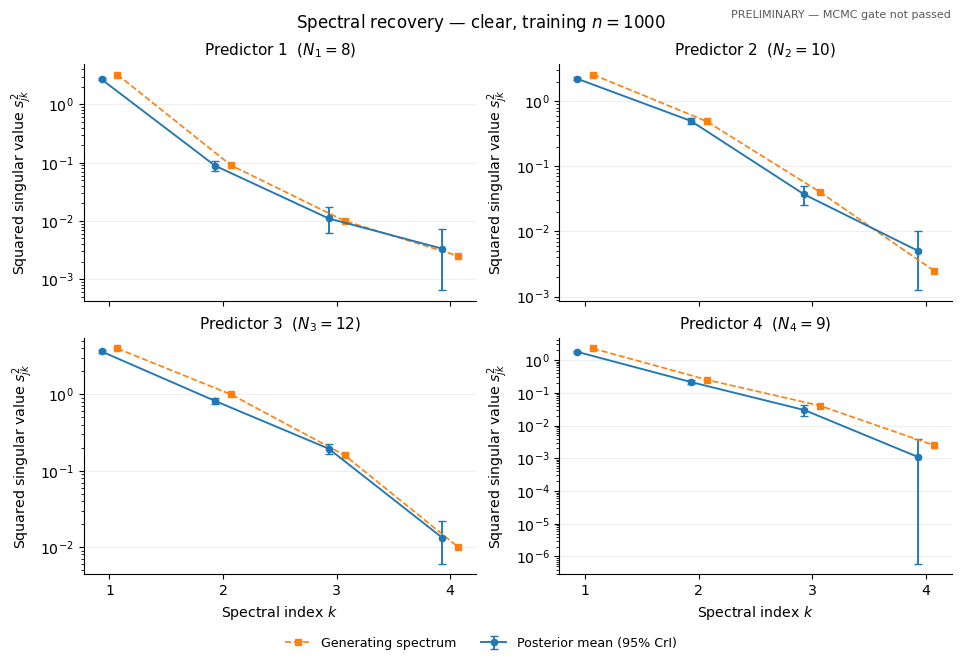

Saved: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures/PRELIMINARY_sim1_clear_risk_budget.png
Saved: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures/PRELIMINARY_sim1_clear_risk_budget.pdf


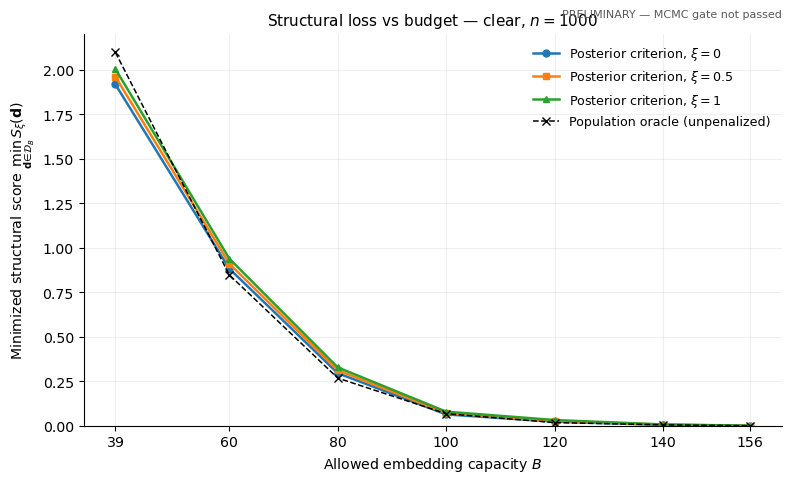

Saved: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures/PRELIMINARY_sim1_clear_allocation_heatmap.png
Saved: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures/PRELIMINARY_sim1_clear_allocation_heatmap.pdf


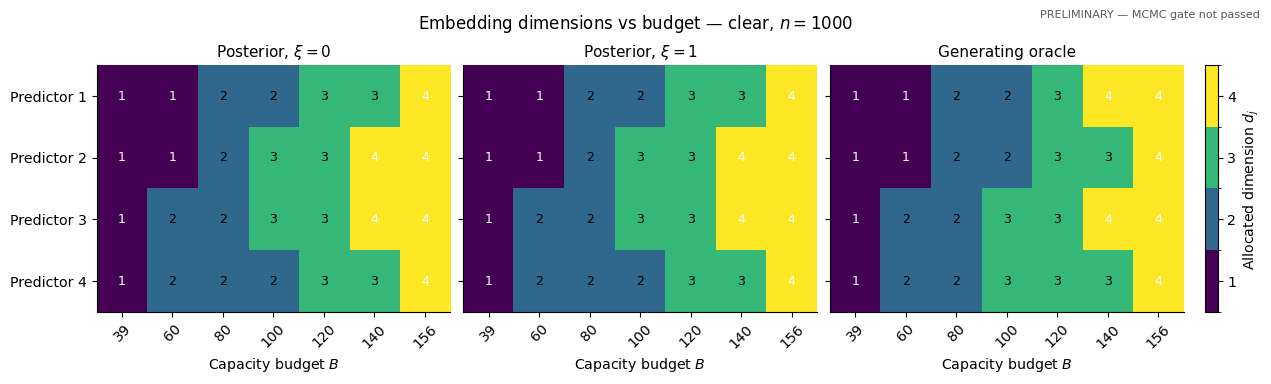

All figures use actual retained posterior samples and generating truth. Risk curves are structural scores, not predictive test losses.
Figure directory: /content/drive/MyDrive/JRSSB_Embedding_Allocation/FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL/Simulation1/diagnostic/paper_figures


In [1]:
# ============================================================================
# SIMULATION 1 — SECOND COLAB CELL: PAPER FIGURES ONLY (NO FITTING / NO MCMC)
# Run after the original cell is interrupted or finishes; or run in a separate
# notebook reading its own trusted Google Drive checkpoint.
# Makes THREE figures if posterior draws remain; TWO summary figures otherwise.
# Saves editable VECTOR PDF and 300-dpi PNG files under Drive/paper_figures.
# ============================================================================
import os, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator

# True categorical level counts and budgets for Simulation 1, matching cell 1.
N_LEVELS = np.array([8, 10, 12, 9], dtype=int)
BUDGETS = [39, 60, 80, 100, 120, 140, 156]
RISK_VALUES = [0.0, 0.5, 1.0]

# If opened in a separate Colab notebook while cell 1 is busy, mount Drive.
if not isinstance(globals().get('STATE'), dict) and not os.path.isdir('/content/drive/MyDrive'):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass  # Outside Colab: use local checkpoints if present.

# Prefer in-memory state, but check the Drive checkpoint too if it contains
# more useful raw draws. Never rerun the first cell or fabricate missing draws.
_candidates = []
if isinstance(globals().get('STATE'), dict):
    _candidates.append(('current runtime', globals()['STATE']))

_known_checkpoints = []
if isinstance(globals().get('CPATH'), str):
    _known_checkpoints.append(globals()['CPATH'])

_drive_root = '/content/drive/MyDrive/JRSSB_Embedding_Allocation'
_local_root = os.path.abspath('./JRSSB_Embedding_Allocation')
for _root in (_drive_root, _local_root):
    for _version in ('FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V5_FAST_EXACT',
                     'FIXED_RANK_HIERARCHICAL_SHRINKAGE_PT_V4_DENSE_TAIL'):
        for _mode in ('diagnostic', 'full'):
            _known_checkpoints.append(os.path.join(_root, _version, 'Simulation1', _mode, 'checkpoint.pkl'))

_seen = set()
for _path in _known_checkpoints:
    if _path in _seen or not os.path.isfile(_path):
        continue
    _seen.add(_path)
    try:
        # Only load checkpoint files you created using YOUR first Colab cell:
        # pickle is unsafe for files from unknown parties.
        with open(_path, 'rb') as _file:
            _obj = pickle.load(_file)
        if isinstance(_obj, dict):
            _candidates.append((_path, _obj))
    except (OSError, EOFError, pickle.UnpicklingError) as _err:
        warnings.warn(f'Could not read {_path}: {_err}')

if not _candidates:
    raise RuntimeError('No Simulation 1 state found. Run this after cell 1, or mount Google Drive to read its saved checkpoint.')

# Prioritize states with more complete posterior draws. For an in-progress
# serial four-ladder run, use the common retained prefix from all four chains.
def _extract_draws(_st):
    _work = _st.get('work') or {}
    _stored = _work.get('posterior_s2')
    if _stored is not None:
        _a = np.asarray(_stored, dtype=float)
        if _a.ndim == 4 and _a.shape[0] == 4 and _a.shape[1] > 0:
            return _a
    _ladders = _work.get('ladders')
    if _ladders and len(_ladders) == 4:
        try:
            _trace = [L['replicas'][0]['traces']['s2'] for L in _ladders]
            _n = min(len(x) for x in _trace)
            if _n >= 30:
                return np.stack([np.asarray(x[:_n], dtype=float) for x in _trace])
        except (KeyError, IndexError, TypeError, ValueError):
            pass
    return None

_raw_states = [(_a, _st, _extract_draws(_st)) for _a, _st in _candidates]
_with_draws = [item for item in _raw_states if item[2] is not None]

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.2,
    'axes.titlesize': 11, 'axes.labelsize': 10.2,
    'legend.fontsize': 9.1, 'savefig.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})

if _with_draws:
    _source, _state, s2 = max(_with_draws, key=lambda item: item[2].shape[1])
else:
    _source, _state, s2 = max(
        _raw_states,
        key=lambda item: len(item[1].get('completed', {})),
    )

work = _state.get('work') or {}
_valid_source_path = _source if isinstance(_source, str) and os.path.isfile(_source) else None
_output_base = (os.path.dirname(_valid_source_path) if _valid_source_path else
                os.path.dirname(globals()['CPATH']) if isinstance(globals().get('CPATH'), str) else
                os.path.join(_local_root, 'Simulation1', 'paper_figures'))
PAPER_FIG_DIR = os.path.join(_output_base, 'paper_figures')
os.makedirs(PAPER_FIG_DIR, exist_ok=True)


def save_figure(fig, stem, preliminary=False):
    name = ('PRELIMINARY_' if preliminary else '') + stem
    png = os.path.join(PAPER_FIG_DIR, name + '.png')
    pdf = os.path.join(PAPER_FIG_DIR, name + '.pdf')
    fig.savefig(png, dpi=300, bbox_inches='tight', pad_inches=0.14)
    fig.savefig(pdf, bbox_inches='tight', pad_inches=0.14)
    print('Saved:', png)
    print('Saved:', pdf)
    plt.show()
    plt.close(fig)


def add_status(fig, preliminary):
    if preliminary:
        fig.text(0.995, 0.996, 'PRELIMINARY — MCMC gate not passed',
                 ha='right', va='top', color='0.35', fontsize=8)


def exact_allocation(scores, budgets=BUDGETS):
    # Same multiple-choice dynamic program and tie handling as Simulation 1.
    m, bmax = len(scores), max(budgets)
    val = np.full((m + 1, bmax + 1), np.inf)
    val[0, 0] = 0.0
    back = np.full((m + 1, bmax + 1), -1, dtype=int)
    for j in range(m):
        for b in range(bmax + 1):
            if not np.isfinite(val[j, b]):
                continue
            for d in range(1, len(scores[j]) + 1):
                b2 = b + N_LEVELS[j] * d
                if b2 <= bmax and val[j, b] + scores[j][d - 1] < val[j + 1, b2]:
                    val[j + 1, b2] = val[j, b] + scores[j][d - 1]
                    back[j + 1, b2] = d
    allocations = {}
    for B in budgets:
        b = int(np.argmin(val[m, :B + 1]))
        if not np.isfinite(val[m, b]):
            raise RuntimeError('Budget has no feasible solution: ' + str(B))
        d = [0] * m
        score = float(val[m, b])
        for j in range(m, 0, -1):
            d[j - 1] = int(back[j, b])
            b -= N_LEVELS[j - 1] * d[j - 1]
        allocations[B] = {'d': tuple(d), 'score': score}
    return allocations


if s2 is not None:
    if s2.shape[2] != 4 or s2.shape[3] < 4:
        raise ValueError(f'Unexpected Simulation 1 spectral tensor shape: {s2.shape}')
    if 'truth' not in work or 'spec' not in work['truth']:
        raise RuntimeError('Posterior draws exist but their paired population spectra are unavailable; cannot plot genuine recovery.')
    truth = [np.asarray(x, dtype=float)[:4]**2 for x in work['truth']['spec']]
    if len(truth) != 4:
        raise RuntimeError('Expected generating spectra for all four predictors.')
    regime = work.get('task', ('1', 'unknown', None, None))[1]
    n_train = work.get('task', ('1', regime, None, None))[2]
    passed = bool(work.get('passed', False))
    # Even if a previous checkpoint was at a complete iteration boundary,
    # figures are preliminary unless the actual convergence gate passed.
    preliminary = not passed
    print(f'Posterior source: {_source}\nScenario: {regime}, n={n_train}; '
          f'chains={s2.shape[0]}, draws/chain={s2.shape[1]}, '
          f'convergence gate passed={passed}')

    # FIGURE 1: per-predictor posterior squared singular values vs true spectra.
    fig, axs = plt.subplots(2, 2, figsize=(9.5, 6.5), sharex=True, layout='constrained')
    k = np.arange(1, 5)
    for j, ax in enumerate(axs.flat):
        samples = s2[:, :, j, :4].reshape(-1, 4)
        center = np.mean(samples, axis=0)
        low, high = np.quantile(samples, [0.025, 0.975], axis=0)
        yerr = np.vstack([np.maximum(center - low, 0), np.maximum(high - center, 0)])
        ax.errorbar(k - 0.07, center, yerr=yerr, fmt='o-', capsize=3,
                    linewidth=1.35, markersize=4.5, label='Posterior mean (95% CrI)')
        ax.plot(k + 0.07, truth[j], 's--', linewidth=1.2, markersize=4.5,
                label='Generating spectrum')
        ax.set_yscale('log')
        ax.set_xticks(k)
        ax.set_title(f'Predictor {j + 1}  ($N_{j+1}={N_LEVELS[j]}$)')
        ax.set_ylabel(r'Squared singular value $s_{jk}^2$')
        ax.grid(axis='y', alpha=0.20)
    for ax in axs[-1]:
        ax.set_xlabel('Spectral index $k$')
    fig.suptitle(f'Spectral recovery — {regime.replace("_", " " )}, training $n={n_train}$', fontsize=12)
    handles, labels = axs.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='outside lower center', ncol=2, frameon=False)
    add_status(fig, preliminary)
    save_figure(fig, f'sim1_{regime}_spectral_recovery', preliminary)

    # Compute posterior tail mean and posterior tail SD EXACTLY as in cell 1.
    flattened = s2.reshape(-1, 4, s2.shape[3])
    allocation_by_xi = {}
    for xi in RISK_VALUES:
        score = []
        for j in range(4):
            v = flattened[:, j, :4]
            sc = []
            for d in range(1, 5):
                tail = v[:, d:4].sum(axis=1)
                sc.append(float(np.mean(tail) + xi * np.std(tail, ddof=1)))
            score.append(sc)
        allocation_by_xi[xi] = exact_allocation(score)
    oracle_scores = [[float(truth[j][d:4].sum()) for d in range(1, 5)]
                     for j in range(4)]
    oracle = exact_allocation(oracle_scores)

    # FIGURE 2: optimized risk-sensitive structural score vs allowed capacity.
    fig, ax = plt.subplots(figsize=(7.8, 4.7), layout='constrained')
    for xi, marker in zip(RISK_VALUES, ('o', 's', '^')):
        aa = allocation_by_xi[xi]
        ax.plot(BUDGETS, [aa[B]['score'] for B in BUDGETS],
                marker=marker, markersize=5, linewidth=1.8,
                label=rf'Posterior criterion, $\xi={xi:g}$')
    ax.plot(BUDGETS, [oracle[B]['score'] for B in BUDGETS],
            color='black', linestyle='--', marker='x', linewidth=1.1,
            label='Population oracle (unpenalized)')
    ax.set_title(f'Structural loss vs budget — {regime.replace("_", " " )}, $n={n_train}$')
    ax.set_xlabel('Allowed embedding capacity $B$')
    ax.set_ylabel(r'Minimized structural score $\min_{\mathbf{d}\in\mathcal{D}_B} S_\xi(\mathbf{d})$')
    ax.set_xticks(BUDGETS)
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
    add_status(fig, preliminary)
    save_figure(fig, f'sim1_{regime}_risk_budget', preliminary)

    # FIGURE 3: allocations vs budget: risk neutral, risk sensitive, true oracle.
    panels = [('Posterior, $\\xi=0$', allocation_by_xi[0.0]),
              ('Posterior, $\\xi=1$', allocation_by_xi[1.0]),
              ('Generating oracle', oracle)]
    cmap = plt.get_cmap('viridis', 4)
    norm = BoundaryNorm(np.arange(0.5, 5.5), 4)
    fig, axs = plt.subplots(1, 3, figsize=(12.6, 3.7), sharex=True, sharey=True,
                            layout='constrained')
    for ax, (ttl, allocations) in zip(axs, panels):
        mat = np.array([allocations[B]['d'] for B in BUDGETS], dtype=int).T
        im = ax.imshow(mat, aspect='auto', cmap=cmap, norm=norm, interpolation='nearest')
        ax.set_title(ttl)
        ax.set_xticks(range(len(BUDGETS)), [str(B) for B in BUDGETS], rotation=45)
        ax.set_yticks(range(4), [f'Predictor {j}' for j in range(1, 5)])
        ax.set_xlabel('Capacity budget $B$')
        for row in range(mat.shape[0]):
            for col in range(mat.shape[1]):
                d = mat[row, col]
                ax.text(col, row, str(d), ha='center', va='center', fontsize=9,
                        color='white' if d in (1, 4) else 'black')
    fig.suptitle(f'Embedding dimensions vs budget — {regime.replace("_", " " )}, $n={n_train}$', fontsize=12)
    cb = fig.colorbar(im, ax=axs, ticks=[1, 2, 3, 4], fraction=0.025, pad=0.02)
    cb.set_label('Allocated dimension $d_j$')
    add_status(fig, preliminary)
    save_figure(fig, f'sim1_{regime}_allocation_heatmap', preliminary)

    print('All figures use actual retained posterior samples and generating truth. '
          'Risk curves are structural scores, not predictive test losses.')

else:
    # Once cell 1 has fully finished a task, it clears STATE["work"] and only
    # stores compact result dictionaries. Plot valid summaries, not invented
    # posterior spectra/allocations. An earlier active checkpoint is needed to
    # create the three full posterior figures above.
    recs = [row for value in _state.get('completed', {}).values()
            for row in (value if isinstance(value, list) else [value])
            if isinstance(row, dict) and row.get('status') == 'OK']
    if not recs:
        raise RuntimeError('No raw posterior draws or completed OK results found. '
                           'Run after sampling has produced a checkpoint containing ladders.')
    df = pd.DataFrame(recs)
    if not {'regime', 'ntrain', 'xi', 'Bsel', 'test_mse', 'ref_test_mse'} <= set(df.columns):
        raise RuntimeError('Completed result rows do not contain the required plotting quantities.')
    df['scenario'] = df['regime'].astype(str) + ', n=' + df['ntrain'].astype(str)
    means = df.groupby(['scenario', 'xi'], as_index=False).agg(
        budget_mean=('Bsel', 'mean'), test_mean=('test_mse', 'mean'),
        reference_mean=('ref_test_mse', 'mean'), n=('Bsel', 'size'))
    print('Only compact completed summaries are available; creating two valid '
          'summary figures (full posterior figures require an active MCMC checkpoint).')
    fig, ax = plt.subplots(figsize=(7.8, 4.6), layout='constrained')
    for sc, group in means.groupby('scenario', sort=True):
        ax.plot(group['xi'], group['budget_mean'], 'o-', linewidth=1.6, label=sc)
    ax.set_xticks(RISK_VALUES)
    ax.set_xlabel(r'Uncertainty penalty $\xi$')
    ax.set_ylabel('Mean validation-selected capacity budget')
    ax.grid(alpha=.2)
    ax.legend(frameon=False, fontsize=8)
    save_figure(fig, 'sim1_summary_selected_budget')

    fig, ax = plt.subplots(figsize=(7.8, 4.6), layout='constrained')
    for sc, group in means.groupby('scenario', sort=True):
        line, = ax.plot(group['xi'], group['test_mean'], 'o-', linewidth=1.6,
                        label=sc + ' (selected)')
        ax.plot(group['xi'], group['reference_mean'], ':', linewidth=1.3,
                color=line.get_color(), label=sc + ' (reference)')
    ax.set_xticks(RISK_VALUES)
    ax.set_xlabel(r'Uncertainty penalty $\xi$')
    ax.set_ylabel('Test MSE')
    ax.grid(alpha=.2)
    ax.legend(frameon=False, fontsize=8)
    save_figure(fig, 'sim1_summary_test_mse')

print('Figure directory:', PAPER_FIG_DIR)


In [ ]:
# SIMULATION 1 V9 — 100-INDEPENDENT-REPLICATION GPU/CPU HYBRID, ONE COLAB CELL
# Posterior model: EXACTLY V7 fixed-K hierarchical-Beta spectral posterior.
# Predictive models: V8 SVD warm starts + validation-only selection.
# Accelerations: GPU neural training, CPU Numba likelihood-only evaluator,
# short exact parallel-tempering ladders with strict checks and original V7 PT fallback.
# No power posterior approximation, no likelihood subsampling, no relaxed diagnostics.
# Dataset seeds independent across 100 replications per scenario. One cell only.
# =============================== USER SETTINGS ===============================
N_REPLICATIONS = 100      # 100 per regime -> 200 independent datasets for default settings
REGIMES = ('clear','weak')
NTRAIN_SET = (1000,)       # for full 600-dataset design use (500,1000,2000)
REQUIRE_GPU = True        # in Google Colab: Runtime > Change runtime type > T4 GPU
RISK_XI = (0.,0.5,1.)
N_CHAINS = 4
PT_TEMPS_FAST = 3
PT_BETA_MIN_FAST = 0.72
PT_TEMPS_FALLBACK = 12  # proven V7 ladder if fast stage does not converge
PT_BETA_MIN_FALLBACK = 0.20
AUTO_FALLBACK = True      # no pooling across incompatible MCMC runs
MCMC_BASE = 4500
MCMC_EXTEND = 2500
MCMC_MAX = 14500
MCMC_MAX_FALLBACK = 24000
MCMC_BURN = 1800
MCMC_THIN = 2
RHAT_LIMIT = 1.01
ESS_BULK_MIN = 400
ESS_TAIL_MIN = 400
REFERENCE_EPOCHS = 1800  # V7 diagnostics' successful reference schedule
REFERENCE_RESTARTS = 5
REFERENCE_ADAM_LR = .005
REDUCED_MAX_EPOCHS = 1400
REDUCED_EVAL_EVERY = 20
REDUCED_PATIENCE = 260
REDUCED_LR = .003
REDUCED_WEIGHT_DECAY = 5e-5
RISK_TOLERANCE = .0015
STOP_ON_FIRST_FAILURE = False   # preserve FAILED status and continue independent tasks
CHECKPOINT_SECONDS = 15 * 60
PT_SWAP_EVERY = 2
PT_ADAPT_EVERY = 100
PT_TARGET_SWAP = 0.25
PT_MIN_SWAP_WARN = .08
PT_GLOBAL_MOVE_EVERY = 5
PT_HOT_SWEEP_EVERY = 2
PT_SPECTRAL_BLOCK_EVERY = 3
PT_COUPLED_TAIL_EVERY = 4
PT_LEADING_PAIR_EVERY = 2
PT_FOCUS_PAIR_EXTRA = 1
PT_REGRESSION_EXTRA_EVERY = 3
REFERENCE_PREFLIGHT_ONLY = False
RUN_FULL = False  # preserved for compatibility; N_REPLICATIONS/NTRAIN_SET control design
SIMULATIONS = ('1',)
REQUIRE_CONVERGENCE = True
# ===========================================================================
import os, time, json, pickle, random, hashlib, gc, math, warnings, shutil, traceback, copy, contextlib, io
from datetime import datetime
import numpy as np
import pandas as pd
from scipy.special import expit, log_expit, gammaln, betaln, ndtr, ndtri, betainc, betaincinv, gammainc, gammaincinv
from threadpoolctl import threadpool_limits
_BLAS_THREAD_LIMIT=threadpool_limits(limits=1,user_api='blas')
try:
    from numba import njit
    HAVE_NUMBA=True
except ImportError:
    HAVE_NUMBA=False
    njit=None
import torch
from torch import nn
from torch.nn import functional as F
try:
    import arviz as az
except ImportError:
    import subprocess,sys
    subprocess.check_call([sys.executable,'-m','pip','-q','install','arviz'])
    import arviz as az
warnings.filterwarnings('ignore',category=FutureWarning)
if REQUIRE_GPU and not torch.cuda.is_available():
    raise RuntimeError('GPU REQUIRED. In Google Colab choose Runtime > Change runtime type > T4 GPU, then rerun. For explicit local CPU tests set REQUIRE_GPU=False.')
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type=='cuda':
    print('GPU:',torch.cuda.get_device_name(0), '| GPU used for reference and reduced network training.',flush=True)
else: print('CPU local mode: GPU not available',flush=True)
torch.set_num_threads(max(1,min(4,os.cpu_count() or 1)))
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT='/content/drive/MyDrive/JRSSB_Embedding_Allocation/SIM1_V9_100REPS_GPU_CPU_EXACT'
except ImportError:
    ROOT=os.path.abspath('./JRSSB_Embedding_Allocation/SIM1_V9_100REPS_GPU_CPU_EXACT')
RUN_DIR=os.path.join(ROOT,'Simulation1','100replications')
os.makedirs(RUN_DIR,exist_ok=True)
os.makedirs(os.path.join(RUN_DIR,'diagnostics'),exist_ok=True)
CPATH=os.path.join(RUN_DIR,'checkpoint.pkl')
PT_TEMPS=PT_TEMPS_FAST
PT_MIN_BETA=PT_BETA_MIN_FAST
config=dict(version='sim1_v9_GPU_CPU_100reps_V7posterior_V8refit',replications=N_REPLICATIONS,
            regimes=REGIMES,ntrain_set=NTRAIN_SET,chains=N_CHAINS,temper_fast=(PT_TEMPS_FAST,PT_BETA_MIN_FAST),
            temper_fallback=(PT_TEMPS_FALLBACK,PT_BETA_MIN_FALLBACK),auto_fallback=AUTO_FALLBACK,
            iters=(MCMC_BASE,MCMC_EXTEND,MCMC_MAX,MCMC_MAX_FALLBACK,MCMC_BURN,MCMC_THIN),
            thresholds=(RHAT_LIMIT,ESS_BULK_MIN,ESS_TAIL_MIN),
            ref_training=(REFERENCE_EPOCHS,REFERENCE_RESTARTS,REFERENCE_ADAM_LR),
            reduced_training=(REDUCED_MAX_EPOCHS,REDUCED_EVAL_EVERY,REDUCED_PATIENCE,REDUCED_LR,REDUCED_WEIGHT_DECAY),
            pt_updates=(PT_SWAP_EVERY,PT_ADAPT_EVERY,PT_GLOBAL_MOVE_EVERY,PT_HOT_SWEEP_EVERY,
                         PT_SPECTRAL_BLOCK_EVERY,PT_COUPLED_TAIL_EVERY,PT_LEADING_PAIR_EVERY,
                         PT_FOCUS_PAIR_EXTRA,PT_REGRESSION_EXTRA_EVERY),
            risk_xi=RISK_XI,zeta=RISK_TOLERANCE,device_type=DEVICE.type)
SIGNATURE=hashlib.sha256(json.dumps(config,sort_keys=True).encode()).hexdigest()
print('\nSIMULATION 1 — 100 REPLICATIONS |',RUN_DIR)
print('[1] START NEW 100-REPLICATION EXPERIMENT (archives V9 checkpoint)')
print('[2] RESUME V9 CHECKPOINT (all completed tasks skipped)')
while True:
    MODE=input('Enter 1 or 2: ').strip()
    if MODE=='1' or (MODE=='2' and os.path.isfile(CPATH)): break
    print('Resume requires the existing V9 checkpoint. Select 1 for first run.')
if MODE=='1':
    if os.path.isfile(CPATH):
        archive=os.path.join(RUN_DIR,'archive_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
        os.makedirs(archive,exist_ok=True)
        shutil.move(CPATH,os.path.join(archive,'checkpoint.pkl'))
        print('Archived previous V9 checkpoint at',archive)
    STATE=dict(signature=SIGNATURE,completed={},work={},created=datetime.now().isoformat(),task_name=None)
else:
    with open(CPATH,'rb') as f: STATE=pickle.load(f)
    if STATE.get('signature')!=SIGNATURE:raise RuntimeError('V9 signature mismatch. Restore settings or start new run.')
    print('RESUMED:',len(STATE['completed']),'completed dataset tasks; current=',STATE.get('task_name'))
LAST_SAVE=time.monotonic()
def atomic_checkpoint(force=False):
    global LAST_SAVE
    if not force and time.monotonic()-LAST_SAVE<CHECKPOINT_SECONDS:return
    temp=CPATH+'.tmp'
    with open(temp,'wb') as f:
        pickle.dump(STATE,f,protocol=pickle.HIGHEST_PROTOCOL)
        f.flush();os.fsync(f.fileno())
    os.replace(temp,CPATH)
    LAST_SAVE=time.monotonic()
    if force:print(' [V9 CHECKPOINT]',datetime.now().strftime('%H:%M:%S'), '| task phase:',STATE.get('work',{}).get('phase'),flush=True)
def seed_all(seed):
    np.random.seed(seed);random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def orthogonal(k,rng):
    q,r=np.linalg.qr(rng.normal(size=(k,k)))
    return q * np.where(np.diag(r)>=0,1.,-1.)

def centered_orth(n,k,rng):
    a=rng.normal(size=(n,k));a-=a.mean(axis=0,keepdims=True)
    return np.linalg.qr(a)[0][:,:k]

def make_theta(n,pz,singular,rng):
    k=min(n-1,pz)
    t=centered_orth(n,k,rng) @ np.diag(np.asarray(singular[:k])) @ orthogonal(pz,rng)[:,:k].T
    return t-t.mean(axis=0,keepdims=True)

def setup(sim):
    if sim=='1':
        nlev=[8,10,12,9];pz=4;q=4;pu=2
        scen=[(f'{regime}_n{n}',regime,n) for regime in ('clear','weak') for n in (500,1000,2000)]
        scen=[x for x in scen if x[1] in REGIMES and x[2] in NTRAIN_SET]
        budgets=[sum(nlev),60,80,100,120,140,pz*sum(nlev)];num_reps=N_REPLICATIONS
    else:
        nlev=[3,5,8,4,10,6,7,12,5,9,4,11];pz=5;q=5;pu=3
        scen=[(r,r,1200) for r in ('heterogeneous','near_homogeneous')]
        budgets=[sum(nlev),125,170,215,255,300,340,sum(x*min(x-1,pz) for x in nlev)]
        num_reps=50 if RUN_FULL else 1
    klist=[min(n-1,pz) for n in nlev]
    bases=[]
    for n in nlev:
        _,_,vt=np.linalg.svd(np.ones((1,n)),full_matrices=True)
        bases.append(vt[1:,:].T.copy())
    return dict(sim=sim,nlev=nlev,m=len(nlev),pz=pz,q=q,pu=pu,klist=klist,bases=bases,
                scenarios=scen,budgets=sorted(set(budgets)),num_reps=num_reps,
                n_val=500,n_test=(3000 if sim=='1' else 4000), noise_sd=.1,
                ref_epochs=REFERENCE_EPOCHS,red_epochs=REDUCED_MAX_EPOCHS,
                ref_restarts=REFERENCE_RESTARTS,red_restarts=1)

CFG=None

def teacher(sim):
    rng=np.random.default_rng(8877 if sim=='1' else 90210)
    p=CFG['pz']
    if sim=='1':b1=np.array([.1,-.1,.05,-.05]);b2=np.array([.05,-.05,.05,-.05])
    else:b1=np.array([.1,-.05,.05,-.1,.05]);b2=np.array([.05,-.05,.05,0,-.05])
    return [(orthogonal(p,rng),b1),(orthogonal(p,rng),b2)]

def target(regime):
    c=CFG; sim=c['sim'];m=c['m'];nlev=c['nlev'];klist=c['klist']
    rng=np.random.default_rng(12345 if sim=='1' else 4567)
    if sim=='1':
        raw=([[1.8,.3,.1,.05],[1.6,.7,.2,.05],[2.,1.,.4,.1],[1.5,.5,.2,.05]] if regime=='clear'
             else [[1.8,1.2,.9,.6],[1.6,1.3,1.,.7],[2.,1.6,1.3,1.],[1.5,1.1,.85,.6]])
        spec=[np.array(raw[j][:klist[j]]) for j in range(m)]
        g=rng.normal(scale=.2,size=(c['pu'],c['pz']));mu=np.array([.1,-.1,.05,-.05]);dtrue=None
    else:
        dims={'heterogeneous':(1,4,2,1,4,2,3,1,2,4,1,3),
              'near_homogeneous':(2,)*12}[regime]
        strong=np.array([1.35,1.1,.85,.6,.45]);spec=[]
        for j in range(m):
            sc=np.sqrt(nlev[j]/np.median(nlev))*(1.+.015*(j-(m-1)/2))
            sj=np.zeros(klist[j]);sj[:dims[j]]=strong[:dims[j]]*sc;spec.append(sj)
        g=rng.normal(scale=.15,size=(c['pu'],c['pz']));mu=np.array([.1,-.05,.05,.05,-.05]);dtrue=dims
    t=[make_theta(nlev[j],c['pz'],spec[j],rng) for j in range(m)]
    return dict(theta=t,gamma=g,mu=mu,spec=spec,dtrue=dtrue)

def phi(z,weights):
    (w1,b1),(w2,b2)=weights
    return np.tanh(z @ w1.T + b1) @ w2.T + b2

# The Bayesian target is still the original collapsed Gaussian likelihood.
# Numba only fuses the MLP forward pass and squared-error accumulation;
# fastmath=False deliberately avoids algebraic reassociation optimizations.
if HAVE_NUMBA:
    @njit(cache=False,fastmath=False)
    def _fused_ll_kernel(z,Y,w1,b1,w2,b2,siga,sigb):
        n=z.shape[0]; nh=w1.shape[0]; q=Y.shape[1]
        yh=np.empty((n,q),dtype=np.float64)
        h=np.empty(nh,dtype=np.float64)
        rss=0.0
        for i in range(n):
            for a in range(nh):
                t=b1[a]
                for k in range(z.shape[1]):t+=z[i,k]*w1[a,k]
                h[a]=np.tanh(t)
            for b in range(q):
                y=b2[b]
                for a in range(nh):y+=h[a]*w2[b,a]
                yh[i,b]=y
                d=Y[i,b]-y
                rss+=d*d
        return yh,-(siga+0.5*(n*q))*np.log(sigb+0.5*rss)
else:
    _fused_ll_kernel=None

_FAST_COMPILED=False
_BACKEND_TUNED=False

def posterior_eval(z,Y,omega):
    global _FAST_COMPILED,_BACKEND_TUNED
    # Once per Colab run, benchmark BOTH mathematically identical evaluators at
    # the real sample size, then keep whichever is faster for posterior MCMC.
    # Compilation, if applicable, happens outside the timed loops.
    if not _BACKEND_TUNED:
        _BACKEND_TUNED=True
        if HAVE_NUMBA:
            try:
                (w1,b1),(w2,b2)=omega
                y_fast,l_fast=_fused_ll_kernel(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
                y_np=phi(z,omega);l_np=loglik(Y,y_np)
                if not (np.allclose(y_fast,y_np,atol=1e-11,rtol=1e-11)
                        and np.isclose(l_fast,l_np,atol=1e-8,rtol=1e-12)):
                    raise ArithmeticError('Compiled likelihood differs from NumPy reference')
                # Five batches of 20 calls reduce timing noise without adding
                # meaningful overhead relative to thousands of MCMC sweeps.
                numpy_times=[];numba_times=[]
                for _ in range(5):
                    start=time.perf_counter()
                    for __ in range(20):
                        y_np=phi(z,omega);l_np=loglik(Y,y_np)
                    numpy_times.append(time.perf_counter()-start)
                    start=time.perf_counter()
                    for __ in range(20):
                        y_fast,l_fast=_fused_ll_kernel(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
                    numba_times.append(time.perf_counter()-start)
                np_s=np.median(numpy_times);jit_s=np.median(numba_times)
                _FAST_COMPILED=bool(jit_s<np_s)
                print('Posterior likelihood auto-benchmark | NumPy %.4g s, Numba %.4g s / 20 calls; using %s'
                      %(np_s,jit_s,'Numba' if _FAST_COMPILED else 'NumPy'),flush=True)
            except Exception as e:
                _FAST_COMPILED=False
                print('JIT evaluator unavailable; reference NumPy evaluator retained:',repr(e),flush=True)
        else:
            print('Numba unavailable: using exact NumPy evaluator.',flush=True)
    if _FAST_COMPILED:
        (w1,b1),(w2,b2)=omega
        return _fused_ll_kernel(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
    yh=phi(z,omega)
    return yh,loglik(Y,yh)


# EXACT FUSED LIKELIHOOD-ONLY EVALUATOR: no candidate predictions allocated.
# Recomputes original likelihood once for each accepted MCMC sweep and checks parity.
if HAVE_NUMBA:
    @njit(cache=False,fastmath=False)
    def _fused_loglik_only(z,Y,w1,b1,w2,b2,siga,sigb):
        n=z.shape[0];h=np.empty(w1.shape[0]);rss=0.
        for i in range(n):
            for a in range(w1.shape[0]):
                zval=b1[a]
                for k in range(z.shape[1]):zval+=z[i,k]*w1[a,k]
                h[a]=math.tanh(zval)
            for b in range(Y.shape[1]):
                v=b2[b]
                for a in range(w1.shape[0]):v+=h[a]*w2[b,a]
                err=Y[i,b]-v
                rss+=err*err
        return -(siga+0.5*(n*Y.shape[1]))*math.log(sigb+0.5*rss)
else: _fused_loglik_only=None
_LL_ONLY_VALIDATED=False
_LL_ONLY_BACKEND='numpy'

def posterior_loglik(z,Y,omega):
    """Return the ORIGINAL collapsed likelihood, using the locally fastest verified backend."""
    global _LL_ONLY_VALIDATED,_LL_ONLY_BACKEND
    if HAVE_NUMBA and not _LL_ONLY_VALIDATED:
        (w1,b1),(w2,b2)=omega
        compiled=float(_fused_loglik_only(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B))
        reference=loglik(Y,phi(z,omega))
        if not np.isclose(compiled,reference,atol=1e-7,rtol=1e-12):
            raise ArithmeticError('Compiled likelihood differs from exact posterior likelihood')
        import time as _benchclock
        nbench=100
        start=_benchclock.perf_counter()
        for _ in range(nbench):
            loglik(Y,phi(z,omega))
        numpy_time=(_benchclock.perf_counter()-start)/nbench
        start=_benchclock.perf_counter()
        for _ in range(nbench):
            _fused_loglik_only(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B)
        jit_time=(_benchclock.perf_counter()-start)/nbench
        _LL_ONLY_BACKEND='numba' if jit_time<.98*numpy_time else 'numpy'
        _LL_ONLY_VALIDATED=True
        print('Exact candidate likelihood backend:',_LL_ONLY_BACKEND,
              '| numpy %.2f us vs numba %.2f us'%(1e6*numpy_time,1e6*jit_time),flush=True)
    if _LL_ONLY_BACKEND=='numba':
        w1,b1=omega[0];w2,b2=omega[1]
        return float(_fused_loglik_only(z,Y,w1,b1,w2,b2,SIGMA_A,SIGMA_B))
    return loglik(Y,phi(z,omega))

def data(n,truth,weights,seed):
    c=CFG;rng=np.random.default_rng(seed)
    C=[rng.integers(0,c['nlev'][j],size=n) for j in range(c['m'])]
    U=rng.normal(size=(n,c['pu']))
    z=np.broadcast_to(truth['mu'],(n,c['pz'])).copy()+U@truth['gamma']
    for j in range(c['m']):z+=truth['theta'][j][C[j]]
    mean=phi(z,weights);Y=mean+c['noise_sd']*rng.normal(size=mean.shape)
    return C,U,Y

class Reference(nn.Module):
    def __init__(self):
        super().__init__();c=CFG
        self.emb=nn.ModuleList([nn.Embedding(n,c['pz']) for n in c['nlev']])
        for e in self.emb:nn.init.normal_(e.weight,std=.1 if c['sim']=='1' else .05)
        self.gamma=nn.Parameter(.08*torch.randn(c['pu'],c['pz']));self.mu=nn.Parameter(torch.zeros(c['pz']))
        self.l1=nn.Linear(c['pz'],c['pz']);self.l2=nn.Linear(c['pz'],c['q'])
        with torch.no_grad():
            for l in (self.l1,self.l2): l.weight.copy_(torch.linalg.qr(torch.randn(*l.weight.shape))[0]);l.bias.zero_()
    def forward(self,C,U):
        z=self.mu+U@self.gamma
        for j,e in enumerate(self.emb):z=z+e(C[j])
        return self.l2(torch.tanh(self.l1(z)))
    @torch.no_grad()
    def project(self):
        for e in self.emb:e.weight-=e.weight.mean(0,keepdim=True)
        for l in (self.l1,self.l2):
            a,_,v=torch.linalg.svd(l.weight,full_matrices=False);l.weight.copy_(a@v)

class Reduced(nn.Module):
    def __init__(self,d):
        super().__init__();c=CFG;self.d=d
        self.emb=nn.ModuleList([nn.Embedding(c['nlev'][j],d[j]) for j in range(c['m'])])
        for e in self.emb:nn.init.normal_(e.weight,std=.1)
        self.gamma=nn.Parameter(.08*torch.randn(c['pu'],c['pz']));self.mu=nn.Parameter(torch.zeros(c['pz']))
        self.l1=nn.Linear(sum(d)+c['pz'],c['pz']);self.l2=nn.Linear(c['pz'],c['q'])
    def forward(self,C,U):
        z=torch.cat([e(C[j]) for j,e in enumerate(self.emb)]+[self.mu+U@self.gamma],dim=1)
        return self.l2(torch.tanh(self.l1(z)))
    @torch.no_grad()
    def project(self):
        for e in self.emb:e.weight-=e.weight.mean(0,keepdim=True)

def tensors(t):
    C,U,Y=t
    return ([torch.as_tensor(z,dtype=torch.long,device=DEVICE) for z in C],
            torch.as_tensor(U,dtype=torch.float32,device=DEVICE),
            torch.as_tensor(Y,dtype=torch.float32,device=DEVICE))

def fit_model(train,kind,seed,d=None):
    c=CFG;C,U,Y=tensors(train)
    best=None;bestloss=np.inf
    restarts=c['ref_restarts'] if kind=='reference' else c['red_restarts']
    epochs=c['ref_epochs'] if kind=='reference' else c['red_epochs']
    for r in range(restarts):
        seed_all(seed+1000*r)
        net=(Reference() if kind=='reference' else Reduced(d)).to(DEVICE)
        opt=torch.optim.Adam(net.parameters(),lr=(REFERENCE_ADAM_LR if kind=='reference' else .005),weight_decay=5e-5 if kind=='reference' else 5e-4)
        for ep in range(epochs):
            opt.zero_grad();loss=F.mse_loss(net(C,U),Y);loss.backward()
            torch.nn.utils.clip_grad_norm_(net.parameters(),5.);opt.step();net.project()
            if ep%50==0:atomic_checkpoint()
        with torch.no_grad():result=float(F.mse_loss(net(C,U),Y).item())
        if result<bestloss:
            bestloss=result;best=net
        else:del net
    if kind=='reference':
        print(f'  REFERENCE FIT epochs={epochs} restarts={restarts} train MSE={bestloss:.6f}',flush=True)
    else:
        print(f'  {kind} d={d} training MSE={bestloss:.6f}',flush=True)
    return best,bestloss

def predict(net,dt):
    C,U,Y=tensors(dt)
    with torch.no_grad():return net(C,U).detach().cpu().numpy()

def reference_parameters(net):
    with torch.no_grad():
        th=[e.weight.detach().cpu().numpy().astype(float).copy() for e in net.emb]
        th=[v-v.mean(0,keepdims=True) for v in th]
        g=net.gamma.detach().cpu().numpy().astype(float).copy()
        mu=net.mu.detach().cpu().numpy().astype(float).copy()
        w=[(l.weight.detach().cpu().numpy().astype(float).copy(),l.bias.detach().cpu().numpy().astype(float).copy())
           for l in (net.l1,net.l2)]
    return dict(theta=th,gamma=g,mu=mu,omega=w)

def mse(y,yhat):return float(np.mean((y-yhat)**2))

def report_reference_anchor(net,train,validation,test,truth,teacher_weights):
    """Simulation-only reference/teacher comparison; results NEVER used to fit or select the anchor.

    Teacher is inaccessible in an empirical application. These diagnostics establish
    whether failures originate in reference optimization or in posterior inference.
    """
    c=CFG
    estimated=reference_parameters(net)
    print('REFERENCE ANCHOR QUALITY (diagnostic only; no oracle information enters training):',flush=True)
    for name,dt in [('TRAIN',train),('VALIDATION',validation),('TEST',test)]:
        C,U,Y=dt
        z=np.broadcast_to(truth['mu'],(len(Y),c['pz'])).copy()+U@truth['gamma']
        for j in range(c['m']):z+=truth['theta'][j][C[j]]
        fitted_loss=mse(Y,predict(net,dt))
        generating_loss=mse(Y,phi(z,teacher_weights))
        print(f'  {name}: fitted reference MSE={fitted_loss:.6f}, '
              f'generating mean MSE={generating_loss:.6f}, '
              f'known noise variance={c["noise_sd"]**2:.6f}',flush=True)
    print('  GENERATING-vs-FITTED-REFERENCE SQUARED SINGULAR VALUES:',flush=True)
    for j in range(c['m']):
        actual=np.asarray(truth['spec'][j],dtype=float)**2
        recovered=np.linalg.svd(estimated['theta'][j],compute_uv=False)**2
        print(f'    j={j+1}: generating={np.round(actual,5).tolist()} '
              f'fitted_anchor={np.round(recovered,5).tolist()} '
              f'signed_relative_total_error={(recovered.sum()-actual.sum())/max(actual.sum(),1e-12):+.2%}',flush=True)
    return estimated


# ---- Fixed-dimension posterior with integrated inverse-Gamma noise variance ----
S1A,S1B=2.,1.
A0,B0,POOL,AK,BK=2.,2.,4.,2.,1.
TAUG,TAUM=2.5,2.5
SIGMA_A,SIGMA_B=2.5,.02

def cliplogit(p):
    p=np.clip(p,1e-12,1-1e-12)
    return np.log(p)-np.log1p(-p)

def log_beta_logit(v,a,b):
    # Correct Jacobian: log Beta density on rho plus log |d rho / d v|.
    if a<=0 or b<=0:return -np.inf
    return float(a*log_expit(v)+b*log_expit(-v)-betaln(a,b))

def log_gamma_log(v,a,b):
    if abs(v)>50:return -np.inf
    return float(a*v-b*np.exp(v)+a*np.log(b)-gammaln(a))

def qr_haar(a):
    q,r=np.linalg.qr(a,mode='reduced')
    return q*np.where(np.diag(r)>=0.,1.,-1.)

def theta_from(s,j,refresh=None):
    # Deterministic QR cache: refresh precisely when its corresponding
    # Gaussian auxiliary changes, including inside rejected proposals.
    c=CFG;K=c['klist'][j]
    if refresh in ('A','AB') or '_U' not in s:
        s['_U']=qr_haar(s['A'])[:,:K]
    if refresh in ('B','AB') or '_V' not in s:
        s['_V']=qr_haar(s['B'])[:,:K]
    eig=np.empty(K);eig[0]=np.exp(s['x'])
    for h in range(1,K):eig[h]=eig[h-1]*expit(s['eta'][h-1])
    t=(c['bases'][j]@s['_U'])@np.diag(np.sqrt(eig))@s['_V'].T
    return t-t.mean(0,keepdims=True),eig

def start_spectrum(theta,j,rng,spread=1.0):
    c=CFG;K=c['klist'][j]
    u,sv,vt=np.linalg.svd(theta-theta.mean(0),full_matrices=False)
    s2=np.maximum(sv[:K]**2,1e-7)
    s2=np.minimum.accumulate(s2)
    A=c['bases'][j].T@u[:,:K];B=vt.T[:,:K]
    A=A+(0.05*spread)*rng.normal(size=A.shape);B=B+(0.05*spread)*rng.normal(size=B.shape)
    return dict(A=A,B=B,x=float(np.log(s2[0])+rng.normal(scale=.15*spread)),
                eta=cliplogit(np.clip(s2[1:]/s2[:-1],.001,.999))+rng.normal(scale=.3*spread,size=K-1))

def loglik(Y, yh):
    resid=Y-yh;return float(-(SIGMA_A+.5*Y.size)*np.log(SIGMA_B+.5*np.sum(resid*resid)))

def draw_sigma2(Y,yh,rng):
    a=SIGMA_A+.5*Y.size;b=SIGMA_B+.5*np.sum((Y-yh)**2)
    return float(1./rng.gamma(a,1./b))

def ess_block(current,log_L,rng,prior_sd=1.,max_evals=300):
    # Elliptical slice; valid for zero-mean isotropic Gaussian prior coordinates.
    nu=prior_sd*rng.normal(size=current.shape)
    level=log_L(current)+np.log(rng.random())
    angle=rng.uniform(0.,2*np.pi);low=angle-2*np.pi;high=angle
    for evaluations in range(1,max_evals+1):
        proposed=current*np.cos(angle)+nu*np.sin(angle)
        if log_L(proposed)>=level:return proposed,evaluations
        if angle<0:low=angle
        else:high=angle
        angle=rng.uniform(low,high)
    raise RuntimeError('Elliptical slice exceeded bracket budget; stop and inspect sampler.')

def slice1(x,ld,rng,w=.5,max_evals=400):
    current=ld(x)
    if not np.isfinite(current):raise FloatingPointError('Nonfinite current log density in slice sampler.')
    level=current+np.log(rng.random());offset=rng.random()
    L=x-w*offset;R=L+w
    J=int(rng.integers(20));K=19-J; ne=0
    while J>0 and ld(L)>level:L-=w;J-=1;ne+=1
    while K>0 and ld(R)>level:R+=w;K-=1;ne+=1
    for t in range(max_evals):
        xnew=rng.uniform(L,R);v=ld(xnew);ne+=1
        if v>=level:return float(xnew),ne
        if xnew<x:L=xnew
        else:R=xnew
    raise RuntimeError('Scalar slice exceeded shrinkage budget.')

def current_hyper(h):
    return expit(h['z0']),expit(h['zj']),np.exp(h['lk'])

def hierarchical_logprior(h,states):
    means0,means,kappa=current_hyper(h)
    if not np.isfinite(kappa) or kappa>1e5:return -np.inf
    lp=log_beta_logit(h['z0'],A0,B0)+log_gamma_log(h['lk'],AK,BK)
    for j in range(CFG['m']):
        lp+=log_beta_logit(h['zj'][j],POOL*means0,POOL*(1-means0))
        a=kappa*means[j];b=kappa*(1-means[j])
        for eta in states[j]['eta']:
            lp+=log_beta_logit(eta,a,b)
    return float(lp)


def _z0_log_cond(v,h):
    base=expit(v)
    aa=POOL*base;bb=POOL*(1.-base)
    z=h['zj']
    return float(log_beta_logit(v,A0,B0)+np.sum(aa*log_expit(z)+bb*log_expit(-z))-len(z)*betaln(aa,bb))
def _zj_log_cond(v,j,h,states):
    mean=expit(v);base=expit(h['z0']);kap=np.exp(h['lk'])
    aa=kap*mean;bb=kap*(1.-mean);eta=states[j]['eta']
    return float(log_beta_logit(v,POOL*base,POOL*(1.-base))+
                 np.sum(aa*log_expit(eta)+bb*log_expit(-eta))-len(eta)*betaln(aa,bb))
def _lk_log_cond(v,h,states):
    if abs(v)>50:return -np.inf
    kap=np.exp(v)
    if not np.isfinite(kap) or kap>1e5:return -np.inf
    means=expit(h['zj'])
    lp=log_gamma_log(v,AK,BK)
    for j,st in enumerate(states):
        aa=kap*means[j];bb=kap*(1.-means[j]);eta=st['eta']
        lp+=float(np.sum(aa*log_expit(eta)+bb*log_expit(-eta))-len(eta)*betaln(aa,bb))
    return float(lp)

def start_chain(ref,train,seed,spread=1.0):
    C,U,Y=train;rng=np.random.default_rng(seed)
    s=[start_spectrum(ref['theta'][j],j,rng,spread=spread) for j in range(CFG['m'])]
    th=[theta_from(s[j],j)[0] for j in range(CFG['m'])]
    g=ref['gamma'].copy()+(0.025*spread)*rng.normal(size=ref['gamma'].shape)
    mu=ref['mu'].copy()+(0.025*spread)*rng.normal(size=ref['mu'].shape)
    z=mu+U@g
    for j in range(CFG['m']):z+=th[j][C[j]]
    yh,ll=posterior_eval(z,Y,ref['omega'])
    h=dict(z0=float(cliplogit(rng.beta(2,2))),
           zj=cliplogit(np.clip(rng.beta(4,4,size=CFG['m']),.001,.999)),
           lk=float(np.log(rng.gamma(2,1))))
    return dict(it=0,rng=rng,s=s,th=th,g=g,mu=mu,z=z,yh=yh,ll=ll,h=h,
                traces={'s2':[],'bar':[],'bar0':[],'kappa':[],'sigma2':[],'ll':[],
                        'gamma':[],'mu':[]},
                effort=np.zeros((CFG['m'],3),dtype=np.int64),
                updates=np.zeros((CFG['m'],3),dtype=np.int64),
                h_effort=np.zeros(3,dtype=np.int64),h_updates=np.zeros(3,dtype=np.int64),
                 joint_effort=0,joint_updates=0,global_effort=0,global_updates=0,
                 spectral_block_evals=np.zeros(CFG['m'],dtype=np.int64),
                 spectral_block_updates=np.zeros(CFG['m'],dtype=np.int64),
                 coupled_tail_evals=np.zeros(CFG['m'],dtype=np.int64),
                 coupled_tail_updates=np.zeros(CFG['m'],dtype=np.int64),
                 pair_evals=np.zeros(CFG['m'],dtype=np.int64),pair_updates=np.zeros(CFG['m'],dtype=np.int64),
                 regression_extra_evals=0,regression_extra_updates=0)

def sampler_step(p,train,omega,beta=1.0,record=True,global_move=False,
                 spectral_block=False,coupled_tail=False,leading_pair=False,
                 focus_pair_extra=0,regression_extra=False):
    C,U,Y=train;rng=p['rng']
    for j in range(CFG['m']):
        s=p['s'][j];Cj=C[j]
        base_z=p['z']-p['th'][j][Cj]  # other predictors, Gamma and mu, computed just once
        for bi,key in enumerate(('A','B')):
            old=s[key].copy();accepted={}
            def evaluate(a):
                s[key]=a
                t,_=theta_from(s,j,refresh=key)
                zz=base_z+t[Cj]
                yy,ll=None,posterior_loglik(zz,Y,omega)
                accepted.update(theta=t,z=zz,yh=yy,ll=ll)
                return beta*ll
            new,ne=ess_block(old,evaluate,rng)
            s[key]=new
            p['z']=accepted['z'];p['th'][j]=accepted['theta']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['effort'][j,bi]+=ne;p['updates'][j,bi]+=1
        _,means,kappa=current_hyper(p['h'])
        for idx in range(CFG['klist'][j]):
            is_x=(idx==0);ii=idx-1
            old=float(s['x'] if is_x else s['eta'][ii]);accepted={}
            def score(value):
                if not np.isfinite(value) or abs(value)>60:return -np.inf
                if is_x:s['x']=value
                else:s['eta'][ii]=value
                t,_=theta_from(s,j)
                zz=base_z+t[Cj]
                yy,ll=None,posterior_loglik(zz,Y,omega)
                accepted.update(theta=t,z=zz,yh=yy,ll=ll)
                prior=log_gamma_log(value,S1A,S1B) if is_x else log_beta_logit(value,kappa*means[j],kappa*(1-means[j]))
                return prior+beta*ll
            new,ne=slice1(old,score,rng,w=.25 if is_x else .7)
            if is_x:s['x']=new
            else:s['eta'][ii]=new
            p['z']=accepted['z'];p['th'][j]=accepted['theta']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['effort'][j,2]+=ne;p['updates'][j,2]+=1
    # Exact hierarchical-Beta all-ratio Gaussian transport (no extra MH correction).
    if spectral_block:
        _,means,kappa=current_hyper(p['h'])
        for j in range(CFG['m']):
            sj=p['s'][j];L=len(sj['eta'])
            if not L:continue
            a=max(1e-8,kappa*means[j]);b=max(1e-8,kappa*(1.-means[j]))
            eta_old=sj['eta'].copy()
            rho0=np.clip(expit(eta_old),1e-12,1.-1e-12)
            u0=np.clip(betainc(a,b,rho0),1e-12,1.-1e-12)
            gaussian_old=ndtri(u0)
            base_z=p['z']-p['th'][j][C[j]];accepted={}
            def eta_of(gauss):
                u=np.clip(ndtr(gauss),1e-12,1.-1e-12)
                rho=np.clip(betaincinv(a,b,u),1e-12,1.-1e-12)
                return cliplogit(rho)
            def spectral_ll(gauss):
                sj['eta']=eta_of(gauss)
                th,_=theta_from(sj,j)
                zz=base_z+th[C[j]]
                yy,ll=None,posterior_loglik(zz,Y,omega)
                accepted.update(th=th,z=zz,yh=yy,ll=ll)
                return beta*ll
            newg,ne=ess_block(gaussian_old,spectral_ll,rng,prior_sd=1.,max_evals=500)
            sj['eta']=eta_of(newg)
            p['z']=accepted['z'];p['th'][j]=accepted['th']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['spectral_block_evals'][j]+=ne;p['spectral_block_updates'][j]+=1

    # Enabled! Previous version defined this move but forgot to call it.
    # Exact joint Gaussian-prior orientation and Beta-prior weak-tail update.
    if coupled_tail:
        _,means,kappa=current_hyper(p['h'])
        for j in range(CFG['m']):
            sj=p['s'][j];K=CFG['klist'][j]
            if K<2:continue
            k=int(K-1 if rng.random()<.55 else rng.integers(1,K))
            a=max(1e-8,kappa*means[j]);b=max(1e-8,kappa*(1.-means[j]))
            old_a=sj['A'][:,k].copy();old_b=sj['B'][:,k].copy()
            old_e=float(sj['eta'][k-1])
            old_u=float(np.clip(betainc(a,b,np.clip(expit(old_e),1e-12,1.-1e-12)),1e-12,1.-1e-12))
            old_normal=float(ndtri(old_u))
            na=old_a.size;nb=old_b.size
            original=np.r_[old_a,old_b,old_normal]
            base_z=p['z']-p['th'][j][C[j]];accepted={}
            def trial_norm(zeta):
                u0=float(np.clip(ndtr(zeta[-1]),1e-12,1.-1e-12))
                rho=float(np.clip(betaincinv(a,b,u0),1e-12,1.-1e-12))
                sj['A'][:,k]=zeta[:na];sj['B'][:,k]=zeta[na:na+nb]
                sj['eta'][k-1]=float(cliplogit(rho))
                new_t,_=theta_from(sj,j,refresh='AB')
                zz=base_z+new_t[C[j]]
                yy,ll=None,posterior_loglik(zz,Y,omega)
                accepted.update(th=new_t,z=zz,yh=yy,ll=ll)
                return beta*ll
            proposal,ne=ess_block(original,trial_norm,rng,prior_sd=1.,max_evals=500)
            # trial_norm(proposal) was just evaluated and accepted by ess_block.
            p['z']=accepted['z'];p['th'][j]=accepted['th']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['coupled_tail_evals'][j]+=ne;p['coupled_tail_updates'][j]+=1

    # V6: joint first/second squared-singular-value update under an EXACT
    # Gamma(2,1) x Beta(kappa*rho_j,kappa*(1-rho_j)) prior transport.
    # In raw coordinates x=log(s1^2), eta1=logit(s2^2/s1^2); strong
    # posterior correlation makes independent scalar slices mix slowly.
    # Transform both to independent standard Gaussians by their prior CDFs,
    # then update them jointly by elliptical slice sampling. The likelihood
    # is unchanged and the prior Jacobians cancel in transport coordinates.
    if leading_pair or focus_pair_extra:
        _,means,kappa=current_hyper(p['h'])
        focus_j=2 # third predictor is the observed weak-scenario bottleneck
        indices=list(range(CFG['m'])) if leading_pair else []
        indices.extend([focus_j]*int(focus_pair_extra) if focus_j<CFG['m'] else [])
        p.setdefault('pair_evals',np.zeros(CFG['m'],dtype=np.int64))
        p.setdefault('pair_updates',np.zeros(CFG['m'],dtype=np.int64))
        for j in indices:
            sj=p['s'][j]
            if CFG['klist'][j]<2: continue
            a=max(1e-9,float(kappa*means[j]));b=max(1e-9,float(kappa*(1.-means[j])))
            original_x=float(sj['x']);original_eta=float(sj['eta'][0])
            # Numerical CDF guards only at floating-point extreme tails.
            eps=1e-13
            gamma_u=float(np.clip(gammainc(S1A,S1B*np.exp(original_x)),eps,1.-eps))
            beta_u=float(np.clip(betainc(a,b,expit(original_eta)),eps,1.-eps))
            pair0=np.array([ndtri(gamma_u),ndtri(beta_u)],dtype=float)
            base=p['z']-p['th'][j][C[j]]
            accepted={}
            def pair_loglike(v):
                ug=float(np.clip(ndtr(v[0]),eps,1.-eps))
                ub=float(np.clip(ndtr(v[1]),eps,1.-eps))
                gamma_value=max(float(gammaincinv(S1A,ug))/S1B,np.finfo(float).tiny)
                sj['x']=float(np.log(gamma_value))
                sj['eta'][0]=float(cliplogit(betaincinv(a,b,ub)))
                th,_=theta_from(sj,j)
                zz=base+th[C[j]]
                yy,ll=None,posterior_loglik(zz,Y,omega)
                accepted.update(th=th,z=zz,yh=yy,ll=ll)
                return beta*ll
            new,ne=ess_block(pair0,pair_loglike,rng,prior_sd=1.,max_evals=500)
            # Explicit synchronization with accepted transport proposal.
            sj['x']=float(np.log(max(float(gammaincinv(S1A,float(np.clip(ndtr(new[0]),eps,1.-eps))))/S1B,np.finfo(float).tiny)))
            sj['eta'][0]=float(cliplogit(betaincinv(a,b,float(np.clip(ndtr(new[1]),eps,1.-eps)))))
            p['th'][j]=accepted['th'];p['z']=accepted['z']
            p['yh']=accepted['yh'];p['ll']=accepted['ll']
            p['pair_evals'][j]+=ne;p['pair_updates'][j]+=1

    # Exact joint Gaussian block of (Gamma, mu); accepted evaluator reused.
    oldg=p['g'].copy();oldmu=p['mu'].copy();ng=oldg.size
    joint_old=np.concatenate([oldg.reshape(-1)/TAUG,oldmu/TAUM]);accepted={}
    def joint_ll(a):
        candg=(a[:ng]*TAUG).reshape(oldg.shape);candmu=a[ng:]*TAUM
        zz=p['z']+U@(candg-oldg)+(candmu-oldmu)
        yy,ll=None,posterior_loglik(zz,Y,omega)
        accepted.update(z=zz,yh=yy,ll=ll)
        return beta*ll
    joint_new,joint_ne=ess_block(joint_old,joint_ll,rng,prior_sd=1.)
    p['g']=(joint_new[:ng]*TAUG).reshape(oldg.shape)
    p['mu']=joint_new[ng:]*TAUM
    p['z']=accepted['z'];p['yh']=accepted['yh'];p['ll']=accepted['ll']
    p['joint_effort']+=joint_ne;p['joint_updates']+=1

    # V6: independent second joint-Gaussian ESS step on (Gamma,mu).
    # This is a genuine posterior-invariant move rather than duplicating draws,
    # and addresses slightly elevated Rhat in regression coordinates.
    if regression_extra:
        oldg=p['g'].copy();oldmu=p['mu'].copy();ng=oldg.size
        original=np.r_[oldg.ravel()/TAUG,oldmu/TAUM]
        accepted={}
        def extra_reg_ll(a):
            newg=a[:ng].reshape(oldg.shape)*TAUG
            newmu=a[ng:]*TAUM
            zz=p['z']+U@(newg-oldg)+(newmu-oldmu)
            yy,ll=None,posterior_loglik(zz,Y,omega)
            accepted.update(z=zz,yh=yy,ll=ll)
            return beta*ll
        nxt,ne=ess_block(original,extra_reg_ll,rng,prior_sd=1.)
        p['g']=nxt[:ng].reshape(oldg.shape)*TAUG
        p['mu']=nxt[ng:]*TAUM
        p['z']=accepted['z'];p['yh']=accepted['yh'];p['ll']=accepted['ll']
        p['regression_extra_evals']=p.get('regression_extra_evals',0)+ne
        p['regression_extra_updates']=p.get('regression_extra_updates',0)+1

    # Global joint Gaussian ESS update with correct prior under all beta values.
    if global_move:
        j=int(rng.integers(CFG['m']));s=p['s'][j]
        oldA=s['A'].copy();oldB=s['B'].copy()
        oldg=p['g'].copy();oldmu=p['mu'].copy()
        na=oldA.size;nb=oldB.size;ng=oldg.size
        block_old=np.concatenate([oldA.reshape(-1),oldB.reshape(-1),oldg.reshape(-1)/TAUG,oldmu/TAUM])
        accepted={}
        def block_ll(a):
            aa=a[:na].reshape(oldA.shape);bb=a[na:na+nb].reshape(oldB.shape)
            newg=(a[na+nb:na+nb+ng]*TAUG).reshape(oldg.shape)
            newmu=a[na+nb+ng:]*TAUM
            s['A']=aa;s['B']=bb
            newtheta,_=theta_from(s,j,refresh='AB')
            zz=p['z']+newtheta[C[j]]-p['th'][j][C[j]]+U@(newg-oldg)+(newmu-oldmu)
            yy,ll=None,posterior_loglik(zz,Y,omega)
            accepted.update(theta=newtheta,z=zz,yh=yy,ll=ll)
            return beta*ll
        new,ne=ess_block(block_old,block_ll,rng,prior_sd=1.,max_evals=500)
        s['A']=new[:na].reshape(oldA.shape);s['B']=new[na:na+nb].reshape(oldB.shape)
        p['g']=(new[na+nb:na+nb+ng]*TAUG).reshape(oldg.shape)
        p['mu']=new[na+nb+ng:]*TAUM
        p['z']=accepted['z'];p['th'][j]=accepted['theta']
        p['yh']=accepted['yh'];p['ll']=accepted['ll']
        p['global_effort']+=ne;p['global_updates']+=1
    # Hyperparameter updates: no likelihood recomputations; all full conditional.
    h=p['h'];states=p['s']
    for typ in ('z0','zj','lk'):
        if typ=='zj':
            for j in range(CFG['m']):
                old=float(h['zj'][j])
                def ld(v):return _zj_log_cond(v,j,h,states)
                new,ne=slice1(old,ld,rng,w=.5)
                h['zj'][j]=new;p['h_effort'][1]+=ne;p['h_updates'][1]+=1
        else:
            old=float(h[typ])
            def ld(v):return _z0_log_cond(v,h) if typ=='z0' else _lk_log_cond(v,h,states)
            new,ne=slice1(old,ld,rng,w=.3 if typ=='lk' else .5)
            h[typ]=new;i=0 if typ=='z0' else 2
            p['h_effort'][i]+=ne;p['h_updates'][i]+=1
    # Refresh predictions and verify collapsed likelihood before recording a draw.
    p['yh'],p['ll']=posterior_eval(p['z'],Y,omega)
    p['it']+=1
    it=p['it']
    if record and it>MCMC_BURN and (it-MCMC_BURN)%MCMC_THIN==0:
        sp=np.array([np.pad(theta_from(p['s'][j],j)[1],(0,max(CFG['klist'])-CFG['klist'][j]),constant_values=np.nan)
                     for j in range(CFG['m'])])
        h0,means,kappa=current_hyper(p['h'])
        t=p['traces']
        t['s2'].append(sp)
        t['bar'].append(means.copy());t['bar0'].append(float(h0));t['kappa'].append(float(kappa))
        t['sigma2'].append(draw_sigma2(Y,p['yh'],rng));t['ll'].append(p['ll'])
        t['gamma'].append(p['g'].copy());t['mu'].append(p['mu'].copy())


# ---- Independent parallel-tempering ladders; exact cold target at beta=1 ----
PT_STATE_FIELDS=('s','th','g','mu','z','yh','ll','h')
def make_ladder(ref,train,seed):
    betas=np.geomspace(1.,PT_MIN_BETA,PT_TEMPS)
    replicas=[start_chain(ref,train,seed+1009*k,spread=(1.+1.5*k/max(1,PT_TEMPS-1)))
              for k in range(PT_TEMPS)]
    return dict(it=0,betas=betas,log_gaps=-np.diff(np.log(betas)),replicas=replicas,
                tries=np.zeros(PT_TEMPS-1,dtype=np.int64),
                accepts=np.zeros(PT_TEMPS-1,dtype=np.int64),
                window_tries=np.zeros(PT_TEMPS-1,dtype=np.int64),
                window_accepts=np.zeros(PT_TEMPS-1,dtype=np.int64),
                labels=np.arange(PT_TEMPS,dtype=np.int64),
                seen_hot=np.zeros(PT_TEMPS,dtype=bool),roundtrips=0,
                cold_ll_initial=float(replicas[0]['ll']))

def pt_exchange(ladder,rng):
    # Alternating even/odd adjacent swaps. Uses whole posterior state, NOT RNG/traces.
    parity=(ladder['it']//PT_SWAP_EVERY)%2
    for k in range(parity,PT_TEMPS-1,2):
        r1=ladder['replicas'][k];r2=ladder['replicas'][k+1]
        b1=float(ladder['betas'][k]);b2=float(ladder['betas'][k+1])
        log_accept=(b1-b2)*(float(r2['ll'])-float(r1['ll']))
        ladder['tries'][k]+=1;ladder['window_tries'][k]+=1
        if np.log(rng.random())<min(0.,log_accept):
            for key in PT_STATE_FIELDS:
                r1[key],r2[key]=r2[key],r1[key]
            ladder['labels'][k],ladder['labels'][k+1]=ladder['labels'][k+1],ladder['labels'][k]
            ladder['accepts'][k]+=1;ladder['window_accepts'][k]+=1
    ladder['seen_hot'][ladder['labels'][-1]]=True
    cold_label=int(ladder['labels'][0])
    if ladder['seen_hot'][cold_label]:
        ladder['roundtrips']+=1
        ladder['seen_hot'][cold_label]=False

def pt_adapt(ladder):
    # Adapt only during burn in; cumulative beta endpoints fixed.
    trials=ladder['window_tries'];acc=ladder['window_accepts']
    frac=np.divide(acc,np.maximum(1,trials))
    eligible=trials>0
    logg=np.log(ladder['log_gaps'])
    if eligible.any():
        rate=0.5/np.sqrt(1.+ladder['it']/float(PT_ADAPT_EVERY))
        logg[eligible]+=rate*(frac[eligible]-PT_TARGET_SWAP)
        vals=np.exp(logg-np.max(logg));gaps=vals/vals.sum()*(-np.log(PT_MIN_BETA))
        ladder['log_gaps']=gaps
        ladder['betas']=np.r_[1.,np.exp(-np.cumsum(gaps))]
    ladder['window_tries'][:]=0;ladder['window_accepts'][:]=0

def pt_one_sweep(ladder,train,omega):
    i=ladder['it']+1
    for k,rep in enumerate(ladder['replicas']):
        if k>0 and i%PT_HOT_SWEEP_EVERY:continue
        sampler_step(rep,train,omega,beta=float(ladder['betas'][k]),record=(k==0),
                     global_move=(i%PT_GLOBAL_MOVE_EVERY==0),
                     spectral_block=(i%PT_SPECTRAL_BLOCK_EVERY==0),
                     coupled_tail=(i%PT_COUPLED_TAIL_EVERY==0),
                     leading_pair=(k==0 and i%PT_LEADING_PAIR_EVERY==0),
                     focus_pair_extra=(PT_FOCUS_PAIR_EXTRA if k==0 else 0),
                     regression_extra=(k==0 and i%PT_REGRESSION_EXTRA_EVERY==0))
    ladder['it']=i
    if i%500==0:
        # Detect stale cached state after global moves and exchanges.
        C,U,Y=train
        for kk in (0,PT_TEMPS-1):
            rep=ladder['replicas'][kk]
            z=rep['mu']+U@rep['g']
            for jj in range(CFG['m']):z+=rep['th'][jj][C[jj]]
            _,recomputed=posterior_eval(z,Y,omega)
            if not np.isclose(recomputed,rep['ll'],rtol=1e-9,atol=1e-7):
                raise RuntimeError(f'PT replica state inconsistency at temperature {kk}: cached={rep["ll"]}, true={recomputed}')
    if i%PT_SWAP_EVERY==0:
        pt_exchange(ladder,ladder['replicas'][0]['rng'])
    if i<=MCMC_BURN and i%PT_ADAPT_EVERY==0:
        pt_adapt(ladder)

def pt_report(ladders):
    print('PARALLEL TEMPERING (replica exchanges; cold posterior remains beta=1):',flush=True)
    rows=[]
    for ci,L in enumerate(ladders):
        for k in range(PT_TEMPS-1):
            tries=int(L['tries'][k]);ok=int(L['accepts'][k])
            rows.append(dict(chain=ci+1,pair=f'{k+1}-{k+2}',
                             beta1=float(L['betas'][k]),beta2=float(L['betas'][k+1]),
                             accepted=ok,attempts=tries,rate=(ok/tries if tries else np.nan)))
    table=pd.DataFrame(rows)
    print(table.round(4).to_string(index=False),flush=True)
    print('Roundtrips (hot->cold):',[int(L['roundtrips']) for L in ladders],flush=True)
    print('Minimum/median adjacent swap acceptance:',round(float(np.nanmin(table['rate'])),4),round(float(np.nanmedian(table['rate'])),4),flush=True)
    rate=table['rate'].to_numpy()
    bottleneck=~np.isfinite(rate)|(rate<PT_MIN_SWAP_WARN)
    if bottleneck.any():
        print(f'WARNING: parallel-tempering swap bottleneck (below {100*PT_MIN_SWAP_WARN:.0f}% or undefined).',flush=True)
    print('Cold-chain JOINT (Gamma,mu) ESS evals/update:',
          [round(L['replicas'][0]['joint_effort']/max(1,L['replicas'][0]['joint_updates']),2) for L in ladders],flush=True)
    print('Cold-chain GLOBAL Gaussian-block ESS evals/update:',
          [round(L['replicas'][0]['global_effort']/max(1,L['replicas'][0]['global_updates']),2) for L in ladders],flush=True)
    # Bottlenecks inform troubleshooting, but only target-posterior Rhat/ESS are mandatory convergence gates.
    return table

# ---- Honest convergence checks; invariants (spectral tails) are primary diagnostic targets ----
def diag_one(arr):
    ar=np.asarray(arr,dtype=float)
    if ar.ndim!=2 or ar.shape[0]<2 or ar.shape[1]<8:return (np.nan,np.nan,np.nan,np.nan)
    if not np.isfinite(ar).all():return (np.nan,np.nan,np.nan,np.nan)
    if any(np.ptp(ar[i])<1e-12 for i in range(ar.shape[0])):return (np.nan,np.nan,np.nan,np.nan)
    try:
        return (float(az.rhat(ar,method='rank')),
                float(az.ess(ar,method='bulk')),
                float(az.ess(ar,method='tail',prob=(.05,.95))),
                float(np.asarray(az.mcse(ar,method='mean')).item()))
    except Exception:
        return (np.nan,np.nan,np.nan,np.nan)

def diagnostics(chains, label, target_iters):
    c=CFG;K=c['klist'];m=c['m']
    s=np.stack([np.asarray(p['traces']['s2']) for p in chains])
    h=np.stack([np.asarray(p['traces']['bar']) for p in chains]);h0=np.stack([p['traces']['bar0'] for p in chains]);kap=np.stack([p['traces']['kappa'] for p in chains])
    ll=np.stack([p['traces']['ll'] for p in chains]);sig=np.stack([p['traces']['sigma2'] for p in chains])
    g=np.stack([np.asarray(p['traces']['gamma']) for p in chains]);mu=np.stack([np.asarray(p['traces']['mu']) for p in chains])
    rows=[]
    def add(name,v,core=True):
        rh,eb,et,mc=diag_one(v)
        rows.append(dict(quantity=name,rhat=rh,ess_bulk=eb,ess_tail=et,mcse=mc,mean=float(np.mean(v)),sd=float(np.std(v)),core=core))
    for j in range(m):
        add(f'j{j+1}:bar_rho',h[:,:,j])
        for k in range(K[j]):add(f'j{j+1}:s2_{k+1}',s[:,:,j,k])
        for d in range(1,K[j]):add(f'j{j+1}:tail_{d}',np.sum(s[:,:,j,d:K[j]],axis=-1))
        # This is NOT a posterior rank probability; derived effective-rank diagnostic only.
    add('hyper:bar0',h0);add('hyper:kappa',kap);add('sigma2',sig);add('log_collapsed_like',ll)
    for ii in range(c['pu']):
        for kk in range(c['pz']):add(f'gamma_{ii+1}_{kk+1}',g[:,:,ii,kk])
    for kk in range(c['pz']):add(f'mu_{kk+1}',mu[:,:,kk])
    df=pd.DataFrame(rows)
    okmask=df['core']
    fail=okmask & ((~np.isfinite(df.rhat)) | (df.rhat>RHAT_LIMIT) |
                   (~np.isfinite(df.ess_bulk)) | (df.ess_bulk<ESS_BULK_MIN) |
                   (~np.isfinite(df.ess_tail)) | (df.ess_tail<ESS_TAIL_MIN))
    print('\n'+'='*80,flush=True)
    print('MCMC DIAGNOSTICS:',label,'| per chain iters=',target_iters,'| retained=',s.shape[1], ' | chains=',len(chains),flush=True)
    print('Rhat and ESS are split-rank ArviZ estimates. Undefined values are not treated as successes.')
    with pd.option_context('display.max_rows',None,'display.width',170):
        print(df.round(4).to_string(index=False),flush=True)
    print(f"CORE GATE: {'PASS' if not fail.any() else 'FAIL/INCONCLUSIVE'} | failing {int(fail.sum())}/{int(okmask.sum())}",flush=True)
    print(f"Core max Rhat={df.loc[okmask,'rhat'].max():.4f}, min bulk ESS={df.loc[okmask,'ess_bulk'].min():.1f}, min tail ESS={df.loc[okmask,'ess_tail'].min():.1f}",flush=True)
    if (df.loc[okmask,'rhat']>RHAT_LIMIT).any():print('WARNING: target Rhat limit not met for all core quantities.',flush=True)
    print('CHAIN-LEVEL DRIFT CHECKS (early retained mean -> late retained mean):',flush=True)
    for ci in range(len(chains)):
        mid=s.shape[1]//2
        if mid:
            lo=float(ll[ci,:mid].mean());hi=float(ll[ci,mid:].mean())
            x=float(np.mean(s[ci,:mid,0,:K[0]].sum(axis=-1)))
            y=float(np.mean(s[ci,mid:,0,:K[0]].sum(axis=-1)))
            print(f' chain={ci+1} logLik_mean={lo:.3f}->{hi:.3f}; predictor_1_total_s2={x:.5f}->{y:.5f}; kappa={kap[ci].mean():.3f}',flush=True)
    print('SLICE EFFORT: likelihood evaluations per update (not MH acceptance rates):',flush=True)
    effort=sum((p['effort'] for p in chains));updates=sum((p['updates'] for p in chains))
    print(pd.DataFrame({'predictor':np.arange(1,m+1),
                        'orient_U_calls':np.round(effort[:,0]/np.maximum(1,updates[:,0]),2),
                        'orient_V_calls':np.round(effort[:,1]/np.maximum(1,updates[:,1]),2),
                        'spectrum_calls':np.round(effort[:,2]/np.maximum(1,updates[:,2]),2)}).to_string(index=False),flush=True)
    he=sum((p['h_effort'] for p in chains));hn=sum((p['h_updates'] for p in chains))
    print('Hyper slice evaluations per update [bar0, bar_j, kappa]:',np.round(he/np.maximum(hn,1),2).tolist(),flush=True)
    be=sum((p['spectral_block_evals'] for p in chains));bn=sum((p['spectral_block_updates'] for p in chains))
    print('Exact joint hierarchical-Beta spectral ESS calls/update:',np.round(be/np.maximum(bn,1),2).tolist(),flush=True)
    ce=sum((p['coupled_tail_evals'] for p in chains));cn=sum((p['coupled_tail_updates'] for p in chains))
    print('Coupled tail-direction spectral ESS calls/update:',np.round(ce/np.maximum(cn,1),2).tolist(),flush=True)
    pe=sum((p.get('pair_evals',np.zeros(m,int)) for p in chains));pu=sum((p.get('pair_updates',np.zeros(m,int)) for p in chains))
    print('NEW leading-pair ESS evals/update:',np.round(pe/np.maximum(pu,1),2).tolist(),flush=True)
    print('NEW extra regression ESS evals/update:',
          round(sum(p.get('regression_extra_evals',0) for p in chains)/max(1,sum(p.get('regression_extra_updates',0) for p in chains)),2),flush=True)
    failed_summary=df[fail].sort_values(['rhat','ess_bulk'],ascending=[False,True])
    if len(failed_summary):
        print('PRIORITY: failing quantities (sorted by Rhat; do not substitute median ESS):',flush=True)
        print(failed_summary[['quantity','rhat','ess_bulk','ess_tail','mcse','sd']].round(4).to_string(index=False),flush=True)
    print('RISK-SENSITIVE TAIL MCSE (posterior mean and posterior SD):',flush=True)
    riskrows=[]
    for j in range(m):
        for d in range(1,K[j]):
            vals=s[:,:,j,d:K[j]].sum(axis=-1)
            pooled_sd=float(vals.std(ddof=1));mean=float(vals.mean())
            mean_mcse=float(np.asarray(az.mcse(vals,method='mean')).item())
            sq=(vals-mean)**2
            sq_mcse=float(np.asarray(az.mcse(sq,method='mean')).item())
            sd_mcse=sq_mcse/(2.*pooled_sd) if pooled_sd>1e-14 else float('nan')
            riskrows.append(dict(j=j+1,d=d,post_mean=mean,post_sd=pooled_sd,
                                 mcse_mean=mean_mcse,approx_mcse_sd=sd_mcse,
                                 mcse_risk_xi1_upper=mean_mcse+sd_mcse,
                                 mcse_ratio_to_sd=(mean_mcse+sd_mcse)/pooled_sd if pooled_sd>1e-14 else float('nan')))
    with pd.option_context('display.max_rows',None,'display.width',160):
        print(pd.DataFrame(riskrows).round(5).to_string(index=False),flush=True)
    print('These SD MCSEs are first-order approximations; validate allocation stability across chains.',flush=True)
    print('IMPLIED EFFECTIVE DIMENSIONS (99% of spectral energy) — descriptive, NOT sampled exact ranks:',flush=True)
    for j in range(m):
        v=s[:,:,j,:K[j]].reshape(-1,K[j]);cumulative=np.cumsum(v,axis=-1)/np.maximum(1e-300,v.sum(-1,keepdims=True))
        ranks=1+np.argmax(cumulative>=.99,axis=1)
        print(f' j={j+1}: '+str({int(k):round(float(np.mean(ranks==k)),3) for k in range(1,K[j]+1)}),flush=True)
    print('ALLOCATION STABILITY ACROSS FOUR COLD CHAINS (xi=0 and xi=1):',flush=True)
    try:
        for xi in (0.,1.):
            pool_alloc=dp_allocate(posterior_scores(s,xi),c['budgets'])
            indiv=[dp_allocate(posterior_scores(s[cc:cc+1],xi),c['budgets']) for cc in range(s.shape[0])]
            for B in c['budgets']:
                reference=pool_alloc[B]['d']
                choices=[x[B]['d'] for x in indiv]
                print(f'  xi={xi:g} B={B}: pooled={reference}; chain_agreement={sum(x==reference for x in choices)}/{len(choices)}; chains={choices}',flush=True)
    except Exception as error:
        print('Allocation stability check unavailable:',repr(error),flush=True)
    print('='*80,flush=True)
    return (bool(not fail.any()),df,s)

# ---- Exact multiple-choice knapsack; predictor-specific posterior mean + xi*sd ----
def dp_allocate(scores,budgets):
    c=CFG;Bmax=max(budgets);m=c['m'];N=c['nlev'];K=c['klist']
    F=np.full((m+1,Bmax+1),np.inf);F[0,0]=0
    back=np.full((m+1,Bmax+1),-1,int)
    for j in range(m):
        for b in range(Bmax+1):
            if not np.isfinite(F[j,b]):continue
            for d in range(1,K[j]+1):
                b2=b+N[j]*d
                if b2<=Bmax and F[j,b]+scores[j][d-1]<F[j+1,b2]:
                    F[j+1,b2]=F[j,b]+scores[j][d-1];back[j+1,b2]=d
    out={}
    for B in budgets:
        b=int(np.argmin(F[m,:B+1]));ds=[0]*m;cost=b
        if not np.isfinite(F[m,b]):raise RuntimeError('No feasible allocation')
        for j in range(m,0,-1):
            d=int(back[j,b]);ds[j-1]=d;b-=N[j-1]*d
        out[B]=dict(d=tuple(ds),cost=cost,score=float(F[m,cost]))
    return out

def posterior_scores(s,xi):
    c=CFG;out=[]
    for j in range(c['m']):
        vals=s[:,:,j,:c['klist'][j]].reshape(-1,c['klist'][j])
        arr=[]
        for d in range(1,c['klist'][j]+1):
            tail=vals[:,d:].sum(1)
            arr.append(float(np.mean(tail)+xi*np.std(tail,ddof=1)))
        out.append(arr)
    return out

def score_discrepancy(mean_scores,oracle_scores):
    # Exact sup |sum_j (S_j(d_j)-L0_j(d_j))| over the Cartesian dimension set.
    # It does not require enumerating exponentially many allocations.
    deviations=[np.asarray(mean_scores[j])-np.asarray(oracle_scores[j]) for j in range(CFG['m'])]
    delta=max(abs(sum(float(x.max()) for x in deviations)),
              abs(sum(float(x.min()) for x in deviations)))
    base=sum(float(oracle_scores[j][0]) for j in range(CFG['m']))
    return (float(delta),float(delta/max(base,1e-12)))

def truth_scores(truth):
    return [[float(np.sum(np.asarray(truth['spec'][j][d:])**2)) for d in range(1,CFG['klist'][j]+1)] for j in range(CFG['m'])]

def true_loss_for_allocation(oracle_scores,dimensions):
    return float(sum(oracle_scores[j][int(d)-1] for j,d in enumerate(dimensions)))

def oracle_loss_regret(oracle_scores,allocation,oracle_result,atol=1e-10):
    """Tie-aware optimality diagnostic; never used to choose posterior allocations."""
    target_loss=float(oracle_result['score'])
    actual_loss=true_loss_for_allocation(oracle_scores,allocation)
    regret=actual_loss-target_loss
    # Floating-point roundoff is harmless, but negative substantive regret signals a bug.
    if regret < -atol*max(1.0,abs(target_loss)):
        raise RuntimeError(f'Negative oracle regret: {regret} for {allocation}')
    equal=abs(regret)<=atol*max(1.0,abs(target_loss))
    return bool(equal),float(max(0.0,regret))

def print_posterior_recovery(s,truth):
    c=CFG
    print('PER-PREDICTOR POSTERIOR SPECTRUM vs GENERATING SPECTRUM:',flush=True)
    for j in range(c['m']):
        vals=s[:,:,j,:c['klist'][j]].reshape(-1,c['klist'][j])
        actual=np.asarray(truth['spec'][j])**2
        mean=vals.mean(0);lo,hi=np.quantile(vals,[.025,.975],axis=0)
        for k in range(c['klist'][j]):
            print(f'  predictor={j+1:02d} eigen={k+1} TRUE={actual[k]:.5f} POST_MEAN={mean[k]:.5f} CI95=({lo[k]:.5f},{hi[k]:.5f})',flush=True)
        for d in range(1,c['klist'][j]):
            v=vals[:,d:].sum(1);t=float(actual[d:].sum())
            print(f'  predictor={j+1:02d} tail(d={d}) TRUE={t:.5f} MEAN={np.mean(v):.5f} SD={np.std(v,ddof=1):.5f} CI95=({np.quantile(v,.025):.5f},{np.quantile(v,.975):.5f})',flush=True)


def select_pt_stage(w):
    global PT_TEMPS,PT_MIN_BETA
    if w.get('pt_stage','fast')=='fallback':
        PT_TEMPS=PT_TEMPS_FALLBACK;PT_MIN_BETA=PT_BETA_MIN_FALLBACK
    else:
        PT_TEMPS=PT_TEMPS_FAST;PT_MIN_BETA=PT_BETA_MIN_FAST


def reference_from_params(pr):
    """Reconstruct the fitted V7 reference exactly from checkpointed parameters."""
    net=Reference().to(DEVICE)
    with torch.no_grad():
        for j,v in enumerate(pr['theta']):net.emb[j].weight.copy_(torch.as_tensor(v,dtype=torch.float32,device=DEVICE))
        net.gamma.copy_(torch.as_tensor(pr['gamma'],dtype=torch.float32,device=DEVICE))
        net.mu.copy_(torch.as_tensor(pr['mu'],dtype=torch.float32,device=DEVICE))
        for layer,(w,b) in zip((net.l1,net.l2),pr['omega']):
            layer.weight.copy_(torch.as_tensor(w,dtype=torch.float32,device=DEVICE))
            layer.bias.copy_(torch.as_tensor(b,dtype=torch.float32,device=DEVICE))
    net.eval();return net

@torch.no_grad()
def warm_from_reference(reference,d):
    net=Reduced(d).to(DEVICE)
    net.gamma.copy_(reference.gamma);net.mu.copy_(reference.mu)
    net.l1.bias.copy_(reference.l1.bias)
    net.l2.weight.copy_(reference.l2.weight);net.l2.bias.copy_(reference.l2.bias)
    pos=0
    for j,dj in enumerate(d):
        t=reference.emb[j].weight.detach().cpu().numpy().astype(np.float64)
        t=t-t.mean(axis=0,keepdims=True)
        u,s,vt=np.linalg.svd(t,full_matrices=False)
        emb=torch.as_tensor(u[:,:dj]*s[:dj],dtype=torch.float32,device=DEVICE)
        direction=torch.as_tensor(vt[:dj,:].T,dtype=torch.float32,device=DEVICE)
        net.emb[j].weight.copy_(emb)
        net.l1.weight[:,pos:pos+dj].copy_(reference.l1.weight@direction)
        pos+=dj
    net.l1.weight[:,pos:pos+CFG['pz']].copy_(reference.l1.weight)
    return net

def _predict_t(net,tr):
    net.eval()
    with torch.no_grad():return net(tr[0],tr[1])

def fit_reduced(reference,d,train_t,valid_t,seed):
    net=warm_from_reference(reference,d)
    CC,UU,YY=train_t
    with torch.no_grad():
        init_train=float(F.mse_loss(net(CC,UU),YY))
        init_val=float(F.mse_loss(net(valid_t[0],valid_t[1]),valid_t[2]))
    if tuple(d)==tuple(CFG['klist']):
        return net,dict(train=init_train,val=init_val,epochs=0)
    seed_all(seed)
    opt=torch.optim.Adam(net.parameters(),lr=REDUCED_LR,weight_decay=REDUCED_WEIGHT_DECAY)
    best_val=init_val;best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()};best_epoch=0
    net.train()
    for ep in range(1,REDUCED_MAX_EPOCHS+1):
        opt.zero_grad(set_to_none=True)
        loss=F.mse_loss(net(CC,UU),YY)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(),5.)
        opt.step();net.project()
        if ep%REDUCED_EVAL_EVERY==0 or ep==REDUCED_MAX_EPOCHS:
            with torch.no_grad():
                val=float(F.mse_loss(net(valid_t[0],valid_t[1]),valid_t[2]))
            if val<best_val-1e-8:
                best_val=val;best_epoch=ep
                best_state={k:v.detach().cpu().clone() for k,v in net.state_dict().items()}
            if ep-best_epoch>=REDUCED_PATIENCE:break
    net.load_state_dict(best_state);net.eval()
    with torch.no_grad():loss=float(F.mse_loss(net(CC,UU),YY))
    return net,dict(train=loss,val=best_val,epochs=best_epoch)

# ---- Checkpoint-aware end-to-end replicate: no synthetic convergence claims ----
def run_one(task):
    global CFG
    sim,regime,ntrain,rep=task
    CFG=setup(sim)
    c=CFG
    name=f'Simulation{sim}_{regime}_n{ntrain}_rep{rep:03d}'
    key=str(task)
    STATE['task_name']=name
    w=STATE['work']
    if w.get('task')!=task:
        seed=(271828 if sim=='1' else 314159)+100003*rep+1009*c['scenarios'].index((regime if sim=='2' else f'{regime}_n{ntrain}',regime,ntrain))
        # In Simulation 1, the scenario's regime is clear/weak; in Simulation 2 the same as name.
        truth=target(regime)
        t=teacher(sim)
        w=dict(task=task,name=name,phase='reference',seed=seed,truth=truth,teacher=t,
               training=data(ntrain,truth,t,seed+1),validation=data(c['n_val'],truth,t,seed+2),
               test=data(c['n_test'],truth,t,seed+3))
        STATE['work']=w
        atomic_checkpoint(force=True)
    select_pt_stage(w)
    print(f'\n>>> {name} | phase={w["phase"]} | PT stage={w.get("pt_stage","fast")}',flush=True)
    if w['phase']=='reference':
        net,loss=fit_model(w['training'],'reference',w['seed']+10)
        w['ref_params']=report_reference_anchor(net,w['training'],w['validation'],w['test'],
                                               w['truth'],w['teacher'])
        w['reference_train_mse']=loss
        w['reference_test_mse']=mse(w['test'][2],predict(net,w['test']))
        del net;gc.collect()
        w['phase']='mcmc';atomic_checkpoint(force=True)
    if REFERENCE_PREFLIGHT_ONLY and w['phase']=='mcmc' and 'ladders' not in w:
        print('REFERENCE PREFLIGHT COMPLETED. No MCMC has run. Set REFERENCE_PREFLIGHT_ONLY=False '
              'and choose option 2 to resume the SAME fitted anchor.',flush=True)
        return dict(status='REFERENCE_READY',task=name,reference_train_mse=w['reference_train_mse'],
                    reference_test_mse=w['reference_test_mse'])
    if w['phase']=='mcmc':
        if 'ladders' not in w:
            w['ladders']=[make_ladder(w['ref_params'],w['training'],w['seed']+10000+21111*i)
                          for i in range(N_CHAINS)]
            w['target_iter']=MCMC_BASE
            atomic_checkpoint(force=True)
        ladders=w['ladders']
        while True:
            select_pt_stage(w)
            for i,L in enumerate(ladders):
                if L['it']<w['target_iter']:
                    print(f'  independent PT ladder {i+1}/{N_CHAINS}: {L["it"]} -> {w["target_iter"]}',flush=True)
                while L['it']<w['target_iter']:
                    pt_one_sweep(L,w['training'],w['ref_params']['omega'])
                    if L['it']%100==0:
                        if L['it']%2500==0:
                            print(f'   ladder {i+1} iter={L["it"]} cold_logLik={L["replicas"][0]["ll"]:.2f} | '
                                  f'roundtrips={L["roundtrips"]}',flush=True)
                        atomic_checkpoint()
                atomic_checkpoint(force=True)
            chains=[L['replicas'][0] for L in ladders]
            textbuf=io.StringIO()
            with contextlib.redirect_stdout(textbuf):
                pt_report(ladders)
                passed,diagnostics_df,s=diagnostics(chains,name,w['target_iter'])
            logfile=os.path.join(RUN_DIR,'diagnostics',name+'.txt')
            with open(logfile,'a',encoding='utf-8') as fp:
                fp.write('\n'+f'--- PT={w.get("pt_stage","fast")} iters={w["target_iter"]} ---\n')
                fp.write(textbuf.getvalue())
            bad=((~np.isfinite(diagnostics_df.rhat)) | (diagnostics_df.rhat>RHAT_LIMIT) |
                 (~np.isfinite(diagnostics_df.ess_bulk)) | (diagnostics_df.ess_bulk<ESS_BULK_MIN) |
                 (~np.isfinite(diagnostics_df.ess_tail)) | (diagnostics_df.ess_tail<ESS_TAIL_MIN))
            print(f' CONVERGENCE: {"PASS" if passed else "FAIL"} | stage={w.get("pt_stage","fast")}'
                  f' | failing {int(bad.sum())}/{len(bad)} | max Rhat {diagnostics_df.rhat.max():.4f}'
                  f' | min bulk ESS {diagnostics_df.ess_bulk.min():.1f}'
                  f' | details: {logfile}',flush=True)
            if passed:
                w['passed']=True;break
            limit=MCMC_MAX_FALLBACK if w.get('pt_stage')=='fallback' else MCMC_MAX
            if w['target_iter']>=limit:
                if AUTO_FALLBACK and w.get('pt_stage','fast')!='fallback':
                    # Different exact transition schedule; NEW independent chains, never pool old draws.
                    print(' FAST PT DID NOT CONVERGE. Starting original V7 12-temperature fallback on SAME anchor.',flush=True)
                    w['pt_stage']='fallback';select_pt_stage(w)
                    w['ladders']=[make_ladder(w['ref_params'],w['training'],w['seed']+800000+21111*i)
                                  for i in range(N_CHAINS)]
                    ladders=w['ladders']
                    w['target_iter']=6000
                    atomic_checkpoint(force=True)
                    continue
                w['passed']=False;break
            w['target_iter']=min(limit,w['target_iter']+MCMC_EXTEND)
            print('EXTENDING independent PT ladders to',w['target_iter'],flush=True)
            atomic_checkpoint(force=True)
        w['posterior_s2']=s
        w['posterior_summary']=diagnostics_df.to_dict('records')
        w['max_rhat']=float(diagnostics_df.rhat.max())
        w['min_bulk_ess']=float(diagnostics_df.ess_bulk.min())
        w['min_tail_ess']=float(diagnostics_df.ess_tail.min())
        if not w['passed']:
            print('BAYESIAN CONVERGENCE FAILED/INCONCLUSIVE. Detailed printed diagnostics above.',flush=True)
            if REQUIRE_CONVERGENCE:
                w['phase']='failed';atomic_checkpoint(force=True) # Preserve ladders for diagnosis/recovery
                return dict(status='MCMC_FAILED',task=name,iterations=w['target_iter'])
        # retain only posterior draws; no large MCMC state needed after accepted checks
        h0=np.stack([p['traces']['bar0'] for p in chains]);bar=np.stack([p['traces']['bar'] for p in chains]);kap=np.stack([p['traces']['kappa'] for p in chains])
        print('HIERARCHICAL POSTERIOR MEANS: hypermean=',float(h0.mean()),'kappa=',float(kap.mean()),flush=True)
        print('per predictor mean ratios=',np.round(bar.mean((0,1)),4),flush=True)
        print_posterior_recovery(s,w['truth'])
        print('POSTERIOR-vs-FITTED-REFERENCE SPECTRAL CHECK:',flush=True)
        for j in range(c['m']):
            fit_s2=np.linalg.svd(w['ref_params']['theta'][j],compute_uv=False)**2
            post_s2=s[:,:,j,:c['klist'][j]].mean(axis=(0,1))
            print(f'  predictor={j+1:02d} '
                  f'anchor_s2={np.round(fit_s2,5).tolist()} '
                  f'posterior_s2={np.round(post_s2,5).tolist()}',flush=True)
        w.pop('ladders',None)
        alloc={};oracle_scores=truth_scores(w['truth']);tgt=dp_allocate(oracle_scores,c['budgets'])
        delta,relative_delta=score_discrepancy(posterior_scores(s,0),truth_scores(w['truth']))
        w['spectral_delta']=delta;w['normalized_spectral_delta']=relative_delta
        squared_errors=[];tail_errors=[];tail_coverage=[]
        for j in range(c['m']):
            vals=s[:,:,j,:c['klist'][j]].reshape(-1,c['klist'][j]);actual=np.asarray(w['truth']['spec'][j])**2
            squared_errors.extend((vals.mean(0)-actual)**2)
            for d in range(1,c['klist'][j]):
                tt=vals[:,d:].sum(1)
                tail_errors.append((tt.mean()-actual[d:].sum())**2)
                tail_coverage.append(float(np.quantile(tt,.025)<=actual[d:].sum()<=np.quantile(tt,.975)))
        w['posterior_s2_rmse']=float(np.sqrt(np.mean(squared_errors)))
        w['posterior_tail_rmse']=float(np.sqrt(np.mean(tail_errors)))
        w['posterior_tail_coverage']=float(np.mean(tail_coverage))
        print('POSTERIOR RECOVERY: s2 RMSE=',w['posterior_s2_rmse'],
              'tail RMSE=',w['posterior_tail_rmse'], '95% tail coverage=',w['posterior_tail_coverage'],
              'score sup discrepancy=',delta,'normalized=',relative_delta,flush=True)
        for xi in RISK_XI:
            aa=dp_allocate(posterior_scores(s,xi),c['budgets'])
            alloc[xi]=aa
            print(f'ALLOCATIONS xi={xi}:',flush=True)
            for B in c['budgets']:
                optimal,regret=oracle_loss_regret(oracle_scores,aa[B]['d'],tgt[B])
                print(' budget=',B,' posterior=',aa[B]['d'],'score=',round(aa[B]['score'],5),
                      'one true spectral oracle=',tgt[B]['d'],
                      'tie_aware_optimal=',optimal,'true_spectral_regret=',round(regret,10),flush=True)
        w['alloc']=alloc;w['oracle']=tgt
        w['refits']={};w['phase']='refit';atomic_checkpoint(force=True)
    if w['phase']=='failed':return dict(status='MCMC_FAILED',task=name,iterations=w.get('target_iter'))
    if w['phase']=='refit':
        # V8: exact full-dimensional reparam and low-rank SVD initializations.
        reference=reference_from_params(w['ref_params'])
        train_t=tensors(w['training']);valid_t=tensors(w['validation'])
        wanted=sorted(set(tuple(v['d']) for aa in w['alloc'].values() for v in aa.values()))
        print('V8 SVD REFITTING:',len(wanted),'unique allocations',flush=True)
        full_d=tuple(CFG['klist'])
        if full_d in wanted:
            fullnet=warm_from_reference(reference,full_d)
            with torch.no_grad():
                val_ref=reference(valid_t[0],valid_t[1])
                err=float(torch.max(torch.abs(fullnet(valid_t[0],valid_t[1])-val_ref)))
                if err>3e-5:raise RuntimeError('Full-rank SVD must reproduce reference; discrepancy='+str(err))
            print(' Full-rank reference parity max abs=',err,flush=True)
            del fullnet
        for d in wanted:
            if d in w['refits']:continue
            fit,metrics=fit_reduced(reference,d,train_t,valid_t,
                                     w['seed']+2000+sum((i+1)*z for i,z in enumerate(d)))
            v=float(metrics['val'])
            te=mse(w['test'][2],predict(fit,w['test']))
            w['refits'][d]=dict(train=float(metrics['train']),val=v,test=te,
                                epochs=int(metrics['epochs']))
            print(' REFIT',d,'val',round(v,6),'test',round(te,6),
                  'best_epoch',metrics['epochs'],flush=True)
            del fit;gc.collect();atomic_checkpoint(force=True)
        del reference
        w['phase']='summary';atomic_checkpoint(force=True)
    if w['phase']=='summary':
        results=[];baseline=max(c['budgets'])
        for xi,aa in w['alloc'].items():
            largest=w['refits'][aa[baseline]['d']]['val']
            eligible=[B for B in c['budgets'] if w['refits'][aa[B]['d']]['val']<=largest+config['zeta']]
            Bsel=min(eligible)
            dsel=aa[Bsel]['d'];best=w['refits'][dsel]
            exact=np.mean([aa[B]['d']==w['oracle'][B]['d'] for B in c['budgets']])
            tied_results=[oracle_loss_regret(truth_scores(w['truth']),aa[B]['d'],w['oracle'][B])
                          for B in c['budgets']]
            tied_optimal_rate=float(np.mean([x[0] for x in tied_results]))
            mean_true_regret=float(np.mean([x[1] for x in tied_results]))
            test_oracle_B=min(c['budgets'],key=lambda B:w['refits'][aa[B]['d']]['test'])
            out=dict(status='OK' if w['passed'] else 'MCMC_FAILED_WARNING',task=name,sim=sim,regime=regime,ntrain=ntrain,rep=rep,
                     xi=float(xi),Bsel=Bsel,dsel=str(dsel),cost=int(sum(c['nlev'][j]*dsel[j] for j in range(c['m']))),
                     val_mse=best['val'],test_mse=best['test'],baseline_max_test_mse=w['refits'][aa[baseline]['d']]['test'],
                     ref_test_mse=w['reference_test_mse'],oracle_budget_allocation_exact_rate=exact,
                     oracle_budget_allocation_tie_aware_rate=tied_optimal_rate,
                     mean_true_spectral_regret=mean_true_regret,
                     test_oracle_B=test_oracle_B, budget_match_with_test_oracle=int(Bsel==test_oracle_B),
                     test_oracle_mse=w['refits'][aa[test_oracle_B]['d']]['test'],
                     test_excess_vs_max_budget=best['test']-w['refits'][aa[baseline]['d']]['test'],
                     s2_rmse=w['posterior_s2_rmse'],tail_rmse=w['posterior_tail_rmse'],
                     tail_coverage=w['posterior_tail_coverage'],spectral_delta=w['spectral_delta'],
                     normalized_spectral_delta=w['normalized_spectral_delta'],
                     target_dim_accuracy=float(np.mean(np.asarray(dsel)==w['truth']['dtrue'])) if w['truth']['dtrue'] else np.nan,
                     mcmc_iters=int(w['target_iter']),pt_stage=w.get('pt_stage','fast'),
                     max_rhat=w['max_rhat'],min_bulk_ess=w['min_bulk_ess'],min_tail_ess=w['min_tail_ess'])
            results.append(out)
            print('\nSELECTED RESULT:',out,flush=True)
        w['results']=results
        w['phase']='done';atomic_checkpoint(force=True)
        return results
    if w['phase']=='done':return w['results']
    raise RuntimeError('Unexpected phase: '+str(w['phase']))


TASKS=[]
for sim in SIMULATIONS:
    c=setup(sim)
    for label,regime,n in c['scenarios']:
        for rep in range(1,N_REPLICATIONS+1):TASKS.append((sim,regime,n,rep))
print('\nV9 DESIGN:',len(TASKS),'INDEPENDENT DATASETS',
      '|',N_REPLICATIONS,'per (regime,ntrain) | GPU neural nets, CPU exact MCMC',flush=True)
print('IMPORTANT: no fixed 8-hour guarantee; strict convergence governs actual runtime.',flush=True)

def write_results():
    records=[r for rows in STATE['completed'].values() for r in rows]
    frame=pd.DataFrame(records)
    if len(frame):
        temp=os.path.join(RUN_DIR,'individual_results.csv.tmp')
        frame.to_csv(temp,index=False);os.replace(temp,os.path.join(RUN_DIR,'individual_results.csv'))
        good=frame[frame['status']=='OK']
        if len(good):
            agg=good.groupby(['regime','ntrain','xi'],dropna=False).agg(
                independent_datasets=('rep','nunique'),mean_test_mse=('test_mse','mean'),
                sd_test_mse=('test_mse','std'),mean_reference_mse=('ref_test_mse','mean'),
                mean_tail_rmse=('tail_rmse','mean'),mean_normalized_delta=('normalized_spectral_delta','mean'),
                mean_selected_budget=('Bsel','mean'),mean_oracle_tie_aware=('oracle_budget_allocation_tie_aware_rate','mean'),
                mean_true_regret=('mean_true_spectral_regret','mean'),
                tail_inclusion=('tail_coverage','mean'),mean_test_excess=('test_excess_vs_max_budget','mean'),
                worst_rhat=('max_rhat','max'),min_bulk_ess=('min_bulk_ess','min')).reset_index()
            temp=os.path.join(RUN_DIR,'aggregated_results.csv.tmp')
            agg.to_csv(temp,index=False);os.replace(temp,os.path.join(RUN_DIR,'aggregated_results.csv'))
    return frame

try:
    for itask,task in enumerate(TASKS,1):
        key=str(task)
        if key in STATE['completed']:continue
        print('\n'+'='*50, '\nTASK',itask,'/',len(TASKS),':',task,flush=True)
        result=run_one(task)
        STATE['completed'][key]=result if isinstance(result,list) else [result]
        STATE['work']={}
        atomic_checkpoint(force=True)
        df=write_results()
        success=int(sum(all(row.get('status')=='OK' for row in rows) for rows in STATE['completed'].values()))
        print(f'PROGRESS: {len(STATE["completed"])}/{len(TASKS)} completed datasets; {success} passed; '
              f'{len(STATE["completed"])-success} failed/incomplete. All failures retained.',flush=True)
        if STOP_ON_FIRST_FAILURE and not all(r.get('status')=='OK' for r in STATE['completed'][key]):
            print('Stop-on-first-failure enabled.');break
except KeyboardInterrupt:
    print('INTERRUPTED. Checkpoint preserved; select option 2 to resume.',flush=True)
    atomic_checkpoint(force=True)
    raise
except Exception:
    traceback.print_exc();atomic_checkpoint(force=True)
    raise
finally:
    if STATE['completed']:
        summary=write_results()
        print('COMPLETED DATASETS:',len(STATE['completed']),'/',len(TASKS),flush=True)
        print('Saved:',os.path.join(RUN_DIR,'individual_results.csv'),flush=True)
        print('Aggregated:',os.path.join(RUN_DIR,'aggregated_results.csv'),flush=True)
print('V9 FINISHED. Distinct datasets, not chains, are Monte Carlo replications. Failed runs excluded from averages and counted separately.',flush=True)


GPU: Tesla T4 | GPU used for reference and reduced network training.
Mounted at /content/drive

SIMULATION 1 — 100 REPLICATIONS | /content/drive/MyDrive/JRSSB_Embedding_Allocation/SIM1_V9_100REPS_GPU_CPU_EXACT/Simulation1/100replications
[1] START NEW 100-REPLICATION EXPERIMENT (archives V9 checkpoint)
[2] RESUME V9 CHECKPOINT (all completed tasks skipped)

V9 DESIGN: 200 INDEPENDENT DATASETS | 100 per (regime,ntrain) | GPU neural nets, CPU exact MCMC
IMPORTANT: no fixed 8-hour guarantee; strict convergence governs actual runtime.

TASK 1 / 200 : ('1', 'clear', 1000, 1)
 [V9 CHECKPOINT] 09:35:03 | task phase: reference

>>> Simulation1_clear_n1000_rep001 | phase=reference | PT stage=fast
  REFERENCE FIT epochs=1800 restarts=5 train MSE=0.009287
REFERENCE ANCHOR QUALITY (diagnostic only; no oracle information enters training):
  TRAIN: fitted reference MSE=0.009287, generating mean MSE=0.009689, known noise variance=0.010000
  VALIDATION: fitted reference MSE=0.010719, generating mean M